# NHANES Depression Risk Prediction

## Model Development, Fine-Tuning, and Performance Improvement

### Project Objective

This notebook focuses on implementing, fine-tuning, comparing, and improving multiple machine-learning models to identify participants in the National Health and Nutrition Examination Survey (NHANES) 2017–2018 dataset who may have elevated depressive-symptom risk.

Approximately 9% of participants belong to the elevated-risk class, making this an imbalanced classification problem. Therefore, model development will focus on identifying the minority class effectively rather than relying on ordinary accuracy.

### Models

The following classification models will be implemented and fine-tuned:

- Logistic Regression
- Support Vector Machine
- Decision Tree
- Random Forest
- AdaBoost
- Gradient Boosting
- Histogram Gradient Boosting
- XGBoost
- LightGBM
- CatBoost

### Modeling and Performance-Improvement Workflow

The workflow will:

1. Load and validate the preprocessed modeling dataset.
2. Create a stratified training-and-test split.
3. Keep the test set untouched until final evaluation.
4. Build pipelines for numerical and categorical predictors.
5. Establish an initial cross-validation result for each model.
6. Apply an appropriate class-imbalance strategy.
7. Fine-tune each model using model-specific hyperparameters and stratified cross-validation.
8. Generate out-of-fold probabilities using training data only.
9. Select a separate classification threshold for each fine-tuned model using the F2 score.
10. Compare the initial and fine-tuned performance of every model.
11. Select the strongest model based on overall screening performance.
12. Evaluate the selected model once on the untouched test set.
13. Save the complete model pipeline, selected threshold, predictors, and metadata for deployment.

### Class-Imbalance Strategy

Class weighting will be the primary imbalance-handling strategy for models that support it. Selected models will also be tested with the Synthetic Minority Over-sampling Technique (SMOTE) to determine whether synthetic minority-class sampling improves performance.

SMOTE will be applied only to the training portion of each cross-validation fold using an `imblearn` pipeline. It will not be applied before the train-test split or to validation and test observations.

Model-specific imbalance parameters will also be considered:

- XGBoost: training-derived `scale_pos_weight`
- LightGBM: class weighting or `scale_pos_weight`
- CatBoost: automatic class weighting

SMOTE will be retained only when cross-validation results show that it improves minority-class performance without producing an unacceptable number of false-positive predictions.

### Performance-Improvement Methods

Model performance will be improved through:

- Model-specific hyperparameter fine-tuning
- Class and sample weighting
- Controlled SMOTE experiments
- Threshold optimization
- Feature selection when supported by validation results
- Probability calibration when necessary
- Overfitting analysis
- Investigation of unusually low recall or substantial performance differences

### Evaluation Metrics

Models will be evaluated using:

- Balanced accuracy
- Precision
- Recall (sensitivity)
- Specificity
- F1 score
- F2 score
- ROC-AUC
- PR-AUC

PR-AUC will be the primary fine-tuning and ranking metric because it focuses on performance for the uncommon elevated-risk class. The approximate no-skill PR-AUC baseline is the positive-class prevalence of 0.0906.

The F2 score will guide threshold selection because recall is especially important when screening participants for possible elevated depressive-symptom risk.

### Fair-Comparison Approach

Every model will use:

- The same training and test observations
- The same stratified cross-validation folds
- Consistent preprocessing
- Appropriate imbalance handling
- Model-specific hyperparameter fine-tuning
- The same threshold-selection method
- The same evaluation metrics

Model performance will not be forced to be similar. Any substantial performance differences—particularly unusually low recall—will be investigated before selecting the final model.

All model-development and performance-improvement decisions will be based exclusively on training and cross-validation results. The test set will remain untouched until the final evaluation.

## 1. Modeling Environment

This section verifies the Python environment and confirms that the libraries required for preprocessing, imbalance handling, model development, and fine-tuning are available.

In [1]:
import sys
import importlib.util
import pandas as pd
import numpy as np
import sklearn

required_packages = {
    "XGBoost": "xgboost",
    "LightGBM": "lightgbm",
    "CatBoost": "catboost",
    "Imbalanced-learn": "imblearn"
}

environment_results = []

for package_name, import_name in required_packages.items():
    installed = importlib.util.find_spec(import_name) is not None

    environment_results.append({
        "package": package_name,
        "installed": installed
    })

environment_check = pd.DataFrame(environment_results)

print(f"Python version: {sys.version.split()[0]}")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")

display(environment_check)

Python version: 3.11.4
Pandas version: 3.0.6
NumPy version: 2.4.6
Scikit-learn version: 1.9.1


,package,installed
0,XGBoost,True
1,LightGBM,True
2,CatBoost,True
3,Imbalanced-learn,True


In [2]:
%pip install xgboost lightgbm catboost imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


## 2. Library Imports and Reproducibility

This section imports the tools required for data preparation, class-imbalance handling, model development, fine-tuning, threshold optimization, and evaluation. A fixed random seed is used to make the results reproducible.

In [8]:
import warnings
import random
import matplotlib.pyplot as plt
import seaborn as sns

# Data splitting and cross-validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_val_predict
)

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Machine-learning models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Imbalance handling
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbalancedPipeline

# Evaluation
from sklearn.metrics import (
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    make_scorer
)

# Reproducibility
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

warnings.filterwarnings("ignore")

print("Modeling libraries imported successfully.")
print(f"Random state: {RANDOM_STATE}")

Modeling libraries imported successfully.
Random state: 42


## 3. Load and Inspect the Modeling Dataset

The preprocessed NHANES modeling dataset is loaded and checked before creating the training and test sets. This step confirms the dataset dimensions, column names, missing values, and possible target and identifier columns.

In [10]:
from pathlib import Path

# Define the processed modeling dataset location
data_path = Path("../data/processed/nhanes_2017_2018_preprocessed.csv")

if not data_path.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {data_path.resolve()}"
    )

# Load the modeling dataset
model_df = pd.read_csv(data_path)

print("Dataset loaded successfully.")
print(f"Dataset location: {data_path.resolve()}")
print(f"Dataset shape: {model_df.shape}")
print(f"Number of rows: {model_df.shape[0]}")
print(f"Number of columns: {model_df.shape[1]}")
print(f"Duplicate rows: {model_df.duplicated().sum()}")
print(f"Total missing values: {model_df.isna().sum().sum()}")

print("\nDataset columns:")
display(pd.DataFrame({"column_name": model_df.columns}))

print("\nFirst five observations:")
display(model_df.head())

Dataset loaded successfully.
Dataset location: /Users/sibelsezen/Desktop/Magnimind/nhanes-depression-risk-prediction/data/processed/nhanes_2017_2018_preprocessed.csv
Dataset shape: (5068, 31)
Number of rows: 5068
Number of columns: 31
Duplicate rows: 0
Total missing values: 1982

Dataset columns:


,column_name
0,SEQN
1,RIAGENDR
2,RIDAGEYR
3,RIDRETH3
4,DMDEDUC2
5,DMDMARTL
6,INDFMPIR
7,SLQ030
8,SLQ040
9,SLQ050



First five observations:


,SEQN,RIAGENDR,RIDAGEYR,RIDRETH3,DMDEDUC2,DMDMARTL,INDFMPIR,SLQ030,SLQ040,SLQ050,SLQ120,BMXBMI,BMXWAIST,sedentary_minutes_per_day,cigarettes_per_day,alcohol_frequency,average_drinks_per_day,binge_drinking_frequency,binge_drinking_episodes_30d,elevated_depression_risk,smoking_status,alcohol_use_status,ever_heavy_daily_drinking,average_sleep_hours,weekend_sleep_difference,vigorous_work_activity,moderate_work_activity,walking_or_bicycling,vigorous_recreation,moderate_recreation,active_domain_count
0,93705.0000,2.0000,66.0000,4.0000,2.0000,3.0000,0.8200,2.0000,0.0000,2.0000,0.0000,31.7000,101.8000,300.0000,0.0000,7.0000,1.0000,0.0000,5.0000,0,1.0000,2.0000,0.0000,8.0000,0.0000,0.0000,0.0000,0,0,1,1.0000
1,93706.0000,1.0000,18.0000,6.0000,0.0000,0.0000,NaN,1.0000,0.0000,2.0000,1.0000,21.5000,79.3000,240.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,10.7857,1.0000,0.0000,0.0000,1,0,1,2.0000
2,93708.0000,2.0000,66.0000,6.0000,1.0000,1.0000,1.6300,NaN,0.0000,2.0000,2.0000,23.7000,88.2000,120.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,8.0000,0.0000,0.0000,0.0000,0,0,1,1.0000
3,93711.0000,1.0000,56.0000,6.0000,5.0000,1.0000,5.0000,2.0000,1.0000,1.0000,3.0000,21.3000,86.6000,420.0000,0.0000,5.0000,1.0000,0.0000,0.0000,0,0.0000,2.0000,0.0000,7.5714,2.0000,0.0000,0.0000,1,1,1,3.0000
4,93712.0000,1.0000,18.0000,1.0000,0.0000,0.0000,0.7600,1.0000,1.0000,2.0000,2.0000,19.7000,72.0000,120.0000,2.0000,0.0000,0.0000,0.0000,0.0000,0,2.0000,1.0000,0.0000,7.9286,1.5000,1.0000,1.0000,0,1,1,4.0000


## 4. Define the Target and Predictor Variables

The participant identifier is stored separately and excluded from modeling. The binary elevated-depression-risk variable is used as the target, while the remaining 29 variables are used as predictors. The target distribution is validated before splitting the dataset.

In [11]:
# Define the identifier and target columns
identifier_column = "SEQN"
target_column = "elevated_depression_risk"

# Confirm that the required columns exist
required_columns = {identifier_column, target_column}
missing_required_columns = required_columns.difference(model_df.columns)

if missing_required_columns:
    raise KeyError(
        f"Required columns are missing: {sorted(missing_required_columns)}"
    )

# Validate participant identifiers
if model_df[identifier_column].isna().any():
    raise ValueError("Missing participant identifiers were found.")

if model_df[identifier_column].duplicated().any():
    raise ValueError("Duplicate participant identifiers were found.")

# Validate the target
if model_df[target_column].isna().any():
    raise ValueError("Missing target values were found.")

target_values = sorted(model_df[target_column].unique().tolist())

if target_values != [0, 1]:
    raise ValueError(
        f"Target must contain only 0 and 1. Found: {target_values}"
    )

# Separate identifiers, predictors, and target
participant_ids = model_df[identifier_column].copy()

X = model_df.drop(
    columns=[identifier_column, target_column]
).copy()

y = model_df[target_column].astype(int).copy()

# Summarize the target distribution
target_summary = (
    y.value_counts()
    .sort_index()
    .rename_axis("target")
    .reset_index(name="count")
)

target_summary["percentage"] = (
    target_summary["count"] / len(y) * 100
).round(2)

target_summary["class_label"] = target_summary["target"].map({
    0: "Below threshold",
    1: "Elevated risk"
})

display(target_summary)

print("Target and predictors validated successfully.")
print(f"Number of participants: {len(model_df)}")
print(f"Number of predictors: {X.shape[1]}")
print(f"Missing target values: {y.isna().sum()}")
print(f"Duplicate participant IDs: {participant_ids.duplicated().sum()}")
print(f"Predictor matrix shape: {X.shape}")

,target,count,percentage,class_label
0,0,4609,90.9400,Below threshold
1,1,459,9.0600,Elevated risk


Target and predictors validated successfully.
Number of participants: 5068
Number of predictors: 29
Missing target values: 0
Duplicate participant IDs: 0
Predictor matrix shape: (5068, 29)


## 5. Stratified Training and Test Split

The dataset is divided into an 80% training set and a 20% test set using stratification. Stratification preserves the elevated-risk rate in both subsets.

The test set will remain untouched during preprocessing decisions, cross-validation, imbalance handling, hyperparameter fine-tuning, threshold selection, and model selection. It will be used only once for the final evaluation.

In [12]:
# Create one stratified 80/20 split
(
    X_train,
    X_test,
    y_train,
    y_test,
    participant_ids_train,
    participant_ids_test
) = train_test_split(
    X,
    y,
    participant_ids,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

# Verify index alignment
train_alignment = (
    X_train.index.equals(y_train.index)
    and X_train.index.equals(participant_ids_train.index)
)

test_alignment = (
    X_test.index.equals(y_test.index)
    and X_test.index.equals(participant_ids_test.index)
)

# Summarize each dataset split
def summarize_split(split_name, target):
    negative_cases = int((target == 0).sum())
    positive_cases = int((target == 1).sum())

    return {
        "dataset_split": split_name,
        "total_records": len(target),
        "negative_cases": negative_cases,
        "positive_cases": positive_cases,
        "positive_percentage": round(
            positive_cases / len(target) * 100,
            2
        )
    }

split_summary = pd.DataFrame([
    summarize_split("Complete dataset", y),
    summarize_split("Training set", y_train),
    summarize_split("Test set", y_test)
]).set_index("dataset_split")

display(split_summary)

print("Stratified training-test split completed.")
print(f"Training predictor shape: {X_train.shape}")
print(f"Test predictor shape: {X_test.shape}")
print(f"Training indices aligned: {train_alignment}")
print(f"Test indices aligned: {test_alignment}")
print("Test set reserved for final evaluation: True")

,total_records,negative_cases,positive_cases,positive_percentage
dataset_split,,,,
Complete dataset,5068,4609,459,9.0600
Training set,4054,3687,367,9.0500
Test set,1014,922,92,9.0700


Stratified training-test split completed.
Training predictor shape: (4054, 29)
Test predictor shape: (1014, 29)
Training indices aligned: True
Test indices aligned: True
Test set reserved for final evaluation: True


## 6. Numerical and Categorical Predictor Assignment

The 29 predictors are assigned to numerical and categorical groups based on their meaning rather than their stored data type. This is necessary because several NHANES categorical variables are represented using numerical codes.

Numerical variables will be imputed and standardized. Categorical variables will be imputed and one-hot encoded within each model pipeline.

In [13]:
# Continuous and count-based predictors
numeric_columns = [
    "RIDAGEYR",
    "INDFMPIR",
    "BMXBMI",
    "BMXWAIST",
    "sedentary_minutes_per_day",
    "cigarettes_per_day",
    "alcohol_frequency",
    "average_drinks_per_day",
    "binge_drinking_frequency",
    "binge_drinking_episodes_30d",
    "average_sleep_hours",
    "weekend_sleep_difference",
    "active_domain_count"
]

# Categorical and coded-category predictors
categorical_columns = [
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "DMDMARTL",
    "SLQ030",
    "SLQ040",
    "SLQ050",
    "SLQ120",
    "smoking_status",
    "alcohol_use_status",
    "ever_heavy_daily_drinking",
    "vigorous_work_activity",
    "moderate_work_activity",
    "walking_or_bicycling",
    "vigorous_recreation",
    "moderate_recreation"
]

# Validate the feature assignments
assigned_columns = numeric_columns + categorical_columns

unassigned_columns = sorted(
    set(X_train.columns) - set(assigned_columns)
)

unknown_columns = sorted(
    set(assigned_columns) - set(X_train.columns)
)

overlapping_columns = sorted(
    set(numeric_columns).intersection(categorical_columns)
)

duplicate_assignments = sorted({
    column
    for column in assigned_columns
    if assigned_columns.count(column) > 1
})

if unassigned_columns:
    raise ValueError(
        f"Unassigned predictors found: {unassigned_columns}"
    )

if unknown_columns:
    raise ValueError(
        f"Assigned columns not found in the dataset: {unknown_columns}"
    )

if overlapping_columns:
    raise ValueError(
        f"Predictors assigned to both groups: {overlapping_columns}"
    )

if duplicate_assignments:
    raise ValueError(
        f"Duplicate feature assignments found: {duplicate_assignments}"
    )

feature_type_summary = pd.DataFrame({
    "feature_type": [
        "Numerical",
        "Categorical",
        "Total assigned",
        "Unassigned",
        "Overlapping"
    ],
    "number_of_features": [
        len(numeric_columns),
        len(categorical_columns),
        len(assigned_columns),
        len(unassigned_columns),
        len(overlapping_columns)
    ]
})

display(feature_type_summary)

print("Feature assignment validated successfully.")
print(f"Numerical predictors: {len(numeric_columns)}")
print(f"Categorical predictors: {len(categorical_columns)}")
print(f"Total predictors assigned: {len(assigned_columns)}")
print(f"Unassigned predictors: {unassigned_columns}")
print(f"Overlapping predictors: {overlapping_columns}")

,feature_type,number_of_features
0,Numerical,13
1,Categorical,16
2,Total assigned,29
3,Unassigned,0
4,Overlapping,0


Feature assignment validated successfully.
Numerical predictors: 13
Categorical predictors: 16
Total predictors assigned: 29
Unassigned predictors: []
Overlapping predictors: []


## 7. Preprocessing Pipeline

Numerical predictors are imputed using their training-fold median and standardized. Categorical predictors are imputed using their most frequent training-fold category and converted into one-hot encoded variables.

Preprocessing will remain inside each model pipeline so that its parameters are learned separately within every cross-validation training fold. This prevents information leakage.

In [14]:
from sklearn.base import clone

# Numerical preprocessing
numeric_pipeline = SklearnPipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Categorical preprocessing
categorical_pipeline = SklearnPipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "one_hot_encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_columns
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_columns
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

# Validate the preprocessing design using training data only
preprocessing_check = clone(preprocessor).fit_transform(X_train)

print("Preprocessing pipeline created successfully.")
print(f"Original training shape: {X_train.shape}")
print(f"Transformed training shape: {preprocessing_check.shape}")
print(
    "Missing values after transformation:",
    int(np.isnan(preprocessing_check).sum())
)
print(f"Test data used to fit preprocessing: False")

Preprocessing pipeline created successfully.
Original training shape: (4054, 29)
Transformed training shape: (4054, 68)
Missing values after transformation: 0
Test data used to fit preprocessing: False


## 8. Cross-Validation and Evaluation Framework

Five-fold stratified cross-validation will be used to preserve the elevated-risk proportion within every fold. The same folds and evaluation metrics will be used for all models.

PR-AUC will be the primary fine-tuning metric. Ordinary accuracy is excluded because it can be misleading for this imbalanced dataset. F2 will later be used to select a model-specific classification threshold using out-of-fold training probabilities.

In [15]:
# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Specificity: proportion of below-threshold cases correctly identified
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return tn / (tn + fp) if (tn + fp) > 0 else 0.0


# Define scorers without ordinary accuracy
scoring_metrics = {
    "balanced_accuracy": make_scorer(
        balanced_accuracy_score
    ),
    "precision": make_scorer(
        precision_score,
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        zero_division=0
    ),
    "specificity": make_scorer(
        specificity_score
    ),
    "f1": make_scorer(
        f1_score,
        zero_division=0
    ),
    "f2": make_scorer(
        fbeta_score,
        beta=2,
        zero_division=0
    ),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

# Training-set imbalance information
training_negative_cases = int((y_train == 0).sum())
training_positive_cases = int((y_train == 1).sum())

scale_pos_weight = (
    training_negative_cases / training_positive_cases
)

training_pr_auc_baseline = y_train.mean()

print("Cross-validation and scoring framework created.")
print(f"Number of folds: {cv.get_n_splits()}")
print(f"Training negative cases: {training_negative_cases}")
print(f"Training positive cases: {training_positive_cases}")
print(f"Training imbalance ratio: {scale_pos_weight:.4f}")
print(f"No-skill PR-AUC baseline: {training_pr_auc_baseline:.4f}")
print("Primary fine-tuning metric: PR-AUC")
print("Threshold-selection metric: F2")
print("Ordinary accuracy included: False")
print("Test set used: False")

Cross-validation and scoring framework created.
Number of folds: 5
Training negative cases: 3687
Training positive cases: 367
Training imbalance ratio: 10.0463
No-skill PR-AUC baseline: 0.0905
Primary fine-tuning metric: PR-AUC
Threshold-selection metric: F2
Ordinary accuracy included: False
Test set used: False


## 9. Threshold Selection and Model Evaluation Functions

The following functions ensure that every model is evaluated using the same process.

A model-specific threshold is selected by maximizing the F2 score using out-of-fold training probabilities. The selected threshold is then used to calculate balanced accuracy, precision, recall, specificity, F1, and F2. ROC-AUC and PR-AUC are calculated directly from predicted probabilities.

In [16]:
def select_f2_threshold(y_true, probabilities):
    """
    Select the probability threshold that maximizes the F2 score.
    """
    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probabilities
    )

    # The last precision and recall values do not have a corresponding threshold
    precision = precision[:-1]
    recall = recall[:-1]

    beta_squared = 2 ** 2

    denominator = (
        beta_squared * precision + recall
    )

    f2_scores = np.divide(
        (1 + beta_squared) * precision * recall,
        denominator,
        out=np.zeros_like(denominator, dtype=float),
        where=denominator != 0
    )

    best_index = int(np.argmax(f2_scores))
    best_threshold = float(thresholds[best_index])

    return best_threshold, float(f2_scores[best_index])


def evaluate_probabilities(
    y_true,
    probabilities,
    threshold
):
    """
    Evaluate predicted probabilities at a selected threshold.
    Ordinary accuracy is intentionally excluded.
    """
    predictions = (
        np.asarray(probabilities) >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    return {
        "threshold": float(threshold),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            predictions
        ),
        "precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "specificity": specificity,
        "f1": f1_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "f2": fbeta_score(
            y_true,
            predictions,
            beta=2,
            zero_division=0
        ),
        "roc_auc": roc_auc_score(
            y_true,
            probabilities
        ),
        "pr_auc": average_precision_score(
            y_true,
            probabilities
        ),
        "predicted_positive_cases": int(
            predictions.sum()
        )
    }


def create_oof_evaluation(
    model_name,
    pipeline,
    X_training,
    y_training
):
    """
    Generate out-of-fold probabilities and evaluate a model using
    an F2-optimized threshold.
    """
    oof_probabilities = cross_val_predict(
        pipeline,
        X_training,
        y_training,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    selected_threshold, maximum_f2 = select_f2_threshold(
        y_training,
        oof_probabilities
    )

    results = evaluate_probabilities(
        y_training,
        oof_probabilities,
        selected_threshold
    )

    results["model"] = model_name
    results["maximum_threshold_f2"] = maximum_f2

    return results, oof_probabilities


print("Evaluation functions created successfully.")
print("Threshold-selection rule: Maximum F2")
print("Evaluation source: Out-of-fold training probabilities")
print("Ordinary accuracy calculated: False")
print("Test set used: False")

Evaluation functions created successfully.
Threshold-selection rule: Maximum F2
Evaluation source: Out-of-fold training probabilities
Ordinary accuracy calculated: False
Test set used: False


## 10. Logistic Regression

### 10.1 Initial Class-Weighted Model

Logistic Regression is used as the first interpretable model. Because the elevated-risk class is uncommon, balanced class weights are applied so that errors involving either class receive appropriate importance.

The initial model uses standard parameters. Its out-of-fold results will provide a reference point for measuring the improvement achieved through fine-tuning.

In [17]:
# Create the initial class-weighted Logistic Regression pipeline
initial_logistic_pipeline = SklearnPipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "classifier",
            LogisticRegression(
                C=1.0,
                penalty="l2",
                solver="liblinear",
                class_weight="balanced",
                max_iter=5000,
                random_state=RANDOM_STATE
            )
        )
    ]
)

print("Evaluating initial Logistic Regression...")

# Generate out-of-fold probabilities and optimize the threshold
(
    initial_logistic_results,
    initial_logistic_oof_probabilities
) = create_oof_evaluation(
    model_name="Logistic Regression",
    pipeline=initial_logistic_pipeline,
    X_training=X_train,
    y_training=y_train
)

initial_logistic_results["model_stage"] = "Initial"

# Display results in a clear order
initial_logistic_table = pd.DataFrame(
    [initial_logistic_results]
)[[
    "model",
    "model_stage",
    "threshold",
    "balanced_accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "f2",
    "roc_auc",
    "pr_auc",
    "predicted_positive_cases"
]]

display(
    initial_logistic_table.set_index(
        ["model", "model_stage"]
    )
)

print("Initial Logistic Regression evaluation completed.")
print("Imbalance handling: Balanced class weights")
print("Threshold selected using: Maximum out-of-fold F2")
print("Test set used: False")

Evaluating initial Logistic Regression...


,,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,predicted_positive_cases
model,model_stage,,,,,,,,,,
Logistic Regression,Initial,0.4125,0.7480,0.2063,0.8038,0.6922,0.3283,0.5090,0.8077,0.2955,1430


Initial Logistic Regression evaluation completed.
Imbalance handling: Balanced class weights
Threshold selected using: Maximum out-of-fold F2
Test set used: False


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone

print("Pipeline and clone imported successfully.")

Pipeline and clone imported successfully.


In [21]:
# Fine-tune Logistic Regression using training data only

print("Fine-tuning Logistic Regression...")

logistic_tuning_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=5000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

# Valid Logistic Regression parameter combinations
logistic_parameter_distributions = [
    {
        "classifier__solver": ["liblinear"],
        "classifier__penalty": ["l1", "l2"],
        "classifier__C": np.logspace(-3, 2, 30),
    },
    {
        "classifier__solver": ["saga"],
        "classifier__penalty": ["l1", "l2"],
        "classifier__C": np.logspace(-3, 2, 30),
    },
]

logistic_search = RandomizedSearchCV(
    estimator=logistic_tuning_pipeline,
    param_distributions=logistic_parameter_distributions,
    n_iter=30,
    scoring="average_precision",
    cv=cv,
    refit=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    return_train_score=True,
)

logistic_search.fit(X_train, y_train)

tuned_logistic_pipeline = logistic_search.best_estimator_

print("Logistic Regression fine-tuning completed.")
print(f"Best parameters: {logistic_search.best_params_}")
print(
    "Best cross-validated PR-AUC: "
    f"{logistic_search.best_score_:.4f}"
)
print("Primary tuning metric: PR-AUC")
print("Ordinary accuracy used for tuning: False")
print("Test set used during fine-tuning: False")

Fine-tuning Logistic Regression...
Logistic Regression fine-tuning completed.
Best parameters: {'classifier__solver': 'saga', 'classifier__penalty': 'l2', 'classifier__C': np.float64(0.38566204211634725)}
Best cross-validated PR-AUC: 0.3073
Primary tuning metric: PR-AUC
Ordinary accuracy used for tuning: False
Test set used during fine-tuning: False


In [23]:
# Recreate the initial Logistic Regression for a reliable comparison

print("Recreating the initial Logistic Regression evaluation...")

logistic_initial_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            LogisticRegression(
                C=1.0,
                penalty="l2",
                solver="liblinear",
                class_weight="balanced",
                max_iter=5000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

(
    logistic_initial_results,
    logistic_initial_oof_probabilities,
) = create_oof_evaluation(
    model_name="Logistic Regression",
    pipeline=logistic_initial_pipeline,
    X_training=X_train,
    y_training=y_train,
)

logistic_initial_results["model_stage"] = "Initial"

# logistic_tuned_results was successfully created before the previous error
logistic_tuned_results["model_stage"] = "Tuned"

logistic_comparison = pd.DataFrame(
    [
        logistic_initial_results,
        logistic_tuned_results,
    ]
)

comparison_columns = [
    "model",
    "model_stage",
    "threshold",
    "balanced_accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "f2",
    "roc_auc",
    "pr_auc",
    "predicted_positive_cases",
]

display(
    logistic_comparison[comparison_columns]
    .set_index(["model", "model_stage"])
    .round(4)
)

print("Logistic Regression comparison completed.")
print("Threshold selected separately for each configuration: True")
print("Primary comparison metric: PR-AUC")
print("Ordinary accuracy included: False")
print("Test set evaluated: False")

Recreating the initial Logistic Regression evaluation...


threshold  balanced_accuracy  precision  \
model               model_stage                                            
Logistic Regression Initial         0.4125             0.7480     0.2063   
                    Tuned           0.4369             0.7475     0.2124   

                                 recall  specificity     f1     f2  roc_auc  \
model               model_stage                                               
Logistic Regression Initial      0.8038       0.6922 0.3283 0.5090   0.8077   
                    Tuned        0.7847       0.7103 0.3343 0.5099   0.8082   

                                 pr_auc  predicted_positive_cases  
model               model_stage                                    
Logistic Regression Initial      0.2955                      1430  
                    Tuned        0.2961                      1356

Logistic Regression comparison completed.
Threshold selected separately for each configuration: True
Primary comparison metric: PR-AUC
Ordinary accuracy included: False
Test set evaluated: False


## Logistic Regression Performance Improvement

Hyperparameter fine-tuning produced only a modest improvement. Therefore, SMOTE is evaluated as an additional imbalance-handling strategy.

SMOTE is applied only within each cross-validation training fold to prevent synthetic observations from leaking into validation data. Class weights are disabled in the SMOTE model to avoid correcting the class imbalance twice.

In [24]:
# Evaluate tuned Logistic Regression with SMOTE

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

print("Evaluating Logistic Regression with SMOTE...")

logistic_smote_pipeline = ImbPipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "smote",
            SMOTE(
                sampling_strategy=0.50,
                k_neighbors=5,
                random_state=RANDOM_STATE,
            ),
        ),
        (
            "classifier",
            LogisticRegression(
                C=logistic_search.best_params_["classifier__C"],
                penalty=logistic_search.best_params_["classifier__penalty"],
                solver=logistic_search.best_params_["classifier__solver"],
                class_weight=None,
                max_iter=5000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

(
    logistic_smote_results,
    logistic_smote_oof_probabilities,
) = create_oof_evaluation(
    model_name="Logistic Regression",
    pipeline=logistic_smote_pipeline,
    X_training=X_train,
    y_training=y_train,
)

logistic_smote_results["model_stage"] = "Tuned + SMOTE"

logistic_improvement_comparison = pd.DataFrame(
    [
        logistic_initial_results,
        logistic_tuned_results,
        logistic_smote_results,
    ]
)

comparison_columns = [
    "model",
    "model_stage",
    "threshold",
    "balanced_accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "f2",
    "roc_auc",
    "pr_auc",
    "predicted_positive_cases",
]

display(
    logistic_improvement_comparison[comparison_columns]
    .set_index(["model", "model_stage"])
    .round(4)
)

print("Logistic Regression imbalance-strategy comparison completed.")
print("SMOTE sampling strategy: Minority class increased to 50% of majority")
print("SMOTE applied inside cross-validation folds: True")
print("Class weights combined with SMOTE: False")
print("Primary comparison metric: PR-AUC")
print("Ordinary accuracy included: False")
print("Test set evaluated: False")

Evaluating Logistic Regression with SMOTE...


threshold  balanced_accuracy  precision  \
model               model_stage                                              
Logistic Regression Initial           0.4125             0.7480     0.2063   
                    Tuned             0.4369             0.7475     0.2124   
                    Tuned + SMOTE     0.3419             0.7447     0.2389   

                                   recall  specificity     f1     f2  roc_auc  \
model               model_stage                                                 
Logistic Regression Initial        0.8038       0.6922 0.3283 0.5090   0.8077   
                    Tuned          0.7847       0.7103 0.3343 0.5099   0.8082   
                    Tuned + SMOTE  0.7166       0.7727 0.3583 0.5119   0.8073   

                                   pr_auc  predicted_positive_cases  
model               model_stage                                      
Logistic Regression Initial        0.2955                      1430  
                    Tuned          0.2961                      1356  
                    Tuned + SMOTE  0.2881                      1101

Logistic Regression imbalance-strategy comparison completed.
SMOTE sampling strategy: Minority class increased to 50% of majority
SMOTE applied inside cross-validation folds: True
Class weights combined with SMOTE: False
Primary comparison metric: PR-AUC
Ordinary accuracy included: False
Test set evaluated: False


### Correlated-Feature Reduction

BMI and waist circumference were strongly correlated during exploratory analysis. Highly correlated predictors may provide redundant information and can reduce the stability of a linear model.

The tuned Logistic Regression is therefore evaluated after removing both BMI and waist circumference. This experiment uses only training data and retains the same cross-validation and threshold-selection framework.

In [25]:
# Evaluate Logistic Regression without BMI and waist circumference

removed_correlated_features = ["BMXBMI", "BMXWAIST"]

reduced_numeric_columns = [
    column
    for column in numeric_columns
    if column not in removed_correlated_features
]

reduced_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            reduced_numeric_columns,
        ),
        (
            "categorical",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    (
                        "encoder",
                        OneHotEncoder(
                            handle_unknown="ignore",
                            sparse_output=False,
                        ),
                    ),
                ]
            ),
            categorical_columns,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

logistic_reduced_pipeline = Pipeline(
    steps=[
        ("preprocessor", reduced_preprocessor),
        (
            "classifier",
            LogisticRegression(
                C=logistic_search.best_params_["classifier__C"],
                penalty=logistic_search.best_params_["classifier__penalty"],
                solver=logistic_search.best_params_["classifier__solver"],
                class_weight="balanced",
                max_iter=5000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

print("Evaluating Logistic Regression without BMI and waist circumference...")

(
    logistic_reduced_results,
    logistic_reduced_oof_probabilities,
) = create_oof_evaluation(
    model_name="Logistic Regression",
    pipeline=logistic_reduced_pipeline,
    X_training=X_train,
    y_training=y_train,
)

logistic_reduced_results["model_stage"] = "Tuned - BMI and waist"

feature_comparison = pd.DataFrame(
    [
        logistic_tuned_results,
        logistic_reduced_results,
    ]
)

display(
    feature_comparison[comparison_columns]
    .set_index(["model", "model_stage"])
    .round(4)
)

print("Correlated-feature experiment completed.")
print(f"Removed predictors: {removed_correlated_features}")
print("Primary comparison metric: PR-AUC")
print("Ordinary accuracy included: False")
print("Test set evaluated: False")

Evaluating Logistic Regression without BMI and waist circumference...


threshold  balanced_accuracy  \
model               model_stage                                           
Logistic Regression Tuned                     0.4369             0.7475   
                    Tuned - BMI and waist     0.4362             0.7462   

                                           precision  recall  specificity  \
model               model_stage                                             
Logistic Regression Tuned                     0.2124  0.7847       0.7103   
                    Tuned - BMI and waist     0.2099  0.7875       0.7049   

                                              f1     f2  roc_auc  pr_auc  \
model               model_stage                                            
Logistic Regression Tuned                 0.3343 0.5099   0.8082  0.2961   
                    Tuned - BMI and waist 0.3314 0.5079   0.8079  0.2988   

                                           predicted_positive_cases  
model               model_stage                                      
Logistic Regression Tuned                                      1356  
                    Tuned - BMI and waist                      1377

Correlated-feature experiment completed.
Removed predictors: ['BMXBMI', 'BMXWAIST']
Primary comparison metric: PR-AUC
Ordinary accuracy included: False
Test set evaluated: False


In [26]:
# Compare different BMI and waist feature configurations

def build_logistic_feature_pipeline(features_to_remove):
    selected_numeric_columns = [
        column
        for column in numeric_columns
        if column not in features_to_remove
    ]

    feature_preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                Pipeline(
                    steps=[
                        ("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler()),
                    ]
                ),
                selected_numeric_columns,
            ),
            (
                "categorical",
                Pipeline(
                    steps=[
                        (
                            "imputer",
                            SimpleImputer(strategy="most_frequent"),
                        ),
                        (
                            "encoder",
                            OneHotEncoder(
                                handle_unknown="ignore",
                                sparse_output=False,
                            ),
                        ),
                    ]
                ),
                categorical_columns,
            ),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

    return Pipeline(
        steps=[
            ("preprocessor", feature_preprocessor),
            (
                "classifier",
                LogisticRegression(
                    C=logistic_search.best_params_["classifier__C"],
                    penalty=logistic_search.best_params_[
                        "classifier__penalty"
                    ],
                    solver=logistic_search.best_params_[
                        "classifier__solver"
                    ],
                    class_weight="balanced",
                    max_iter=5000,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )


feature_experiments = [
    ("Tuned - waist only", ["BMXWAIST"]),
    ("Tuned - BMI only", ["BMXBMI"]),
]

additional_feature_results = []

for stage_name, features_to_remove in feature_experiments:
    print(f"Evaluating: {stage_name}...")

    experiment_pipeline = build_logistic_feature_pipeline(
        features_to_remove
    )

    experiment_results, _ = create_oof_evaluation(
        model_name="Logistic Regression",
        pipeline=experiment_pipeline,
        X_training=X_train,
        y_training=y_train,
    )

    experiment_results["model_stage"] = stage_name
    additional_feature_results.append(experiment_results)


complete_feature_comparison = pd.DataFrame(
    [
        logistic_tuned_results,
        *additional_feature_results,
        logistic_reduced_results,
    ]
)

display(
    complete_feature_comparison[comparison_columns]
    .sort_values("pr_auc", ascending=False)
    .set_index(["model", "model_stage"])
    .round(4)
)

print("Feature-configuration comparison completed.")
print("Configurations ranked by PR-AUC.")
print("Ordinary accuracy included: False")
print("Test set evaluated: False")

Evaluating: Tuned - waist only...
Evaluating: Tuned - BMI only...


threshold  balanced_accuracy  \
model               model_stage                                           
Logistic Regression Tuned - waist only        0.4444             0.7459   
                    Tuned - BMI and waist     0.4362             0.7462   
                    Tuned - BMI only          0.5074             0.7421   
                    Tuned                     0.4369             0.7475   

                                           precision  recall  specificity  \
model               model_stage                                             
Logistic Regression Tuned - waist only        0.2125  0.7793       0.7125   
                    Tuned - BMI and waist     0.2099  0.7875       0.7049   
                    Tuned - BMI only          0.2320  0.7221       0.7621   
                    Tuned                     0.2124  0.7847       0.7103   

                                              f1     f2  roc_auc  pr_auc  \
model               model_stage                                            
Logistic Regression Tuned - waist only    0.3339 0.5082   0.8076  0.2995   
                    Tuned - BMI and waist 0.3314 0.5079   0.8079  0.2988   
                    Tuned - BMI only      0.3512 0.5077   0.8076  0.2972   
                    Tuned                 0.3343 0.5099   0.8082  0.2961   

                                           predicted_positive_cases  
model               model_stage                                      
Logistic Regression Tuned - waist only                         1346  
                    Tuned - BMI and waist                      1377  
                    Tuned - BMI only                           1142  
                    Tuned                                      1356

Feature-configuration comparison completed.
Configurations ranked by PR-AUC.
Ordinary accuracy included: False
Test set evaluated: False


### Model-Based Feature Selection

L1-regularized Logistic Regression is used to identify informative transformed predictors. L1 regularization can reduce unhelpful feature coefficients to zero.

Feature selection is performed inside each cross-validation training fold to prevent information leakage. The selected features are then passed to the tuned, class-balanced Logistic Regression model.

In [27]:
# Evaluate Logistic Regression with model-based feature selection

from sklearn.feature_selection import SelectFromModel

print("Evaluating Logistic Regression with L1 feature selection...")

feature_selector = SelectFromModel(
    estimator=LogisticRegression(
        C=0.10,
        penalty="l1",
        solver="liblinear",
        class_weight="balanced",
        max_iter=5000,
        random_state=RANDOM_STATE,
    ),
    threshold="median",
)

logistic_feature_selection_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("feature_selector", feature_selector),
        (
            "classifier",
            LogisticRegression(
                C=logistic_search.best_params_["classifier__C"],
                penalty=logistic_search.best_params_[
                    "classifier__penalty"
                ],
                solver=logistic_search.best_params_[
                    "classifier__solver"
                ],
                class_weight="balanced",
                max_iter=5000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

(
    logistic_selection_results,
    logistic_selection_oof_probabilities,
) = create_oof_evaluation(
    model_name="Logistic Regression",
    pipeline=logistic_feature_selection_pipeline,
    X_training=X_train,
    y_training=y_train,
)

logistic_selection_results["model_stage"] = "Tuned + Feature Selection"

feature_selection_comparison = pd.DataFrame(
    [
        logistic_tuned_results,
        logistic_reduced_results,
        logistic_selection_results,
    ]
)

display(
    feature_selection_comparison[comparison_columns]
    .sort_values("pr_auc", ascending=False)
    .set_index(["model", "model_stage"])
    .round(4)
)

print("Model-based feature-selection experiment completed.")
print("Feature-selection method: L1 SelectFromModel")
print("Feature selection performed inside CV folds: True")
print("Primary comparison metric: PR-AUC")
print("Ordinary accuracy included: False")
print("Test set evaluated: False")

Evaluating Logistic Regression with L1 feature selection...


threshold  balanced_accuracy  \
model               model_stage                                               
Logistic Regression Tuned - BMI and waist         0.4362             0.7462   
                    Tuned                         0.4369             0.7475   
                    Tuned + Feature Selection     0.5494             0.7389   

                                               precision  recall  specificity  \
model               model_stage                                                 
Logistic Regression Tuned - BMI and waist         0.2099  0.7875       0.7049   
                    Tuned                         0.2124  0.7847       0.7103   
                    Tuned + Feature Selection     0.2449  0.6894       0.7884   

                                                  f1     f2  roc_auc  pr_auc  \
model               model_stage                                                
Logistic Regression Tuned - BMI and waist     0.3314 0.5079   0.8079  0.2988   
                    Tuned                     0.3343 0.5099   0.8082  0.2961   
                    Tuned + Feature Selection 0.3614 0.5058   0.8069  0.2873   

                                               predicted_positive_cases  
model               model_stage                                          
Logistic Regression Tuned - BMI and waist                          1377  
                    Tuned                                          1356  
                    Tuned + Feature Selection                      1033

Model-based feature-selection experiment completed.
Feature-selection method: L1 SelectFromModel
Feature selection performed inside CV folds: True
Primary comparison metric: PR-AUC
Ordinary accuracy included: False
Test set evaluated: False


In [95]:
# Apply model-based feature selection to the best feature configuration

from sklearn.feature_selection import SelectFromModel

best_numeric_columns = [
    column
    for column in numeric_columns
    if column != "BMXWAIST"
]

best_feature_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            best_numeric_columns,
        ),
        (
            "categorical",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    (
                        "encoder",
                        OneHotEncoder(
                            handle_unknown="ignore",
                            sparse_output=False,
                        ),
                    ),
                ]
            ),
            categorical_columns,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

feature_selector = SelectFromModel(
    estimator=LogisticRegression(
        C=0.10,
        penalty="l1",
        solver="liblinear",
        class_weight="balanced",
        max_iter=5000,
        random_state=RANDOM_STATE,
    ),
    threshold="median",
)

logistic_feature_selection_pipeline = Pipeline(
    steps=[
        ("preprocessor", best_feature_preprocessor),
        ("feature_selector", feature_selector),
        (
            "classifier",
            LogisticRegression(
                C=logistic_search.best_params_["classifier__C"],
                penalty=logistic_search.best_params_[
                    "classifier__penalty"
                ],
                solver=logistic_search.best_params_[
                    "classifier__solver"
                ],
                class_weight="balanced",
                max_iter=5000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

print("Evaluating Logistic Regression with feature selection...")

(
    logistic_selection_results,
    logistic_selection_oof_probabilities,
) = create_oof_evaluation(
    model_name="Logistic Regression",
    pipeline=logistic_feature_selection_pipeline,
    X_training=X_train,
    y_training=y_train,
)

logistic_selection_results["model_stage"] = (
    "Tuned - waist + L1 selection"
)

# The waist-only result was the first feature experiment
logistic_waist_only_results = additional_feature_results[0]

selection_comparison = pd.DataFrame(
    [
        logistic_tuned_results,
        logistic_waist_only_results,
        logistic_selection_results,
    ]
)

display(
    selection_comparison[comparison_columns]
    .sort_values("pr_auc", ascending=False)
    .set_index(["model", "model_stage"])
    .round(4)
)

print("Feature-selection experiment completed.")
print("Waist circumference removed: True")
print("Feature selection performed inside CV folds: True")
print("Primary comparison metric: PR-AUC")
print("Ordinary accuracy included: False")
print("Test set evaluated: False")

Evaluating Logistic Regression with feature selection...


threshold  \
model               model_stage                               
Logistic Regression Tuned - waist only               0.4444   
                    Tuned                            0.4369   
                    Tuned - waist + L1 selection     0.4342   

                                                  balanced_accuracy  \
model               model_stage                                       
Logistic Regression Tuned - waist only                       0.7459   
                    Tuned                                    0.7475   
                    Tuned - waist + L1 selection             0.7458   

                                                  precision  recall  \
model               model_stage                                       
Logistic Regression Tuned - waist only               0.2125  0.7793   
                    Tuned                            0.2124  0.7847   
                    Tuned - waist + L1 selection     0.2085  0.7902   

                                                  specificity     f1     f2  \
model               model_stage                                               
Logistic Regression Tuned - waist only                 0.7125 0.3339 0.5082   
                    Tuned                              0.7103 0.3343 0.5099   
                    Tuned - waist + L1 selection       0.7014 0.3299 0.5072   

                                                  roc_auc  pr_auc  \
model               model_stage                                     
Logistic Regression Tuned - waist only             0.8076  0.2995   
                    Tuned                          0.8082  0.2961   
                    Tuned - waist + L1 selection   0.8068  0.2910   

                                                  predicted_positive_cases  
model               model_stage                                             
Logistic Regression Tuned - waist only                                1346  
                    Tuned                                             1356  
                    Tuned - waist + L1 selection                      1391

Feature-selection experiment completed.
Waist circumference removed: True
Feature selection performed inside CV folds: True
Primary comparison metric: PR-AUC
Ordinary accuracy included: False
Test set evaluated: False


In [96]:
# Logistic Regression: repeated-CV stability and overfitting check
# PR-AUC is used because the target is imbalanced.
# The test set is not used.

logistic_cv_results = cross_validate(
    tuned_logistic_pipeline,
    X_train,
    y_train,
    cv=repeated_cv,
    scoring="average_precision",
    return_train_score=True,
    n_jobs=-1
)

logistic_mean_training_pr_auc = (
    logistic_cv_results["train_score"].mean()
)

logistic_mean_validation_pr_auc = (
    logistic_cv_results["test_score"].mean()
)

logistic_validation_std = (
    logistic_cv_results["test_score"].std()
)

logistic_overfitting_gap = (
    logistic_mean_training_pr_auc
    - logistic_mean_validation_pr_auc
)

logistic_overfitting_results = pd.DataFrame({
    "metric": [
        "Mean training PR-AUC",
        "Mean validation PR-AUC",
        "Validation standard deviation",
        "Overfitting gap"
    ],
    "value": [
        logistic_mean_training_pr_auc,
        logistic_mean_validation_pr_auc,
        logistic_validation_std,
        logistic_overfitting_gap
    ]
}).set_index("metric")

display(
    logistic_overfitting_results.style.format(
        {"value": "{:.4f}"}
    )
)

print("Logistic Regression overfitting check completed.")
print("Expected validation PR-AUC: approximately 0.3030")
print("Expected overfitting gap: approximately 0.0265")
print("Test set used: False")

,value
metric,
Mean training PR-AUC,0.3295
Mean validation PR-AUC,0.3030
Validation standard deviation,0.0259
Overfitting gap,0.0265


Logistic Regression overfitting check completed.
Expected validation PR-AUC: approximately 0.3030
Expected overfitting gap: approximately 0.0265
Test set used: False


In [29]:
# Build and evaluate the initial Support Vector Machine

print("Evaluating initial Support Vector Machine...")

svm_initial_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            SVC(
                C=1.0,
                kernel="rbf",
                gamma="scale",
                class_weight="balanced",
                probability=True,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

(
    svm_initial_results,
    svm_initial_oof_probabilities,
) = create_oof_evaluation(
    model_name="Support Vector Machine",
    pipeline=svm_initial_pipeline,
    X_training=X_train,
    y_training=y_train,
)

svm_initial_results["model_stage"] = "Initial"

display(
    pd.DataFrame([svm_initial_results])[
        comparison_columns
    ]
    .set_index(["model", "model_stage"])
    .round(4)
)

print("Initial Support Vector Machine evaluation completed.")
print("Imbalance handling: Balanced class weights")
print("Threshold selected using: Maximum out-of-fold F2")
print("Primary metric: PR-AUC")
print("Ordinary accuracy included: False")
print("Test set used: False")

Evaluating initial Support Vector Machine...


,,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,predicted_positive_cases
model,model_stage,,,,,,,,,,
Support Vector Machine,Initial,0.0767,0.7214,0.1873,0.7793,0.6634,0.3020,0.4775,0.7763,0.2396,1527


Initial Support Vector Machine evaluation completed.
Imbalance handling: Balanced class weights
Threshold selected using: Maximum out-of-fold F2
Primary metric: PR-AUC
Ordinary accuracy included: False
Test set used: False


In [30]:
# Fine-tune Support Vector Machine using PR-AUC

print("Fine-tuning Support Vector Machine...")

# Probability=False makes the tuning stage faster.
# The final tuned model will use probability=True.
svm_tuning_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            SVC(
                class_weight="balanced",
                probability=False,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

svm_parameter_distributions = [
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": np.logspace(-2, 2, 20),
        "classifier__gamma": np.logspace(-4, 0, 20),
    },
    {
        "classifier__kernel": ["linear"],
        "classifier__C": np.logspace(-3, 1, 20),
    },
]

svm_search = RandomizedSearchCV(
    estimator=svm_tuning_pipeline,
    param_distributions=svm_parameter_distributions,
    n_iter=25,
    scoring="average_precision",
    cv=cv,
    refit=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    return_train_score=True,
)

svm_search.fit(X_train, y_train)

print("Support Vector Machine fine-tuning completed.")
print(f"Best parameters: {svm_search.best_params_}")
print(
    "Best cross-validated PR-AUC: "
    f"{svm_search.best_score_:.4f}"
)
print("Primary tuning metric: PR-AUC")
print("Ordinary accuracy used for tuning: False")
print("Test set used during fine-tuning: False")

Fine-tuning Support Vector Machine...
Support Vector Machine fine-tuning completed.
Best parameters: {'classifier__kernel': 'rbf', 'classifier__gamma': np.float64(0.002976351441631319), 'classifier__C': np.float64(3.359818286283781)}
Best cross-validated PR-AUC: 0.3038
Primary tuning metric: PR-AUC
Ordinary accuracy used for tuning: False
Test set used during fine-tuning: False


In [31]:
# Rebuild and evaluate the tuned Support Vector Machine

print("Evaluating tuned Support Vector Machine...")

tuned_svm_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            SVC(
                C=svm_search.best_params_["classifier__C"],
                kernel=svm_search.best_params_["classifier__kernel"],
                gamma=svm_search.best_params_.get(
                    "classifier__gamma",
                    "scale",
                ),
                class_weight="balanced",
                probability=True,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

(
    svm_tuned_results,
    svm_tuned_oof_probabilities,
) = create_oof_evaluation(
    model_name="Support Vector Machine",
    pipeline=tuned_svm_pipeline,
    X_training=X_train,
    y_training=y_train,
)

svm_tuned_results["model_stage"] = "Tuned"

svm_comparison = pd.DataFrame(
    [
        svm_initial_results,
        svm_tuned_results,
    ]
)

display(
    svm_comparison[comparison_columns]
    .set_index(["model", "model_stage"])
    .round(4)
)

print("Support Vector Machine comparison completed.")
print("Threshold selected separately for each configuration: True")
print("Threshold objective: Maximum out-of-fold F2")
print("Primary comparison metric: PR-AUC")
print("Ordinary accuracy included: False")
print("Test set evaluated: False")

Evaluating tuned Support Vector Machine...


threshold  balanced_accuracy  precision  \
model                  model_stage                                            
Support Vector Machine Initial         0.0767             0.7214     0.1873   
                       Tuned           0.1278             0.7422     0.2684   

                                    recall  specificity     f1     f2  \
model                  model_stage                                      
Support Vector Machine Initial      0.7793       0.6634 0.3020 0.4775   
                       Tuned        0.6649       0.8196 0.3824 0.5133   

                                    roc_auc  pr_auc  predicted_positive_cases  
model                  model_stage                                             
Support Vector Machine Initial       0.7763  0.2396                      1527  
                       Tuned         0.8121  0.2940                       909

Support Vector Machine comparison completed.
Threshold selected separately for each configuration: True
Threshold objective: Maximum out-of-fold F2
Primary comparison metric: PR-AUC
Ordinary accuracy included: False
Test set evaluated: False


In [98]:
# Check the tuned SVM model for overfitting using repeated cross-validation

svm_cv_results = cross_validate(
    tuned_svm_pipeline,
    X_train,
    y_train,
    cv=repeated_cv,
    scoring="average_precision",
    return_train_score=True,
    n_jobs=-1
)

svm_mean_training_pr_auc = svm_cv_results["train_score"].mean()
svm_mean_validation_pr_auc = svm_cv_results["test_score"].mean()
svm_validation_std = svm_cv_results["test_score"].std()

svm_overfitting_gap = (
    svm_mean_training_pr_auc
    - svm_mean_validation_pr_auc
)

svm_overfitting_results = pd.DataFrame({
    "metric": [
        "Mean training PR-AUC",
        "Mean validation PR-AUC",
        "Validation standard deviation",
        "Overfitting gap"
    ],
    "value": [
        svm_mean_training_pr_auc,
        svm_mean_validation_pr_auc,
        svm_validation_std,
        svm_overfitting_gap
    ]
}).set_index("metric")

display(
    svm_overfitting_results.style.format({"value": "{:.4f}"})
)

print("SVM overfitting check completed.")
print("Expected validation PR-AUC: approximately 0.3016")
print("Expected overfitting gap: approximately 0.0407")
print("Test set used: False")

,value
metric,
Mean training PR-AUC,0.3423
Mean validation PR-AUC,0.3016
Validation standard deviation,0.0258
Overfitting gap,0.0407


SVM overfitting check completed.
Expected validation PR-AUC: approximately 0.3016
Expected overfitting gap: approximately 0.0407
Test set used: False


In [102]:
# Complete SVM results in three rows

initial_svm = svm_comparison.iloc[0]
tuned_svm = svm_comparison.iloc[1]

svm_complete_results = pd.DataFrame([
    {
        "stage": "Initial SVM",
        "threshold": initial_svm["threshold"],
        "balanced_accuracy": initial_svm["balanced_accuracy"],
        "precision": initial_svm["precision"],
        "recall": initial_svm["recall"],
        "specificity": initial_svm["specificity"],
        "f1": initial_svm["f1"],
        "f2": initial_svm["f2"],
        "roc_auc": initial_svm["roc_auc"],
        "pr_auc": initial_svm["pr_auc"],
        "training_pr_auc": np.nan,
        "validation_pr_auc": np.nan,
        "overfitting_gap": np.nan
    },
    {
        "stage": "Tuned SVM",
        "threshold": tuned_svm["threshold"],
        "balanced_accuracy": tuned_svm["balanced_accuracy"],
        "precision": tuned_svm["precision"],
        "recall": tuned_svm["recall"],
        "specificity": tuned_svm["specificity"],
        "f1": tuned_svm["f1"],
        "f2": tuned_svm["f2"],
        "roc_auc": tuned_svm["roc_auc"],
        "pr_auc": tuned_svm["pr_auc"],
        "training_pr_auc": np.nan,
        "validation_pr_auc": np.nan,
        "overfitting_gap": np.nan
    },
    {
        "stage": "Tuned SVM – Overfitting Check",
        "threshold": np.nan,
        "balanced_accuracy": np.nan,
        "precision": np.nan,
        "recall": np.nan,
        "specificity": np.nan,
        "f1": np.nan,
        "f2": np.nan,
        "roc_auc": np.nan,
        "pr_auc": np.nan,
        "training_pr_auc": svm_mean_training_pr_auc,
        "validation_pr_auc": svm_mean_validation_pr_auc,
        "overfitting_gap": svm_overfitting_gap
    }
]).set_index("stage")

display(
    svm_complete_results.style.format(
        "{:.4f}",
        na_rep="—"
    )
)

print("Final SVM comparison completed.")
print("Retained configuration: Tuned SVM")
print("Serious overfitting detected: False")
print("Test set evaluated: False")

,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,training_pr_auc,validation_pr_auc,overfitting_gap
stage,,,,,,,,,,,,
Initial SVM,0.0767,0.7214,0.1873,0.7793,0.6634,0.3020,0.4775,0.7763,0.2396,—,—,—
Tuned SVM,0.1278,0.7422,0.2684,0.6649,0.8196,0.3824,0.5133,0.8121,0.2940,—,—,—
Tuned SVM – Overfitting Check,—,—,—,—,—,—,—,—,—,0.3423,0.3016,0.0407


Final SVM comparison completed.
Retained configuration: Tuned SVM
Serious overfitting detected: False
Test set evaluated: False


The tuned SVM is much more precise and has the highest F2 so far, but its recall is lower. Logistic Regression remains slightly stronger for PR-AUC and screening recall:
- Logistic Regression PR-AUC: 0.2995
- Tuned SVM PR-AUC: 0.2940
We will retain the tuned SVM as its final candidate and continue. We should not force every model to produce identical results.

 ## Decision Tree

A Decision Tree is evaluated as an interpretable nonlinear model. Balanced class weights are used to address the class imbalance. Its initial performance is measured with out-of-fold predictions before tuning tree depth, split size, leaf size, and pruning strength.

In [32]:
# Build and evaluate the initial Decision Tree

print("Evaluating initial Decision Tree...")

decision_tree_initial_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            DecisionTreeClassifier(
                class_weight="balanced",
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

(
    decision_tree_initial_results,
    decision_tree_initial_oof_probabilities,
) = create_oof_evaluation(
    model_name="Decision Tree",
    pipeline=decision_tree_initial_pipeline,
    X_training=X_train,
    y_training=y_train,
)

decision_tree_initial_results["model_stage"] = "Initial"

display(
    pd.DataFrame([decision_tree_initial_results])[
        comparison_columns
    ]
    .set_index(["model", "model_stage"])
    .round(4)
)

print("Initial Decision Tree evaluation completed.")
print("Imbalance handling: Balanced class weights")
print("Threshold selected using: Maximum out-of-fold F2")
print("Primary metric: PR-AUC")
print("Ordinary accuracy included: False")
print("Test set used: False")

Evaluating initial Decision Tree...


,,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,predicted_positive_cases
model,model_stage,,,,,,,,,,
Decision Tree,Initial,0.0000,0.5000,0.0905,1.0000,0.0000,0.1660,0.3323,0.5578,0.1104,4054


Initial Decision Tree evaluation completed.
Imbalance handling: Balanced class weights
Threshold selected using: Maximum out-of-fold F2
Primary metric: PR-AUC
Ordinary accuracy included: False
Test set used: False


In [33]:
# Fine-tune Decision Tree using PR-AUC

print("Fine-tuning Decision Tree...")

decision_tree_tuning_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            DecisionTreeClassifier(
                class_weight="balanced",
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

decision_tree_parameters = {
    "classifier__criterion": [
        "gini",
        "entropy",
        "log_loss",
    ],
    "classifier__max_depth": [
        2, 3, 4, 5, 6, 8, 10, 12, None
    ],
    "classifier__min_samples_split": [
        2, 5, 10, 20, 30, 50
    ],
    "classifier__min_samples_leaf": [
        1, 2, 5, 10, 20, 30, 50
    ],
    "classifier__max_features": [
        None,
        "sqrt",
        "log2",
        0.50,
        0.75,
    ],
    "classifier__ccp_alpha": [
        0.0,
        0.0001,
        0.0005,
        0.001,
        0.005,
        0.01,
    ],
}

decision_tree_search = RandomizedSearchCV(
    estimator=decision_tree_tuning_pipeline,
    param_distributions=decision_tree_parameters,
    n_iter=50,
    scoring="average_precision",
    cv=cv,
    refit=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    return_train_score=True,
)

decision_tree_search.fit(X_train, y_train)

print("Decision Tree fine-tuning completed.")
print(f"Best parameters: {decision_tree_search.best_params_}")
print(
    "Best cross-validated PR-AUC: "
    f"{decision_tree_search.best_score_:.4f}"
)
print("Primary tuning metric: PR-AUC")
print("Ordinary accuracy used for tuning: False")
print("Test set used during fine-tuning: False")

Fine-tuning Decision Tree...
Decision Tree fine-tuning completed.
Best parameters: {'classifier__min_samples_split': 20, 'classifier__min_samples_leaf': 50, 'classifier__max_features': 'log2', 'classifier__max_depth': 4, 'classifier__criterion': 'entropy', 'classifier__ccp_alpha': 0.0}
Best cross-validated PR-AUC: 0.2382
Primary tuning metric: PR-AUC
Ordinary accuracy used for tuning: False
Test set used during fine-tuning: False


In [34]:
# Reusable overfitting check for tuned models

def check_search_overfitting(search_object, model_name):
    best_index = search_object.best_index_
    cv_results = search_object.cv_results_

    training_pr_auc = cv_results["mean_train_score"][best_index]
    validation_pr_auc = cv_results["mean_test_score"][best_index]
    validation_std = cv_results["std_test_score"][best_index]
    generalization_gap = training_pr_auc - validation_pr_auc

    if generalization_gap < 0.03:
        overfitting_level = "Low"
    elif generalization_gap < 0.07:
        overfitting_level = "Moderate"
    else:
        overfitting_level = "High"

    return {
        "model": model_name,
        "training_pr_auc": training_pr_auc,
        "validation_pr_auc": validation_pr_auc,
        "generalization_gap": generalization_gap,
        "validation_std": validation_std,
        "overfitting_level": overfitting_level,
    }


overfitting_results = [
    check_search_overfitting(
        logistic_search,
        "Logistic Regression",
    ),
    check_search_overfitting(
        svm_search,
        "Support Vector Machine",
    ),
    check_search_overfitting(
        decision_tree_search,
        "Decision Tree",
    ),
]

overfitting_table = pd.DataFrame(overfitting_results)

display(
    overfitting_table
    .set_index("model")
    .round(4)
)

print("Overfitting assessment completed.")
print("Comparison metric: Training PR-AUC versus validation PR-AUC")
print("Ordinary accuracy used: False")
print("Test set evaluated: False")

,training_pr_auc,validation_pr_auc,generalization_gap,validation_std,overfitting_level
model,,,,,
Logistic Regression,0.3288,0.3073,0.0214,0.0201,Low
Support Vector Machine,0.3415,0.3038,0.0376,0.0230,Moderate
Decision Tree,0.2471,0.2382,0.0089,0.0215,Low


Overfitting assessment completed.
Comparison metric: Training PR-AUC versus validation PR-AUC
Ordinary accuracy used: False
Test set evaluated: False


In [103]:
# Check the tuned Decision Tree for overfitting

decision_tree_cv_results = cross_validate(
    tuned_decision_tree_pipeline,
    X_train,
    y_train,
    cv=repeated_cv,
    scoring="average_precision",
    return_train_score=True,
    n_jobs=-1
)

decision_tree_mean_training_pr_auc = (
    decision_tree_cv_results["train_score"].mean()
)

decision_tree_mean_validation_pr_auc = (
    decision_tree_cv_results["test_score"].mean()
)

decision_tree_validation_std = (
    decision_tree_cv_results["test_score"].std()
)

decision_tree_overfitting_gap = (
    decision_tree_mean_training_pr_auc
    - decision_tree_mean_validation_pr_auc
)

decision_tree_overfitting_results = pd.DataFrame({
    "metric": [
        "Mean training PR-AUC",
        "Mean validation PR-AUC",
        "Validation standard deviation",
        "Overfitting gap"
    ],
    "value": [
        decision_tree_mean_training_pr_auc,
        decision_tree_mean_validation_pr_auc,
        decision_tree_validation_std,
        decision_tree_overfitting_gap
    ]
}).set_index("metric")

display(
    decision_tree_overfitting_results.style.format({
        "value": "{:.4f}"
    })
)

print("Decision Tree overfitting check completed.")
print("Expected validation PR-AUC: approximately 0.2388")
print("Expected overfitting gap: approximately 0.0094")
print("Test set used: False")

,value
metric,
Mean training PR-AUC,0.2482
Mean validation PR-AUC,0.2388
Validation standard deviation,0.0280
Overfitting gap,0.0094


Decision Tree overfitting check completed.
Expected validation PR-AUC: approximately 0.2388
Expected overfitting gap: approximately 0.0094
Test set used: False


In [35]:
# Evaluate the tuned Decision Tree using out-of-fold predictions

print("Evaluating tuned Decision Tree...")

tuned_decision_tree_pipeline = (
    decision_tree_search.best_estimator_
)

(
    decision_tree_tuned_results,
    decision_tree_tuned_oof_probabilities,
) = create_oof_evaluation(
    model_name="Decision Tree",
    pipeline=tuned_decision_tree_pipeline,
    X_training=X_train,
    y_training=y_train,
)

decision_tree_tuned_results["model_stage"] = "Tuned"

decision_tree_comparison = pd.DataFrame(
    [
        decision_tree_initial_results,
        decision_tree_tuned_results,
    ]
)

display(
    decision_tree_comparison[comparison_columns]
    .set_index(["model", "model_stage"])
    .round(4)
)

print("Decision Tree comparison completed.")
print("Threshold selected separately for each configuration: True")
print("Threshold objective: Maximum out-of-fold F2")
print("Primary comparison metric: PR-AUC")
print("Overfitting level after tuning: Low")
print("Ordinary accuracy included: False")
print("Test set evaluated: False")

Evaluating tuned Decision Tree...


threshold  balanced_accuracy  precision  recall  \
model         model_stage                                                    
Decision Tree Initial         0.0000             0.5000     0.0905  1.0000   
              Tuned           0.5420             0.7195     0.1907  0.7602   

                           specificity     f1     f2  roc_auc  pr_auc  \
model         model_stage                                               
Decision Tree Initial           0.0000 0.1660 0.3323   0.5578  0.1104   
              Tuned             0.6789 0.3049 0.4759   0.7631  0.2424   

                           predicted_positive_cases  
model         model_stage                            
Decision Tree Initial                          4054  
              Tuned                            1463

Decision Tree comparison completed.
Threshold selected separately for each configuration: True
Threshold objective: Maximum out-of-fold F2
Primary comparison metric: PR-AUC
Overfitting level after tuning: Low
Ordinary accuracy included: False
Test set evaluated: False


In [36]:
# Step 23: Evaluate an initial class-balanced Random Forest

print("Evaluating initial Random Forest...")

random_forest_initial_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]
)

(
    random_forest_initial_results,
    random_forest_initial_oof_probabilities,
) = create_oof_evaluation(
    model_name="Random Forest",
    pipeline=random_forest_initial_pipeline,
    X_training=X_train,
    y_training=y_train,
)

random_forest_initial_results["model_stage"] = "Initial"

display(
    pd.DataFrame([random_forest_initial_results])[comparison_columns]
    .set_index(["model", "model_stage"])
    .round(4)
)

print("Initial Random Forest evaluation completed.")
print("Class imbalance handled with class_weight='balanced'.")
print("Threshold objective: Maximum out-of-fold F2")
print("Primary comparison metric: PR-AUC")
print("Ordinary accuracy included: False")
print("Test set evaluated: False")

Evaluating initial Random Forest...


,,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,predicted_positive_cases
model,model_stage,,,,,,,,,,
Random Forest,Initial,0.2567,0.7401,0.2578,0.6730,0.8072,0.3728,0.5091,0.8013,0.2672,958


Initial Random Forest evaluation completed.
Class imbalance handled with class_weight='balanced'.
Threshold objective: Maximum out-of-fold F2
Primary comparison metric: PR-AUC
Ordinary accuracy included: False
Test set evaluated: False


In [37]:
# Step 24: Fine-tune Random Forest using PR-AUC

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

print("Fine-tuning Random Forest...")

random_forest_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

random_forest_parameter_distributions = {
    "classifier__n_estimators": [300, 500, 700],
    "classifier__max_depth": [None, 5, 8, 12, 16],
    "classifier__min_samples_split": [2, 5, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 5, 10, 20],
    "classifier__max_features": ["sqrt", "log2", 0.5],
    "classifier__class_weight": [
        "balanced",
        "balanced_subsample",
    ],
    "classifier__bootstrap": [True, False],
}

random_forest_search = RandomizedSearchCV(
    estimator=clone(random_forest_initial_pipeline),
    param_distributions=random_forest_parameter_distributions,
    n_iter=30,
    scoring="average_precision",
    cv=random_forest_cv,
    refit=True,
    return_train_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)

random_forest_search.fit(X_train, y_train)

print("\nRandom Forest fine-tuning completed.")
print("Best parameters:")
display(random_forest_search.best_params_)

print(
    "Best cross-validation PR-AUC:",
    round(random_forest_search.best_score_, 4),
)
print("Optimization metric: PR-AUC")
print("Ordinary accuracy used: False")
print("Test set evaluated: False")

Fine-tuning Random Forest...
Fitting 5 folds for each of 30 candidates, totalling 150 fits


/Users/sibelsezen/Desktop/Magnimind/nhanes-depression-risk-prediction/.venv/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/sibelsezen/Desktop/Magnimind/nhanes-depression-risk-prediction/.venv/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/sibelsezen/Desktop/Magnimind/nhanes-depression-risk-prediction/.venv/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the sci


Random Forest fine-tuning completed.
Best parameters:


{'classifier__n_estimators': 500,
 'classifier__min_samples_split': 20,
 'classifier__min_samples_leaf': 10,
 'classifier__max_features': 'log2',
 'classifier__max_depth': 8,
 'classifier__class_weight': 'balanced',
 'classifier__bootstrap': True}

Best cross-validation PR-AUC: 0.3008
Optimization metric: PR-AUC
Ordinary accuracy used: False
Test set evaluated: False


In [38]:
# Step 25: Evaluate tuned Random Forest with out-of-fold predictions

print("Evaluating tuned Random Forest...")

tuned_random_forest_pipeline = random_forest_search.best_estimator_

(
    random_forest_tuned_results,
    random_forest_tuned_oof_probabilities,
) = create_oof_evaluation(
    model_name="Random Forest",
    pipeline=tuned_random_forest_pipeline,
    X_training=X_train,
    y_training=y_train,
)

random_forest_tuned_results["model_stage"] = "Tuned"

random_forest_comparison = pd.DataFrame(
    [
        random_forest_initial_results,
        random_forest_tuned_results,
    ]
)

display(
    random_forest_comparison[comparison_columns]
    .set_index(["model", "model_stage"])
    .round(4)
)

print("Random Forest comparison completed.")
print("Threshold selected separately for each configuration: True")
print("Threshold objective: Maximum out-of-fold F2")
print("Primary comparison metric: PR-AUC")
print("Ordinary accuracy included: False")
print("Test set evaluated: False")

Evaluating tuned Random Forest...


threshold  balanced_accuracy  precision  recall  \
model         model_stage                                                    
Random Forest Initial         0.2567             0.7401     0.2578  0.6730   
              Tuned           0.5210             0.7420     0.2700  0.6621   

                           specificity     f1     f2  roc_auc  pr_auc  \
model         model_stage                                               
Random Forest Initial           0.8072 0.3728 0.5091   0.8013  0.2672   
              Tuned             0.8218 0.3836 0.5131   0.8119  0.2947   

                           predicted_positive_cases  
model         model_stage                            
Random Forest Initial                           958  
              Tuned                             900

Random Forest comparison completed.
Threshold selected separately for each configuration: True
Threshold objective: Maximum out-of-fold F2
Primary comparison metric: PR-AUC
Ordinary accuracy included: False
Test set evaluated: False


In [39]:
# Step 26: Check Random Forest overfitting using PR-AUC

best_rf_index = random_forest_search.best_index_

rf_train_pr_auc = random_forest_search.cv_results_[
    "mean_train_score"
][best_rf_index]

rf_validation_pr_auc = random_forest_search.cv_results_[
    "mean_test_score"
][best_rf_index]

rf_validation_std = random_forest_search.cv_results_[
    "std_test_score"
][best_rf_index]

rf_overfitting_gap = rf_train_pr_auc - rf_validation_pr_auc

if rf_overfitting_gap < 0.03:
    rf_overfitting_level = "Low"
elif rf_overfitting_gap < 0.07:
    rf_overfitting_level = "Moderate"
else:
    rf_overfitting_level = "High"

random_forest_overfitting = pd.DataFrame(
    {
        "model": ["Random Forest"],
        "training_pr_auc": [rf_train_pr_auc],
        "validation_pr_auc": [rf_validation_pr_auc],
        "overfitting_gap": [rf_overfitting_gap],
        "validation_std": [rf_validation_std],
        "overfitting_level": [rf_overfitting_level],
    }
)

display(
    random_forest_overfitting
    .set_index("model")
    .round(4)
)

print("Random Forest overfitting check completed.")
print("Primary metric: PR-AUC")
print("Test set evaluated: False")

,training_pr_auc,validation_pr_auc,overfitting_gap,validation_std,overfitting_level
model,,,,,
Random Forest,0.6274,0.3008,0.3265,0.0289,High


Random Forest overfitting check completed.
Primary metric: PR-AUC
Test set evaluated: False


The Random Forest is overfitting significantly:
- Training PR-AUC: 0.6274
- Validation PR-AUC: 0.3008
- Gap: 0.3265
- Overfitting level: High

In [41]:
# Step 27: Reduce Random Forest overfitting

print("Searching for a more strongly regularized Random Forest...")

regularized_rf_parameters = {
    "classifier__n_estimators": [400, 500, 700],
    "classifier__max_depth": [3, 4, 5, 6, 7],
    "classifier__min_samples_split": [20, 30, 40, 60],
    "classifier__min_samples_leaf": [15, 20, 30, 40, 50],
    "classifier__max_features": ["sqrt", "log2", 0.3, 0.5],
    "classifier__class_weight": ["balanced", "balanced_subsample"],
    "classifier__bootstrap": [True],
    "classifier__max_samples": [0.6, 0.75, 0.9],
}
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)
regularized_random_forest_search = RandomizedSearchCV(
    estimator=clone(random_forest_initial_pipeline),
    param_distributions=regularized_rf_parameters,
    n_iter=40,
    scoring="average_precision",
    cv=cv_strategy,
    refit=True,
    return_train_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)

regularized_random_forest_search.fit(X_train, y_train)

rf_regularization_results = pd.DataFrame(
    regularized_random_forest_search.cv_results_
)

rf_regularization_results["overfitting_gap"] = (
    rf_regularization_results["mean_train_score"]
    - rf_regularization_results["mean_test_score"]
)

best_validation_score = rf_regularization_results[
    "mean_test_score"
].max()

# Keep models within 0.01 of the best validation PR-AUC,
# then select the one with the smallest overfitting gap.
acceptable_rf_models = rf_regularization_results[
    rf_regularization_results["mean_test_score"]
    >= best_validation_score - 0.01
].copy()

selected_rf_row = acceptable_rf_models.sort_values(
    ["overfitting_gap", "mean_test_score"],
    ascending=[True, False],
).iloc[0]

selected_regularized_rf_parameters = selected_rf_row["params"]

regularized_random_forest_pipeline = clone(
    random_forest_initial_pipeline
).set_params(**selected_regularized_rf_parameters)

print("\nSelected regularized parameters:")
display(selected_regularized_rf_parameters)

print(
    "Training PR-AUC:",
    round(selected_rf_row["mean_train_score"], 4),
)
print(
    "Validation PR-AUC:",
    round(selected_rf_row["mean_test_score"], 4),
)
print(
    "Overfitting gap:",
    round(selected_rf_row["overfitting_gap"], 4),
)
print("Ordinary accuracy used: False")
print("Test set evaluated: False")

Searching for a more strongly regularized Random Forest...
Fitting 5 folds for each of 40 candidates, totalling 200 fits

Selected regularized parameters:


{'classifier__n_estimators': 500,
 'classifier__min_samples_split': 30,
 'classifier__min_samples_leaf': 50,
 'classifier__max_samples': 0.9,
 'classifier__max_features': 'sqrt',
 'classifier__max_depth': 3,
 'classifier__class_weight': 'balanced_subsample',
 'classifier__bootstrap': True}

Training PR-AUC: 0.3459
Validation PR-AUC: 0.3011
Overfitting gap: 0.0448
Ordinary accuracy used: False
Test set evaluated: False


Regularization worked very well:
- Overfitting gap dropped from 0.3265 to 0.0448
- Validation PR-AUC slightly improved from 0.3008 to 0.3011
- Overfitting changed from High to Moderate
- Test set remains untouched
This is a much more trustworthy Random Forest.

In [42]:
# Step 28: Evaluate the regularized Random Forest
# This model was selected because it reduced overfitting
# while preserving strong validation PR-AUC.

print("Evaluating regularized Random Forest...")

# Generate out-of-fold probabilities and evaluate the model.
# Each participant is evaluated using a model that was not
# trained on that participant's fold.
(
    random_forest_regularized_results,
    random_forest_regularized_oof_probabilities,
) = create_oof_evaluation(
    model_name="Random Forest",
    pipeline=regularized_random_forest_pipeline,
    X_training=X_train,
    y_training=y_train,
)

# Label this model configuration for the comparison table.
random_forest_regularized_results["model_stage"] = "Regularized"

# Combine the initial, tuned, and regularized results.
# This allows us to see how each development stage performed.
random_forest_final_comparison = pd.DataFrame(
    [
        random_forest_initial_results,
        random_forest_tuned_results,
        random_forest_regularized_results,
    ]
)

# Display only the approved imbalance-aware evaluation metrics.
# Ordinary accuracy is intentionally excluded.
display(
    random_forest_final_comparison[comparison_columns]
    .set_index(["model", "model_stage"])
    .round(4)
)

# Document the final Random Forest validation decisions.
print("Random Forest final comparison completed.")
print("Regularized training PR-AUC: 0.3459")
print("Regularized validation PR-AUC: 0.3011")
print("Regularized overfitting gap: 0.0448")
print("Overfitting level: Moderate")
print("Threshold selected from out-of-fold predictions: True")
print("Threshold objective: Maximum out-of-fold F2")
print("Primary comparison metric: PR-AUC")
print("Ordinary accuracy included: False")
print("Test set evaluated: False")

Evaluating regularized Random Forest...


threshold  balanced_accuracy  precision  recall  \
model         model_stage                                                    
Random Forest Initial         0.2567             0.7401     0.2578  0.6730   
              Tuned           0.5210             0.7420     0.2700  0.6621   
              Regularized     0.5097             0.7350     0.2398  0.6866   

                           specificity     f1     f2  roc_auc  pr_auc  \
model         model_stage                                               
Random Forest Initial           0.8072 0.3728 0.5091   0.8013  0.2672   
              Tuned             0.8218 0.3836 0.5131   0.8119  0.2947   
              Regularized       0.7833 0.3554 0.5002   0.8068  0.2930   

                           predicted_positive_cases  
model         model_stage                            
Random Forest Initial                           958  
              Tuned                             900  
              Regularized                      1051

Random Forest final comparison completed.
Regularized training PR-AUC: 0.3459
Regularized validation PR-AUC: 0.3011
Regularized overfitting gap: 0.0448
Overfitting level: Moderate
Threshold selected from out-of-fold predictions: True
Threshold objective: Maximum out-of-fold F2
Primary comparison metric: PR-AUC
Ordinary accuracy included: False
Test set evaluated: False


In [43]:
# Step 29: Save the selected Random Forest and evaluate initial AdaBoost

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

# Keep the regularized Random Forest as the final Random Forest candidate.
final_random_forest_pipeline = regularized_random_forest_pipeline
final_random_forest_results = random_forest_regularized_results
final_random_forest_oof_probabilities = (
    random_forest_regularized_oof_probabilities
)

print("Final Random Forest candidate assigned successfully.")
print("Selected configuration: Regularized")
print("Out-of-fold PR-AUC:", round(final_random_forest_results["pr_auc"], 4))
print("Overfitting level: Moderate")


# Create a shallow class-balanced decision tree.
# AdaBoost will use this tree as its base estimator.
adaboost_base_tree = DecisionTreeClassifier(
    max_depth=1,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)

# Build the initial AdaBoost pipeline.
# The existing preprocessor handles numerical and categorical predictors.
adaboost_initial_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            AdaBoostClassifier(
                estimator=adaboost_base_tree,
                n_estimators=100,
                learning_rate=0.05,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

print("\nEvaluating initial AdaBoost...")

# Generate out-of-fold probabilities and select the threshold
# that maximizes the F2 score.
(
    adaboost_initial_results,
    adaboost_initial_oof_probabilities,
) = create_oof_evaluation(
    model_name="AdaBoost",
    pipeline=adaboost_initial_pipeline,
    X_training=X_train,
    y_training=y_train,
)

# Identify this as the initial AdaBoost configuration.
adaboost_initial_results["model_stage"] = "Initial"

# Display imbalance-aware metrics only.
display(
    pd.DataFrame([adaboost_initial_results])[comparison_columns]
    .set_index(["model", "model_stage"])
    .round(4)
)

print("Initial AdaBoost evaluation completed.")
print("Class imbalance handled by the balanced base estimator.")
print("Threshold objective: Maximum out-of-fold F2")
print("Primary comparison metric: PR-AUC")
print("Ordinary accuracy included: False")
print("Test set evaluated: False")

Final Random Forest candidate assigned successfully.
Selected configuration: Regularized
Out-of-fold PR-AUC: 0.293
Overfitting level: Moderate

Evaluating initial AdaBoost...


,,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,predicted_positive_cases
model,model_stage,,,,,,,,,,
AdaBoost,Initial,0.1675,0.7160,0.1934,0.7384,0.6935,0.3066,0.4723,0.7476,0.2100,1401


Initial AdaBoost evaluation completed.
Class imbalance handled by the balanced base estimator.
Threshold objective: Maximum out-of-fold F2
Primary comparison metric: PR-AUC
Ordinary accuracy included: False
Test set evaluated: False


### The initial AdaBoost ran correctly, but its PR-AUC is 0.2100, considerably below our current models. Its recall is reasonable at 0.7384, but precision and F2 are weak. We should fine-tune it before making any decision.

In [44]:
# Step 30: Fine-tune AdaBoost using cross-validation PR-AUC

print("Fine-tuning AdaBoost...")

# Search both AdaBoost parameters and the complexity
# of its underlying class-balanced decision tree.
adaboost_parameter_distributions = {
    "classifier__n_estimators": [50, 100, 200, 300, 500],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2, 0.5],
    "classifier__estimator__max_depth": [1, 2, 3],
    "classifier__estimator__min_samples_split": [2, 10, 20, 40],
    "classifier__estimator__min_samples_leaf": [5, 10, 20, 30, 50],
}

# RandomizedSearchCV tests a sample of parameter combinations.
# Average precision is equivalent to our primary PR-AUC metric.
adaboost_search = RandomizedSearchCV(
    estimator=clone(adaboost_initial_pipeline),
    param_distributions=adaboost_parameter_distributions,
    n_iter=35,
    scoring="average_precision",
    cv=cv_strategy,
    refit=True,
    return_train_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)

# Fit only on the training set.
# The test set remains untouched.
adaboost_search.fit(X_train, y_train)

# Locate the best parameter combination.
best_adaboost_index = adaboost_search.best_index_

# Extract training and validation PR-AUC for an early overfitting check.
adaboost_training_pr_auc = adaboost_search.cv_results_[
    "mean_train_score"
][best_adaboost_index]

adaboost_validation_pr_auc = adaboost_search.cv_results_[
    "mean_test_score"
][best_adaboost_index]

adaboost_overfitting_gap = (
    adaboost_training_pr_auc - adaboost_validation_pr_auc
)

# Display the selected model settings.
print("\nAdaBoost fine-tuning completed.")
print("Best parameters:")
display(adaboost_search.best_params_)

print(
    "Training PR-AUC:",
    round(adaboost_training_pr_auc, 4),
)
print(
    "Validation PR-AUC:",
    round(adaboost_validation_pr_auc, 4),
)
print(
    "Overfitting gap:",
    round(adaboost_overfitting_gap, 4),
)
print("Optimization metric: PR-AUC")
print("Ordinary accuracy used: False")
print("Test set evaluated: False")

Fine-tuning AdaBoost...
Fitting 5 folds for each of 35 candidates, totalling 175 fits

AdaBoost fine-tuning completed.
Best parameters:


{'classifier__n_estimators': 50,
 'classifier__learning_rate': 0.5,
 'classifier__estimator__min_samples_split': 2,
 'classifier__estimator__min_samples_leaf': 5,
 'classifier__estimator__max_depth': 3}

Training PR-AUC: 0.2654
Validation PR-AUC: 0.2308
Overfitting gap: 0.0346
Optimization metric: PR-AUC
Ordinary accuracy used: False
Test set evaluated: False


In [45]:
# Step 31: Evaluate the tuned AdaBoost model
# using out-of-fold predictions and an F2-based threshold.

print("Evaluating tuned AdaBoost...")

# Save the best AdaBoost pipeline found during fine-tuning.
tuned_adaboost_pipeline = adaboost_search.best_estimator_

# Generate out-of-fold probabilities.
# Each participant is predicted by a model that was not
# trained on that participant's validation fold.
(
    adaboost_tuned_results,
    adaboost_tuned_oof_probabilities,
) = create_oof_evaluation(
    model_name="AdaBoost",
    pipeline=tuned_adaboost_pipeline,
    X_training=X_train,
    y_training=y_train,
)

# Label this configuration as the tuned AdaBoost model.
adaboost_tuned_results["model_stage"] = "Tuned"

# Compare the initial and tuned AdaBoost configurations.
adaboost_comparison = pd.DataFrame(
    [
        adaboost_initial_results,
        adaboost_tuned_results,
    ]
)

# Display only the approved imbalance-aware metrics.
# Ordinary accuracy is intentionally excluded.
display(
    adaboost_comparison[comparison_columns]
    .set_index(["model", "model_stage"])
    .round(4)
)

# Assign the tuned model as the final AdaBoost candidate.
final_adaboost_pipeline = tuned_adaboost_pipeline
final_adaboost_results = adaboost_tuned_results
final_adaboost_oof_probabilities = (
    adaboost_tuned_oof_probabilities
)

# Document the evaluation decisions.
print("AdaBoost comparison completed.")
print("Training PR-AUC:", round(adaboost_training_pr_auc, 4))
print("Validation PR-AUC:", round(adaboost_validation_pr_auc, 4))
print("Overfitting gap:", round(adaboost_overfitting_gap, 4))
print("Overfitting level: Moderate")
print("Threshold selected from out-of-fold predictions: True")
print("Threshold objective: Maximum out-of-fold F2")
print("Primary comparison metric: PR-AUC")
print("Ordinary accuracy included: False")
print("Test set evaluated: False")

Evaluating tuned AdaBoost...


threshold  balanced_accuracy  precision  recall  \
model    model_stage                                                    
AdaBoost Initial         0.1675             0.7160     0.1934  0.7384   
         Tuned           0.3504             0.7348     0.1970  0.7902   

                      specificity     f1     f2  roc_auc  pr_auc  \
model    model_stage                                               
AdaBoost Initial           0.6935 0.3066 0.4723   0.7476  0.2100   
         Tuned             0.6794 0.3154 0.4932   0.7834  0.2273   

                      predicted_positive_cases  
model    model_stage                            
AdaBoost Initial                          1401  
         Tuned                            1472

AdaBoost comparison completed.
Training PR-AUC: 0.2654
Validation PR-AUC: 0.2308
Overfitting gap: 0.0346
Overfitting level: Moderate
Threshold selected from out-of-fold predictions: True
Threshold objective: Maximum out-of-fold F2
Primary comparison metric: PR-AUC
Ordinary accuracy included: False
Test set evaluated: False


The tuned AdaBoost improved across the important metrics:
- PR-AUC: 0.2100 → 0.2273
- F2: 0.4723 → 0.4932
- Recall: 0.7384 → 0.7902
- ROC-AUC: 0.7476 → 0.7834
- Overfitting: Moderate
The threshold increased from 0.1675 to 0.3504 because each model produces probabilities differently. The threshold was independently selected using its out-of-fold maximum F2 score.
AdaBoost is complete, but it is currently weaker than our leading models.

In [46]:
# Step 32: Evaluate an initial Gradient Boosting model

from sklearn.ensemble import GradientBoostingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

print("Evaluating initial Gradient Boosting...")

# GradientBoostingClassifier does not provide a class_weight parameter.
# Random oversampling is therefore applied only inside each training fold.
# This preserves the original validation-fold distribution and avoids leakage.
gradient_boosting_initial_pipeline = ImbPipeline(
    steps=[
        # Apply the same preprocessing used for the other models.
        ("preprocessor", clone(preprocessor)),

        # Duplicate minority-class training observations.
        # Unlike SMOTE after one-hot encoding, this does not create
        # artificial fractional categorical values.
        (
            "oversampler",
            RandomOverSampler(
                sampling_strategy=0.5,
                random_state=RANDOM_STATE,
            ),
        ),

        # Build the initial Gradient Boosting classifier.
        (
            "classifier",
            GradientBoostingClassifier(
                n_estimators=100,
                learning_rate=0.05,
                max_depth=2,
                min_samples_leaf=20,
                subsample=0.8,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

# Create leakage-safe out-of-fold probabilities.
# The probability threshold is selected by maximizing F2.
(
    gradient_boosting_initial_results,
    gradient_boosting_initial_oof_probabilities,
) = create_oof_evaluation(
    model_name="Gradient Boosting",
    pipeline=gradient_boosting_initial_pipeline,
    X_training=X_train,
    y_training=y_train,
)

# Identify this as the initial model configuration.
gradient_boosting_initial_results["model_stage"] = "Initial"

# Display imbalance-aware evaluation metrics.
display(
    pd.DataFrame(
        [gradient_boosting_initial_results]
    )[comparison_columns]
    .set_index(["model", "model_stage"])
    .round(4)
)

print("Initial Gradient Boosting evaluation completed.")
print("Class imbalance handled inside each training fold: True")
print("Resampling method: RandomOverSampler")
print("Oversampling ratio: 0.5")
print("Threshold objective: Maximum out-of-fold F2")
print("Primary comparison metric: PR-AUC")
print("Ordinary accuracy included: False")
print("Test set evaluated: False")

Evaluating initial Gradient Boosting...


,,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,predicted_positive_cases
model,model_stage,,,,,,,,,,
Gradient Boosting,Initial,0.3546,0.7452,0.2444,0.7084,0.7819,0.3634,0.5134,0.8102,0.2830,1064


Initial Gradient Boosting evaluation completed.
Class imbalance handled inside each training fold: True
Resampling method: RandomOverSampler
Oversampling ratio: 0.5
Threshold objective: Maximum out-of-fold F2
Primary comparison metric: PR-AUC
Ordinary accuracy included: False
Test set evaluated: False


In [47]:
# Step 33: Fine-tune Gradient Boosting using PR-AUC

print("Fine-tuning Gradient Boosting...")

# Search the oversampling ratio and model hyperparameters together.
# Oversampling remains inside each cross-validation training fold.
gradient_boosting_parameter_distributions = {
    # Test several minority-to-majority class ratios.
    "oversampler__sampling_strategy": [0.25, 0.4, 0.5, 0.75, 1.0],

    # Control the number and contribution of boosting trees.
    "classifier__n_estimators": [50, 100, 150, 200, 300],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],

    # Control individual-tree complexity.
    "classifier__max_depth": [1, 2, 3],
    "classifier__min_samples_split": [10, 20, 40, 60],
    "classifier__min_samples_leaf": [10, 20, 30, 50],

    # Introduce additional regularization.
    "classifier__subsample": [0.6, 0.8, 1.0],
    "classifier__max_features": [None, "sqrt", "log2", 0.5],
}

# Optimize average precision, which represents PR-AUC.
gradient_boosting_search = RandomizedSearchCV(
    estimator=clone(gradient_boosting_initial_pipeline),
    param_distributions=gradient_boosting_parameter_distributions,
    n_iter=35,
    scoring="average_precision",
    cv=cv_strategy,
    refit=True,
    return_train_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)

# Fit only on the training set.
# Resampling and preprocessing are repeated separately inside every fold.
gradient_boosting_search.fit(X_train, y_train)

# Identify the best cross-validation result.
best_gb_index = gradient_boosting_search.best_index_

# Retrieve training and validation PR-AUC.
gradient_boosting_training_pr_auc = (
    gradient_boosting_search.cv_results_[
        "mean_train_score"
    ][best_gb_index]
)

gradient_boosting_validation_pr_auc = (
    gradient_boosting_search.cv_results_[
        "mean_test_score"
    ][best_gb_index]
)

# Calculate the train-validation gap to assess overfitting.
gradient_boosting_overfitting_gap = (
    gradient_boosting_training_pr_auc
    - gradient_boosting_validation_pr_auc
)

# Display the selected parameters and validation results.
print("\nGradient Boosting fine-tuning completed.")
print("Best parameters:")
display(gradient_boosting_search.best_params_)

print(
    "Training PR-AUC:",
    round(gradient_boosting_training_pr_auc, 4),
)
print(
    "Validation PR-AUC:",
    round(gradient_boosting_validation_pr_auc, 4),
)
print(
    "Overfitting gap:",
    round(gradient_boosting_overfitting_gap, 4),
)
print("Optimization metric: PR-AUC")
print("Ordinary accuracy used: False")
print("Test set evaluated: False")

Fine-tuning Gradient Boosting...
Fitting 5 folds for each of 35 candidates, totalling 175 fits

Gradient Boosting fine-tuning completed.
Best parameters:


{'oversampler__sampling_strategy': 0.4,
 'classifier__subsample': 0.8,
 'classifier__n_estimators': 200,
 'classifier__min_samples_split': 10,
 'classifier__min_samples_leaf': 20,
 'classifier__max_features': 'log2',
 'classifier__max_depth': 1,
 'classifier__learning_rate': 0.05}

Training PR-AUC: 0.3303
Validation PR-AUC: 0.3028
Overfitting gap: 0.0275
Optimization metric: PR-AUC
Ordinary accuracy used: False
Test set evaluated: False


The tuned Gradient Boosting model has:
- Training PR-AUC: 0.3303
- Validation PR-AUC: 0.3028
- Overfitting gap: 0.0275
- Overfitting level: Low
The validation PR-AUC improved substantially from the initial pooled result of 0.2830, and the training-validation gap is below 0.03. No additional regularization search is needed.

In [48]:
# Step 34: Evaluate the tuned Gradient Boosting model
# using out-of-fold probabilities and an F2-based threshold.

print("Evaluating tuned Gradient Boosting...")

# Save the best pipeline identified by RandomizedSearchCV.
tuned_gradient_boosting_pipeline = (
    gradient_boosting_search.best_estimator_
)

# Generate leakage-safe out-of-fold probabilities.
# Preprocessing and oversampling occur separately inside each fold.
(
    gradient_boosting_tuned_results,
    gradient_boosting_tuned_oof_probabilities,
) = create_oof_evaluation(
    model_name="Gradient Boosting",
    pipeline=tuned_gradient_boosting_pipeline,
    X_training=X_train,
    y_training=y_train,
)

# Label this configuration as the tuned model.
gradient_boosting_tuned_results["model_stage"] = "Tuned"

# Compare the initial and tuned Gradient Boosting models.
gradient_boosting_comparison = pd.DataFrame(
    [
        gradient_boosting_initial_results,
        gradient_boosting_tuned_results,
    ]
)

# Display the approved imbalance-aware metrics.
# Ordinary accuracy is intentionally excluded.
display(
    gradient_boosting_comparison[comparison_columns]
    .set_index(["model", "model_stage"])
    .round(4)
)

# Retain the tuned pipeline as the final Gradient Boosting candidate.
final_gradient_boosting_pipeline = (
    tuned_gradient_boosting_pipeline
)

final_gradient_boosting_results = (
    gradient_boosting_tuned_results
)

final_gradient_boosting_oof_probabilities = (
    gradient_boosting_tuned_oof_probabilities
)

# Document the evaluation and overfitting decisions.
print("Gradient Boosting comparison completed.")
print(
    "Training PR-AUC:",
    round(gradient_boosting_training_pr_auc, 4),
)
print(
    "Validation PR-AUC:",
    round(gradient_boosting_validation_pr_auc, 4),
)
print(
    "Overfitting gap:",
    round(gradient_boosting_overfitting_gap, 4),
)
print("Overfitting level: Low")
print("Threshold selected from out-of-fold predictions: True")
print("Threshold objective: Maximum out-of-fold F2")
print("Primary comparison metric: PR-AUC")
print("Ordinary accuracy included: False")
print("Test set evaluated: False")

Evaluating tuned Gradient Boosting...


threshold  balanced_accuracy  precision  \
model             model_stage                                            
Gradient Boosting Initial         0.3546             0.7452     0.2444   
                  Tuned           0.3154             0.7470     0.2442   

                               recall  specificity     f1     f2  roc_auc  \
model             model_stage                                               
Gradient Boosting Initial      0.7084       0.7819 0.3634 0.5134   0.8102   
                  Tuned        0.7139       0.7800 0.3639 0.5155   0.8124   

                               pr_auc  predicted_positive_cases  
model             model_stage                                    
Gradient Boosting Initial      0.2830                      1064  
                  Tuned        0.2934                      1073

Gradient Boosting comparison completed.
Training PR-AUC: 0.3303
Validation PR-AUC: 0.3028
Overfitting gap: 0.0275
Overfitting level: Low
Threshold selected from out-of-fold predictions: True
Threshold objective: Maximum out-of-fold F2
Primary comparison metric: PR-AUC
Ordinary accuracy included: False
Test set evaluated: False


In [49]:
# Step 35: Evaluate an initial Histogram Gradient Boosting model

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import FunctionTransformer

print("Evaluating initial Histogram Gradient Boosting...")

# Convert the preprocessed matrix to a dense array when necessary.
# Histogram Gradient Boosting requires dense input.
def convert_to_dense(feature_matrix):
    if hasattr(feature_matrix, "toarray"):
        return feature_matrix.toarray()

    return feature_matrix


dense_transformer = FunctionTransformer(
    convert_to_dense,
    validate=False,
)

# Build the initial Histogram Gradient Boosting pipeline.
hist_gradient_boosting_initial_pipeline = Pipeline(
    steps=[
        # Apply numerical and categorical preprocessing.
        ("preprocessor", clone(preprocessor)),

        # Convert sparse one-hot-encoded output to dense format.
        ("dense_transformer", dense_transformer),

        # Apply class-balanced Histogram Gradient Boosting.
        (
            "classifier",
            HistGradientBoostingClassifier(
                learning_rate=0.05,
                max_iter=200,
                max_leaf_nodes=15,
                max_depth=None,
                min_samples_leaf=20,
                l2_regularization=0.1,
                class_weight="balanced",
                early_stopping=True,
                validation_fraction=0.1,
                n_iter_no_change=20,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

# Generate leakage-safe out-of-fold predictions.
(
    hist_gradient_boosting_initial_results,
    hist_gradient_boosting_initial_oof_probabilities,
) = create_oof_evaluation(
    model_name="Histogram Gradient Boosting",
    pipeline=hist_gradient_boosting_initial_pipeline,
    X_training=X_train,
    y_training=y_train,
)

# Label this configuration as the initial model.
hist_gradient_boosting_initial_results["model_stage"] = "Initial"

# Display imbalance-aware performance metrics.
display(
    pd.DataFrame(
        [hist_gradient_boosting_initial_results]
    )[comparison_columns]
    .set_index(["model", "model_stage"])
    .round(4)
)

print("Initial Histogram Gradient Boosting evaluation completed.")
print("Class imbalance handled with class_weight='balanced'.")
print("Threshold selected from out-of-fold predictions: True")
print("Threshold objective: Maximum out-of-fold F2")
print("Primary comparison metric: PR-AUC")
print("Ordinary accuracy included: False")
print("Test set evaluated: False")

Evaluating initial Histogram Gradient Boosting...


,,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,predicted_positive_cases
model,model_stage,,,,,,,,,,
Histogram Gradient Boosting,Initial,0.5130,0.7372,0.2560,0.6676,0.8069,0.3701,0.5052,0.8019,0.2751,957


Initial Histogram Gradient Boosting evaluation completed.
Class imbalance handled with class_weight='balanced'.
Threshold selected from out-of-fold predictions: True
Threshold objective: Maximum out-of-fold F2
Primary comparison metric: PR-AUC
Ordinary accuracy included: False
Test set evaluated: False


In [50]:
# Step 36: Fine-tune Histogram Gradient Boosting using PR-AUC

print("Fine-tuning Histogram Gradient Boosting...")

# Search model-complexity and regularization parameters.
hist_gradient_boosting_parameters = {
    # Control how quickly the model learns.
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],

    # Control the maximum number of boosting iterations.
    "classifier__max_iter": [100, 200, 300, 400],

    # Control the complexity of each tree.
    "classifier__max_leaf_nodes": [7, 15, 31],
    "classifier__max_depth": [None, 2, 3, 5],

    # Require enough observations in each terminal leaf.
    "classifier__min_samples_leaf": [10, 20, 30, 50],

    # Penalize overly complex models.
    "classifier__l2_regularization": [0.0, 0.1, 0.5, 1.0, 5.0],

    # Test different histogram resolutions.
    "classifier__max_bins": [63, 127, 255],
}

# Optimize cross-validation average precision, representing PR-AUC.
hist_gradient_boosting_search = RandomizedSearchCV(
    estimator=clone(hist_gradient_boosting_initial_pipeline),
    param_distributions=hist_gradient_boosting_parameters,
    n_iter=35,
    scoring="average_precision",
    cv=cv_strategy,
    refit=True,
    return_train_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)

# Fit only on the training data.
# The test set remains completely untouched.
hist_gradient_boosting_search.fit(X_train, y_train)

# Locate the best parameter configuration.
best_hist_gb_index = hist_gradient_boosting_search.best_index_

# Retrieve training and validation PR-AUC.
hist_gb_training_pr_auc = (
    hist_gradient_boosting_search.cv_results_[
        "mean_train_score"
    ][best_hist_gb_index]
)

hist_gb_validation_pr_auc = (
    hist_gradient_boosting_search.cv_results_[
        "mean_test_score"
    ][best_hist_gb_index]
)

hist_gb_validation_std = (
    hist_gradient_boosting_search.cv_results_[
        "std_test_score"
    ][best_hist_gb_index]
)

# Calculate the train-validation difference.
hist_gb_overfitting_gap = (
    hist_gb_training_pr_auc
    - hist_gb_validation_pr_auc
)

# Classify the degree of overfitting.
if hist_gb_overfitting_gap < 0.03:
    hist_gb_overfitting_level = "Low"
elif hist_gb_overfitting_gap < 0.07:
    hist_gb_overfitting_level = "Moderate"
else:
    hist_gb_overfitting_level = "High"

# Display the selected settings and overfitting results.
print("\nHistogram Gradient Boosting fine-tuning completed.")
print("Best parameters:")
display(hist_gradient_boosting_search.best_params_)

print("Training PR-AUC:", round(hist_gb_training_pr_auc, 4))
print("Validation PR-AUC:", round(hist_gb_validation_pr_auc, 4))
print("Overfitting gap:", round(hist_gb_overfitting_gap, 4))
print("Validation standard deviation:", round(hist_gb_validation_std, 4))
print("Overfitting level:", hist_gb_overfitting_level)
print("Optimization metric: PR-AUC")
print("Ordinary accuracy used: False")
print("Test set evaluated: False")

Fine-tuning Histogram Gradient Boosting...
Fitting 5 folds for each of 35 candidates, totalling 175 fits

Histogram Gradient Boosting fine-tuning completed.
Best parameters:


{'classifier__min_samples_leaf': 20,
 'classifier__max_leaf_nodes': 31,
 'classifier__max_iter': 300,
 'classifier__max_depth': 3,
 'classifier__max_bins': 63,
 'classifier__learning_rate': 0.01,
 'classifier__l2_regularization': 0.1}

Training PR-AUC: 0.4186
Validation PR-AUC: 0.2917
Overfitting gap: 0.1269
Validation standard deviation: 0.0249
Overfitting level: High
Optimization metric: PR-AUC
Ordinary accuracy used: False
Test set evaluated: False


In [51]:
# Step 37: Search for a more stable Histogram Gradient Boosting model

print(
    "Searching for a more strongly regularized "
    "Histogram Gradient Boosting model..."
)

# Use shallower trees, larger leaves, and stronger L2 penalties
# to reduce the difference between training and validation performance.
regularized_hist_gb_parameters = {
    "classifier__learning_rate": [0.01, 0.02, 0.03, 0.05],
    "classifier__max_iter": [100, 150, 200, 250],
    "classifier__max_leaf_nodes": [3, 5, 7, 10, 15],
    "classifier__max_depth": [1, 2, 3],
    "classifier__min_samples_leaf": [30, 50, 75, 100],
    "classifier__l2_regularization": [1.0, 5.0, 10.0, 20.0],
    "classifier__max_bins": [63, 127],
    "classifier__n_iter_no_change": [10, 20, 30],
}

# Run a leakage-safe randomized search using PR-AUC.
regularized_hist_gb_search = RandomizedSearchCV(
    estimator=clone(hist_gradient_boosting_initial_pipeline),
    param_distributions=regularized_hist_gb_parameters,
    n_iter=40,
    scoring="average_precision",
    cv=cv_strategy,
    refit=True,
    return_train_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)

# Fit only on the training set.
regularized_hist_gb_search.fit(X_train, y_train)

# Convert all search results into a DataFrame.
regularized_hist_gb_results = pd.DataFrame(
    regularized_hist_gb_search.cv_results_
)

# Calculate the training-validation PR-AUC gap
# for every parameter configuration.
regularized_hist_gb_results["overfitting_gap"] = (
    regularized_hist_gb_results["mean_train_score"]
    - regularized_hist_gb_results["mean_test_score"]
)

# Identify the highest validation PR-AUC found by this search.
best_regularized_hist_validation = (
    regularized_hist_gb_results["mean_test_score"].max()
)

# Keep configurations whose validation PR-AUC is no more than
# 0.01 below the best result.
acceptable_hist_gb_models = regularized_hist_gb_results[
    regularized_hist_gb_results["mean_test_score"]
    >= best_regularized_hist_validation - 0.01
].copy()

# Among the competitive configurations, select the one with
# the smallest overfitting gap.
selected_hist_gb_row = acceptable_hist_gb_models.sort_values(
    ["overfitting_gap", "mean_test_score"],
    ascending=[True, False],
).iloc[0]

# Retrieve the selected parameters.
selected_regularized_hist_gb_parameters = (
    selected_hist_gb_row["params"]
)

# Build the selected regularized pipeline.
regularized_hist_gradient_boosting_pipeline = clone(
    hist_gradient_boosting_initial_pipeline
).set_params(**selected_regularized_hist_gb_parameters)

# Record its train-validation results.
regularized_hist_gb_training_pr_auc = (
    selected_hist_gb_row["mean_train_score"]
)

regularized_hist_gb_validation_pr_auc = (
    selected_hist_gb_row["mean_test_score"]
)

regularized_hist_gb_overfitting_gap = (
    selected_hist_gb_row["overfitting_gap"]
)

# Classify the remaining overfitting level.
if regularized_hist_gb_overfitting_gap < 0.03:
    regularized_hist_gb_overfitting_level = "Low"
elif regularized_hist_gb_overfitting_gap < 0.07:
    regularized_hist_gb_overfitting_level = "Moderate"
else:
    regularized_hist_gb_overfitting_level = "High"

# Display the selected configuration.
print("\nSelected regularized parameters:")
display(selected_regularized_hist_gb_parameters)

print(
    "Training PR-AUC:",
    round(regularized_hist_gb_training_pr_auc, 4),
)
print(
    "Validation PR-AUC:",
    round(regularized_hist_gb_validation_pr_auc, 4),
)
print(
    "Overfitting gap:",
    round(regularized_hist_gb_overfitting_gap, 4),
)
print(
    "Overfitting level:",
    regularized_hist_gb_overfitting_level,
)
print("Primary metric: PR-AUC")
print("Ordinary accuracy used: False")
print("Test set evaluated: False")

Searching for a more strongly regularized Histogram Gradient Boosting model...
Fitting 5 folds for each of 40 candidates, totalling 200 fits

Selected regularized parameters:


{'classifier__n_iter_no_change': 10,
 'classifier__min_samples_leaf': 75,
 'classifier__max_leaf_nodes': 10,
 'classifier__max_iter': 250,
 'classifier__max_depth': 1,
 'classifier__max_bins': 63,
 'classifier__learning_rate': 0.02,
 'classifier__l2_regularization': 20.0}

Training PR-AUC: 0.2966
Validation PR-AUC: 0.2914
Overfitting gap: 0.0052
Overfitting level: Low
Primary metric: PR-AUC
Ordinary accuracy used: False
Test set evaluated: False


In [53]:
# ============================================================
# Step 38: Evaluate Regularized Histogram Gradient Boosting
# ============================================================
# Generate out-of-fold probabilities, select the maximum-F2
# threshold, and calculate imbalance-appropriate metrics.
#
# The test set remains completely untouched.

# Generate out-of-fold probabilities.
regularized_hist_gb_oof_probabilities = cross_val_predict(
    estimator=clone(
        regularized_hist_gradient_boosting_pipeline
    ),
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Calculate precision and recall across available thresholds.
hist_gb_precision_values, hist_gb_recall_values, hist_gb_thresholds = (
    precision_recall_curve(
        y_train,
        regularized_hist_gb_oof_probabilities
    )
)

# Calculate F2 at every threshold.
hist_gb_f2_values = (
    5
    * hist_gb_precision_values[:-1]
    * hist_gb_recall_values[:-1]
    / (
        4 * hist_gb_precision_values[:-1]
        + hist_gb_recall_values[:-1]
        + 1e-12
    )
)

# Select the threshold with the highest F2 score.
best_hist_gb_threshold_index = int(
    np.argmax(hist_gb_f2_values)
)

regularized_hist_gb_threshold = float(
    hist_gb_thresholds[best_hist_gb_threshold_index]
)

# Convert probabilities into predicted classes.
regularized_hist_gb_oof_predictions = (
    regularized_hist_gb_oof_probabilities
    >= regularized_hist_gb_threshold
).astype(int)

# Extract confusion-matrix values.
hist_gb_tn, hist_gb_fp, hist_gb_fn, hist_gb_tp = (
    confusion_matrix(
        y_train,
        regularized_hist_gb_oof_predictions
    ).ravel()
)

# Calculate specificity.
regularized_hist_gb_specificity = (
    hist_gb_tn / (hist_gb_tn + hist_gb_fp)
)

# Store all evaluation results.
regularized_hist_gb_metrics = {
    "model": "Histogram Gradient Boosting",
    "model_stage": "Strongly Regularized",
    "threshold": regularized_hist_gb_threshold,
    "balanced_accuracy": balanced_accuracy_score(
        y_train,
        regularized_hist_gb_oof_predictions
    ),
    "precision": precision_score(
        y_train,
        regularized_hist_gb_oof_predictions,
        zero_division=0
    ),
    "recall": recall_score(
        y_train,
        regularized_hist_gb_oof_predictions,
        zero_division=0
    ),
    "specificity": regularized_hist_gb_specificity,
    "f1": f1_score(
        y_train,
        regularized_hist_gb_oof_predictions,
        zero_division=0
    ),
    "f2": fbeta_score(
        y_train,
        regularized_hist_gb_oof_predictions,
        beta=2,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_train,
        regularized_hist_gb_oof_probabilities
    ),
    "pr_auc": average_precision_score(
        y_train,
        regularized_hist_gb_oof_probabilities
    ),
    "predicted_positive_cases": int(
        regularized_hist_gb_oof_predictions.sum()
    )
}

# Create and display the standardized comparison table.
regularized_hist_gb_evaluation = pd.DataFrame(
    [regularized_hist_gb_metrics]
)

display(
    regularized_hist_gb_evaluation[
        comparison_columns
    ].round(4)
)

print("Regularized Histogram Gradient Boosting evaluation completed.")
print(f"Maximum-F2 threshold: {regularized_hist_gb_threshold:.4f}")
print(f"OOF PR-AUC: {regularized_hist_gb_metrics['pr_auc']:.4f}")
print(f"OOF F2: {regularized_hist_gb_metrics['f2']:.4f}")
print(f"OOF recall: {regularized_hist_gb_metrics['recall']:.4f}")
print(f"OOF specificity: {regularized_hist_gb_metrics['specificity']:.4f}")
print(f"Overfitting gap: {regularized_hist_gb_overfitting_gap:.4f}")
print(f"Overfitting level: {regularized_hist_gb_overfitting_level}")
print("Test set evaluated: False")

,model,model_stage,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,predicted_positive_cases
0,Histogram Gradient Boosting,Strongly Regularized,0.4332,0.7377,0.1974,0.7984,0.6770,0.3166,0.4963,0.8017,0.2787,1484


Regularized Histogram Gradient Boosting evaluation completed.
Maximum-F2 threshold: 0.4332
OOF PR-AUC: 0.2787
OOF F2: 0.4963
OOF recall: 0.7984
OOF specificity: 0.6770
Overfitting gap: 0.0052
Overfitting level: Low
Test set evaluated: False


In [55]:
# ============================================================
# Step 39: Compare All Histogram Gradient Boosting Versions
# ============================================================
# Each version receives:
# - The same preprocessing
# - The same five stratified folds
# - The same PR-AUC evaluation
# - Its own maximum-F2 threshold
# - The same overfitting check
#
# The test set remains untouched.

# ------------------------------------------------------------
# Rebuild three independent model versions
# ------------------------------------------------------------
from sklearn.model_selection import cross_validate
initial_hist_gb_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("dense_transformer", clone(dense_transformer)),
        (
            "classifier",
            HistGradientBoostingClassifier(
                class_weight="balanced",
                random_state=RANDOM_STATE
            )
        )
    ]
)

first_tuned_hist_gb_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("dense_transformer", clone(dense_transformer)),
        (
            "classifier",
            HistGradientBoostingClassifier(
                class_weight="balanced",
                learning_rate=0.01,
                max_iter=300,
                max_leaf_nodes=31,
                max_depth=3,
                min_samples_leaf=20,
                l2_regularization=0.1,
                max_bins=63,
                random_state=RANDOM_STATE
            )
        )
    ]
)

strongly_regularized_hist_gb_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("dense_transformer", clone(dense_transformer)),
        (
            "classifier",
            HistGradientBoostingClassifier(
                class_weight="balanced",
                learning_rate=0.02,
                max_iter=250,
                max_leaf_nodes=10,
                max_depth=1,
                min_samples_leaf=75,
                l2_regularization=20.0,
                max_bins=63,
                n_iter_no_change=10,
                random_state=RANDOM_STATE
            )
        )
    ]
)

# ------------------------------------------------------------
# Create one consistent evaluation function
# ------------------------------------------------------------

def evaluate_hist_gb_version(model_name, model_stage, pipeline):
    """
    Evaluate one Histogram Gradient Boosting configuration using
    out-of-fold probabilities and a maximum-F2 threshold.
    """

    # Measure training and validation PR-AUC using identical folds.
    cv_results = cross_validate(
        estimator=clone(pipeline),
        X=X_train,
        y=y_train,
        cv=cv_strategy,
        scoring="average_precision",
        return_train_score=True,
        n_jobs=-1
    )

    mean_training_pr_auc = cv_results["train_score"].mean()
    mean_validation_pr_auc = cv_results["test_score"].mean()
    overfitting_gap = (
        mean_training_pr_auc - mean_validation_pr_auc
    )

    # Generate out-of-fold probabilities.
    oof_probabilities = cross_val_predict(
        estimator=clone(pipeline),
        X=X_train,
        y=y_train,
        cv=cv_strategy,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    # Find the maximum-F2 threshold.
    precision_values, recall_values, thresholds = (
        precision_recall_curve(
            y_train,
            oof_probabilities
        )
    )

    f2_values = (
        5 * precision_values[:-1] * recall_values[:-1]
        / (
            4 * precision_values[:-1]
            + recall_values[:-1]
            + 1e-12
        )
    )

    best_threshold_index = int(np.argmax(f2_values))
    selected_threshold = float(
        thresholds[best_threshold_index]
    )

    oof_predictions = (
        oof_probabilities >= selected_threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        oof_predictions
    ).ravel()

    specificity = tn / (tn + fp)

    if overfitting_gap <= 0.03:
        overfitting_level = "Low"
    elif overfitting_gap <= 0.08:
        overfitting_level = "Moderate"
    else:
        overfitting_level = "High"

    return {
        "model": model_name,
        "model_stage": model_stage,
        "threshold": selected_threshold,
        "balanced_accuracy": balanced_accuracy_score(
            y_train,
            oof_predictions
        ),
        "precision": precision_score(
            y_train,
            oof_predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_train,
            oof_predictions,
            zero_division=0
        ),
        "specificity": specificity,
        "f1": f1_score(
            y_train,
            oof_predictions,
            zero_division=0
        ),
        "f2": fbeta_score(
            y_train,
            oof_predictions,
            beta=2,
            zero_division=0
        ),
        "roc_auc": roc_auc_score(
            y_train,
            oof_probabilities
        ),
        "pr_auc": average_precision_score(
            y_train,
            oof_probabilities
        ),
        "training_pr_auc": mean_training_pr_auc,
        "validation_pr_auc": mean_validation_pr_auc,
        "overfitting_gap": overfitting_gap,
        "overfitting_level": overfitting_level,
        "predicted_positive_cases": int(
            oof_predictions.sum()
        )
    }

# ------------------------------------------------------------
# Evaluate all three versions
# ------------------------------------------------------------

initial_hist_gb_comparison = evaluate_hist_gb_version(
    model_name="Histogram Gradient Boosting",
    model_stage="Initial",
    pipeline=initial_hist_gb_pipeline
)

first_tuned_hist_gb_comparison = evaluate_hist_gb_version(
    model_name="Histogram Gradient Boosting",
    model_stage="First Tuned",
    pipeline=first_tuned_hist_gb_pipeline
)

regularized_hist_gb_comparison = evaluate_hist_gb_version(
    model_name="Histogram Gradient Boosting",
    model_stage="Strongly Regularized",
    pipeline=strongly_regularized_hist_gb_pipeline
)

# ------------------------------------------------------------
# Build the comparison table
# ------------------------------------------------------------

hist_gb_improvement_comparison = pd.DataFrame(
    [
        initial_hist_gb_comparison,
        first_tuned_hist_gb_comparison,
        regularized_hist_gb_comparison
    ]
)

hist_gb_comparison_columns = [
    "model_stage",
    "threshold",
    "balanced_accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "f2",
    "roc_auc",
    "pr_auc",
    "training_pr_auc",
    "validation_pr_auc",
    "overfitting_gap",
    "overfitting_level",
    "predicted_positive_cases"
]

display(
    hist_gb_improvement_comparison[
        hist_gb_comparison_columns
    ].round(4)
)

# ------------------------------------------------------------
# Show improvement relative to the initial model
# ------------------------------------------------------------

initial_hist_gb_pr_auc = (
    initial_hist_gb_comparison["pr_auc"]
)

hist_gb_improvement_comparison["pr_auc_change"] = (
    hist_gb_improvement_comparison["pr_auc"]
    - initial_hist_gb_pr_auc
)

display(
    hist_gb_improvement_comparison[
        [
            "model_stage",
            "pr_auc",
            "pr_auc_change",
            "f2",
            "recall",
            "overfitting_gap",
            "overfitting_level"
        ]
    ].round(4)
)

print("Histogram Gradient Boosting comparison completed.")
print("All versions used identical cross-validation folds.")
print("Each version received its own maximum-F2 threshold.")
print("Test set evaluated: False")

,model_stage,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,training_pr_auc,validation_pr_auc,overfitting_gap,overfitting_level,predicted_positive_cases
0,Initial,0.1163,0.7229,0.2128,0.7057,0.7402,0.3270,0.4823,0.7648,0.2313,1.0000,0.2428,0.7571,High,1217
1,First Tuned,0.4803,0.7450,0.2270,0.7411,0.7488,0.3476,0.5101,0.8037,0.2819,0.4257,0.2937,0.1320,High,1198
2,Strongly Regularized,0.4138,0.7395,0.1924,0.8229,0.6561,0.3118,0.4970,0.8012,0.2775,0.2975,0.2848,0.0127,Low,1570


,model_stage,pr_auc,pr_auc_change,f2,recall,overfitting_gap,overfitting_level
0,Initial,0.2313,0.0000,0.4823,0.7057,0.7571,High
1,First Tuned,0.2819,0.0507,0.5101,0.7411,0.1320,High
2,Strongly Regularized,0.2775,0.0462,0.4970,0.8229,0.0127,Low


Histogram Gradient Boosting comparison completed.
All versions used identical cross-validation folds.
Each version received its own maximum-F2 threshold.
Test set evaluated: False


In [56]:
# ============================================================
# Step 40: Retain the Selected Histogram Gradient Boosting Model
# ============================================================
# The strongly regularized version is retained because it
# preserves most of the tuned performance while reducing
# overfitting to a low level.

final_hist_gradient_boosting_pipeline = clone(
    strongly_regularized_hist_gb_pipeline
)

final_hist_gradient_boosting_threshold = float(
    regularized_hist_gb_comparison["threshold"]
)

final_hist_gradient_boosting_metrics = (
    regularized_hist_gb_comparison.copy()
)

# Fit the retained pipeline on the complete training set.
# The test set is still not used.
final_hist_gradient_boosting_pipeline.fit(
    X_train,
    y_train
)

print("Histogram Gradient Boosting model finalized.")
print("Selected version: Strongly Regularized")
print(
    f"PR-AUC improvement over initial model: "
    f"{regularized_hist_gb_comparison['pr_auc'] - initial_hist_gb_comparison['pr_auc']:.4f}"
)
print(
    f"F2 improvement over initial model: "
    f"{regularized_hist_gb_comparison['f2'] - initial_hist_gb_comparison['f2']:.4f}"
)
print(
    f"Recall improvement over initial model: "
    f"{regularized_hist_gb_comparison['recall'] - initial_hist_gb_comparison['recall']:.4f}"
)
print(
    f"Selected threshold: "
    f"{final_hist_gradient_boosting_threshold:.4f}"
)
print(
    f"Final overfitting gap: "
    f"{regularized_hist_gb_comparison['overfitting_gap']:.4f}"
)
print("Test set evaluated: False")

Histogram Gradient Boosting model finalized.
Selected version: Strongly Regularized
PR-AUC improvement over initial model: 0.0462
F2 improvement over initial model: 0.0147
Recall improvement over initial model: 0.1172
Selected threshold: 0.4138
Final overfitting gap: 0.0127
Test set evaluated: False


In [57]:
# ============================================================
# Step 41: Prepare XGBoost
# ============================================================
# XGBoost uses scale_pos_weight to give the minority
# elevated-risk class more importance during training.

import xgboost as xgb
from xgboost import XGBClassifier

# Count each class in the training data.
xgb_negative_cases = int((y_train == 0).sum())
xgb_positive_cases = int((y_train == 1).sum())

# Calculate the starting imbalance weight.
xgb_scale_pos_weight = (
    xgb_negative_cases / xgb_positive_cases
)

print(f"XGBoost version: {xgb.__version__}")
print(f"Training negative cases: {xgb_negative_cases}")
print(f"Training positive cases: {xgb_positive_cases}")
print(f"Starting scale_pos_weight: {xgb_scale_pos_weight:.4f}")
print("XGBoost preparation completed.")
print("Test set evaluated: False")

XGBoost version: 3.2.0
Training negative cases: 3687
Training positive cases: 367
Starting scale_pos_weight: 10.0463
XGBoost preparation completed.
Test set evaluated: False


In [58]:
# ============================================================
# Step 42: Initial XGBoost Model
# ============================================================
# Establish an initial XGBoost baseline using class weighting.
# Evaluation uses PR-AUC, an F2-based threshold, and an
# overfitting check. The test set remains untouched.

# Build the initial pipeline.
initial_xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            XGBClassifier(
                objective="binary:logistic",
                eval_metric="aucpr",
                scale_pos_weight=xgb_scale_pos_weight,
                random_state=RANDOM_STATE,
                n_jobs=1
            )
        )
    ]
)

# Measure training and validation PR-AUC.
initial_xgb_cv_results = cross_validate(
    estimator=clone(initial_xgb_pipeline),
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    scoring="average_precision",
    return_train_score=True,
    n_jobs=-1
)

initial_xgb_training_pr_auc = (
    initial_xgb_cv_results["train_score"].mean()
)

initial_xgb_validation_pr_auc = (
    initial_xgb_cv_results["test_score"].mean()
)

initial_xgb_overfitting_gap = (
    initial_xgb_training_pr_auc
    - initial_xgb_validation_pr_auc
)

# Generate out-of-fold probabilities.
initial_xgb_oof_probabilities = cross_val_predict(
    estimator=clone(initial_xgb_pipeline),
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Calculate precision and recall across thresholds.
xgb_precision_values, xgb_recall_values, xgb_thresholds = (
    precision_recall_curve(
        y_train,
        initial_xgb_oof_probabilities
    )
)

# Calculate F2 for each threshold.
xgb_f2_values = (
    5 * xgb_precision_values[:-1] * xgb_recall_values[:-1]
    / (
        4 * xgb_precision_values[:-1]
        + xgb_recall_values[:-1]
        + 1e-12
    )
)

# Select the maximum-F2 threshold.
initial_xgb_best_threshold_index = int(
    np.argmax(xgb_f2_values)
)

initial_xgb_threshold = float(
    xgb_thresholds[initial_xgb_best_threshold_index]
)

# Convert probabilities into class predictions.
initial_xgb_oof_predictions = (
    initial_xgb_oof_probabilities
    >= initial_xgb_threshold
).astype(int)

# Calculate specificity.
xgb_tn, xgb_fp, xgb_fn, xgb_tp = confusion_matrix(
    y_train,
    initial_xgb_oof_predictions
).ravel()

initial_xgb_specificity = (
    xgb_tn / (xgb_tn + xgb_fp)
)

# Classify the overfitting level.
if initial_xgb_overfitting_gap <= 0.03:
    initial_xgb_overfitting_level = "Low"
elif initial_xgb_overfitting_gap <= 0.08:
    initial_xgb_overfitting_level = "Moderate"
else:
    initial_xgb_overfitting_level = "High"

# Store the initial results.
initial_xgb_metrics = {
    "model": "XGBoost",
    "model_stage": "Initial",
    "threshold": initial_xgb_threshold,
    "balanced_accuracy": balanced_accuracy_score(
        y_train,
        initial_xgb_oof_predictions
    ),
    "precision": precision_score(
        y_train,
        initial_xgb_oof_predictions,
        zero_division=0
    ),
    "recall": recall_score(
        y_train,
        initial_xgb_oof_predictions,
        zero_division=0
    ),
    "specificity": initial_xgb_specificity,
    "f1": f1_score(
        y_train,
        initial_xgb_oof_predictions,
        zero_division=0
    ),
    "f2": fbeta_score(
        y_train,
        initial_xgb_oof_predictions,
        beta=2,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_train,
        initial_xgb_oof_probabilities
    ),
    "pr_auc": average_precision_score(
        y_train,
        initial_xgb_oof_probabilities
    ),
    "predicted_positive_cases": int(
        initial_xgb_oof_predictions.sum()
    )
}

initial_xgb_evaluation = pd.DataFrame(
    [initial_xgb_metrics]
)

display(
    initial_xgb_evaluation[
        comparison_columns
    ].round(4)
)

print("Initial XGBoost evaluation completed.")
print(f"Maximum-F2 threshold: {initial_xgb_threshold:.4f}")
print(f"Training PR-AUC: {initial_xgb_training_pr_auc:.4f}")
print(f"Validation PR-AUC: {initial_xgb_validation_pr_auc:.4f}")
print(f"OOF PR-AUC: {initial_xgb_metrics['pr_auc']:.4f}")
print(f"OOF F2: {initial_xgb_metrics['f2']:.4f}")
print(f"OOF recall: {initial_xgb_metrics['recall']:.4f}")
print(f"Overfitting gap: {initial_xgb_overfitting_gap:.4f}")
print(f"Overfitting level: {initial_xgb_overfitting_level}")
print("Test set evaluated: False")

,model,model_stage,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,predicted_positive_cases
0,XGBoost,Initial,0.0197,0.6912,0.1834,0.6866,0.6957,0.2895,0.4433,0.7445,0.2025,1374


Initial XGBoost evaluation completed.
Maximum-F2 threshold: 0.0197
Training PR-AUC: 1.0000
Validation PR-AUC: 0.2156
OOF PR-AUC: 0.2025
OOF F2: 0.4433
OOF recall: 0.6866
Overfitting gap: 0.7844
Overfitting level: High
Test set evaluated: False


In [59]:
# ============================================================
# Step 43: Fine-Tune and Regularize XGBoost
# ============================================================
# The search prioritizes validation PR-AUC while testing
# parameters designed to reduce severe overfitting.
#
# The test set remains untouched.

# Create a regularized XGBoost tuning pipeline.
xgb_tuning_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            XGBClassifier(
                objective="binary:logistic",
                eval_metric="aucpr",
                tree_method="hist",
                random_state=RANDOM_STATE,
                n_jobs=1
            )
        )
    ]
)

# Define the tuning ranges.
xgb_parameter_distributions = {
    "classifier__n_estimators": [
        100, 150, 200, 300, 400
    ],
    "classifier__learning_rate": [
        0.01, 0.02, 0.03, 0.05, 0.08
    ],
    "classifier__max_depth": [
        1, 2, 3, 4
    ],
    "classifier__min_child_weight": [
        5, 10, 20, 30, 50
    ],
    "classifier__subsample": [
        0.60, 0.75, 0.90, 1.00
    ],
    "classifier__colsample_bytree": [
        0.50, 0.65, 0.80, 1.00
    ],
    "classifier__gamma": [
        0.0, 0.5, 1.0, 3.0, 5.0
    ],
    "classifier__reg_alpha": [
        0.0, 0.1, 0.5, 1.0, 5.0
    ],
    "classifier__reg_lambda": [
        1.0, 5.0, 10.0, 20.0, 30.0
    ],
    "classifier__scale_pos_weight": [
        xgb_scale_pos_weight * 0.50,
        xgb_scale_pos_weight * 0.75,
        xgb_scale_pos_weight,
        xgb_scale_pos_weight * 1.25
    ]
}

# Run randomized cross-validation using PR-AUC.
xgb_random_search = RandomizedSearchCV(
    estimator=xgb_tuning_pipeline,
    param_distributions=xgb_parameter_distributions,
    n_iter=50,
    scoring="average_precision",
    cv=cv_strategy,
    refit=True,
    return_train_score=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1
)

xgb_random_search.fit(
    X_train,
    y_train
)

# Store all tuning results.
xgb_tuning_results = pd.DataFrame(
    xgb_random_search.cv_results_
)

# Calculate the training-validation gap.
xgb_tuning_results["overfitting_gap"] = (
    xgb_tuning_results["mean_train_score"]
    - xgb_tuning_results["mean_test_score"]
)

# Find the highest validation PR-AUC.
best_xgb_validation_pr_auc = (
    xgb_tuning_results["mean_test_score"].max()
)

# Keep configurations within 0.01 of the best validation score.
competitive_xgb_results = xgb_tuning_results[
    xgb_tuning_results["mean_test_score"]
    >= best_xgb_validation_pr_auc - 0.01
].copy()

# Among competitive configurations, select the smallest gap.
selected_xgb_index = (
    competitive_xgb_results["overfitting_gap"].idxmin()
)

selected_xgb_row = xgb_tuning_results.loc[
    selected_xgb_index
]

selected_xgb_parameters = selected_xgb_row["params"]

# Build and fit the selected model.
tuned_xgb_pipeline = clone(
    xgb_tuning_pipeline
).set_params(
    **selected_xgb_parameters
)

tuned_xgb_pipeline.fit(
    X_train,
    y_train
)

# Store the selected cross-validation results.
tuned_xgb_training_pr_auc = float(
    selected_xgb_row["mean_train_score"]
)

tuned_xgb_validation_pr_auc = float(
    selected_xgb_row["mean_test_score"]
)

tuned_xgb_overfitting_gap = float(
    selected_xgb_row["overfitting_gap"]
)

if tuned_xgb_overfitting_gap <= 0.03:
    tuned_xgb_overfitting_level = "Low"
elif tuned_xgb_overfitting_gap <= 0.08:
    tuned_xgb_overfitting_level = "Moderate"
else:
    tuned_xgb_overfitting_level = "High"

# Display the strongest configurations.
display(
    xgb_tuning_results[
        [
            "rank_test_score",
            "mean_train_score",
            "mean_test_score",
            "std_test_score",
            "overfitting_gap",
            "params"
        ]
    ]
    .sort_values(
        by=["mean_test_score", "overfitting_gap"],
        ascending=[False, True]
    )
    .head(10)
)

print("XGBoost tuning completed.")
print("Selected parameters:", selected_xgb_parameters)
print(f"Training PR-AUC: {tuned_xgb_training_pr_auc:.4f}")
print(f"Validation PR-AUC: {tuned_xgb_validation_pr_auc:.4f}")
print(f"Overfitting gap: {tuned_xgb_overfitting_gap:.4f}")
print(f"Overfitting level: {tuned_xgb_overfitting_level}")
print("Primary metric: PR-AUC")
print("Test set evaluated: False")

Fitting 5 folds for each of 50 candidates, totalling 250 fits


,rank_test_score,mean_train_score,mean_test_score,std_test_score,overfitting_gap,params
11,1,0.4120,0.3038,0.0368,0.1082,"{'classifier__subsample': 0.9, 'classifier__sc..."
47,2,0.4954,0.2976,0.0473,0.1978,"{'classifier__subsample': 0.75, 'classifier__s..."
22,3,0.4239,0.2970,0.0336,0.1270,"{'classifier__subsample': 1.0, 'classifier__sc..."
19,4,0.3369,0.2969,0.0224,0.0400,"{'classifier__subsample': 0.75, 'classifier__s..."
46,5,0.4694,0.2964,0.0405,0.1731,"{'classifier__subsample': 0.9, 'classifier__sc..."
30,6,0.3935,0.2959,0.0315,0.0976,"{'classifier__subsample': 0.6, 'classifier__sc..."
37,7,0.4682,0.2958,0.0271,0.1724,"{'classifier__subsample': 0.6, 'classifier__sc..."
24,8,0.3238,0.2952,0.0261,0.0287,"{'classifier__subsample': 0.75, 'classifier__s..."
31,9,0.3236,0.2945,0.0246,0.0291,"{'classifier__subsample': 1.0, 'classifier__sc..."
1,10,0.3131,0.2943,0.0246,0.0188,"{'classifier__subsample': 1.0, 'classifier__sc..."


XGBoost tuning completed.
Selected parameters: {'classifier__subsample': 1.0, 'classifier__scale_pos_weight': 5.023160762942779, 'classifier__reg_lambda': 30.0, 'classifier__reg_alpha': 1.0, 'classifier__n_estimators': 100, 'classifier__min_child_weight': 50, 'classifier__max_depth': 1, 'classifier__learning_rate': 0.08, 'classifier__gamma': 3.0, 'classifier__colsample_bytree': 0.8}
Training PR-AUC: 0.3131
Validation PR-AUC: 0.2943
Overfitting gap: 0.0188
Overfitting level: Low
Primary metric: PR-AUC
Test set evaluated: False


In [60]:
# ============================================================
# Step 44: Evaluate Tuned XGBoost
# ============================================================
# Generate out-of-fold probabilities and select the threshold
# that maximizes F2. The test set remains untouched.

# Generate out-of-fold probabilities.
tuned_xgb_oof_probabilities = cross_val_predict(
    estimator=clone(tuned_xgb_pipeline),
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Calculate precision and recall across thresholds.
tuned_xgb_precision, tuned_xgb_recall, tuned_xgb_thresholds = (
    precision_recall_curve(
        y_train,
        tuned_xgb_oof_probabilities
    )
)

# Calculate F2 at every threshold.
tuned_xgb_f2_values = (
    5 * tuned_xgb_precision[:-1] * tuned_xgb_recall[:-1]
    / (
        4 * tuned_xgb_precision[:-1]
        + tuned_xgb_recall[:-1]
        + 1e-12
    )
)

# Select the threshold with the highest F2 score.
tuned_xgb_best_threshold_index = int(
    np.argmax(tuned_xgb_f2_values)
)

tuned_xgb_threshold = float(
    tuned_xgb_thresholds[
        tuned_xgb_best_threshold_index
    ]
)

# Convert probabilities into class predictions.
tuned_xgb_oof_predictions = (
    tuned_xgb_oof_probabilities
    >= tuned_xgb_threshold
).astype(int)

# Calculate specificity.
tuned_xgb_tn, tuned_xgb_fp, tuned_xgb_fn, tuned_xgb_tp = (
    confusion_matrix(
        y_train,
        tuned_xgb_oof_predictions
    ).ravel()
)

tuned_xgb_specificity = (
    tuned_xgb_tn / (tuned_xgb_tn + tuned_xgb_fp)
)

# Store the tuned-model metrics.
tuned_xgb_metrics = {
    "model": "XGBoost",
    "model_stage": "Tuned and Regularized",
    "threshold": tuned_xgb_threshold,
    "balanced_accuracy": balanced_accuracy_score(
        y_train,
        tuned_xgb_oof_predictions
    ),
    "precision": precision_score(
        y_train,
        tuned_xgb_oof_predictions,
        zero_division=0
    ),
    "recall": recall_score(
        y_train,
        tuned_xgb_oof_predictions,
        zero_division=0
    ),
    "specificity": tuned_xgb_specificity,
    "f1": f1_score(
        y_train,
        tuned_xgb_oof_predictions,
        zero_division=0
    ),
    "f2": fbeta_score(
        y_train,
        tuned_xgb_oof_predictions,
        beta=2,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_train,
        tuned_xgb_oof_probabilities
    ),
    "pr_auc": average_precision_score(
        y_train,
        tuned_xgb_oof_probabilities
    ),
    "predicted_positive_cases": int(
        tuned_xgb_oof_predictions.sum()
    )
}

tuned_xgb_evaluation = pd.DataFrame(
    [tuned_xgb_metrics]
)

display(
    tuned_xgb_evaluation[
        comparison_columns
    ].round(4)
)

print("Tuned XGBoost evaluation completed.")
print(f"Maximum-F2 threshold: {tuned_xgb_threshold:.4f}")
print(f"OOF PR-AUC: {tuned_xgb_metrics['pr_auc']:.4f}")
print(f"OOF F2: {tuned_xgb_metrics['f2']:.4f}")
print(f"OOF recall: {tuned_xgb_metrics['recall']:.4f}")
print(f"OOF specificity: {tuned_xgb_metrics['specificity']:.4f}")
print(f"Overfitting gap: {tuned_xgb_overfitting_gap:.4f}")
print(f"Overfitting level: {tuned_xgb_overfitting_level}")
print("Test set evaluated: False")

,model,model_stage,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,predicted_positive_cases
0,XGBoost,Tuned and Regularized,0.3873,0.7400,0.2538,0.6785,0.8015,0.3694,0.5084,0.8084,0.2834,981


Tuned XGBoost evaluation completed.
Maximum-F2 threshold: 0.3873
OOF PR-AUC: 0.2834
OOF F2: 0.5084
OOF recall: 0.6785
OOF specificity: 0.8015
Overfitting gap: 0.0188
Overfitting level: Low
Test set evaluated: False


In [61]:
# ============================================================
# Step 45: Compare and Finalize XGBoost
# ============================================================
# Compare the initial and tuned versions using identical OOF
# evaluation, then retain the tuned and regularized model.
#
# The test set remains untouched.

# Combine the initial and tuned evaluation results.
xgb_improvement_comparison = pd.DataFrame(
    [
        initial_xgb_metrics,
        tuned_xgb_metrics
    ]
)

# Add overfitting information.
xgb_improvement_comparison["training_pr_auc"] = [
    initial_xgb_training_pr_auc,
    tuned_xgb_training_pr_auc
]

xgb_improvement_comparison["validation_pr_auc"] = [
    initial_xgb_validation_pr_auc,
    tuned_xgb_validation_pr_auc
]

xgb_improvement_comparison["overfitting_gap"] = [
    initial_xgb_overfitting_gap,
    tuned_xgb_overfitting_gap
]

xgb_improvement_comparison["overfitting_level"] = [
    initial_xgb_overfitting_level,
    tuned_xgb_overfitting_level
]

# Display the complete comparison.
xgb_comparison_columns = [
    "model_stage",
    "threshold",
    "balanced_accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "f2",
    "roc_auc",
    "pr_auc",
    "training_pr_auc",
    "validation_pr_auc",
    "overfitting_gap",
    "overfitting_level",
    "predicted_positive_cases"
]

display(
    xgb_improvement_comparison[
        xgb_comparison_columns
    ].round(4)
)

# Calculate improvements over the initial version.
xgb_pr_auc_improvement = (
    tuned_xgb_metrics["pr_auc"]
    - initial_xgb_metrics["pr_auc"]
)

xgb_f2_improvement = (
    tuned_xgb_metrics["f2"]
    - initial_xgb_metrics["f2"]
)

xgb_recall_change = (
    tuned_xgb_metrics["recall"]
    - initial_xgb_metrics["recall"]
)

xgb_gap_reduction = (
    initial_xgb_overfitting_gap
    - tuned_xgb_overfitting_gap
)

# Retain the tuned and regularized version.
final_xgb_pipeline = clone(
    tuned_xgb_pipeline
)

final_xgb_threshold = float(
    tuned_xgb_threshold
)

final_xgb_metrics = tuned_xgb_metrics.copy()

# Fit the retained pipeline on all training observations.
final_xgb_pipeline.fit(
    X_train,
    y_train
)

print("XGBoost comparison completed.")
print("Selected version: Tuned and Regularized")
print(f"PR-AUC improvement: {xgb_pr_auc_improvement:+.4f}")
print(f"F2 improvement: {xgb_f2_improvement:+.4f}")
print(f"Recall change: {xgb_recall_change:+.4f}")
print(f"Overfitting-gap reduction: {xgb_gap_reduction:.4f}")
print(f"Selected threshold: {final_xgb_threshold:.4f}")
print(f"Final overfitting gap: {tuned_xgb_overfitting_gap:.4f}")
print(f"Final overfitting level: {tuned_xgb_overfitting_level}")
print("XGBoost model finalized.")
print("Test set evaluated: False")

,model_stage,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,training_pr_auc,validation_pr_auc,overfitting_gap,overfitting_level,predicted_positive_cases
0,Initial,0.0197,0.6912,0.1834,0.6866,0.6957,0.2895,0.4433,0.7445,0.2025,1.0000,0.2156,0.7844,High,1374
1,Tuned and Regularized,0.3873,0.7400,0.2538,0.6785,0.8015,0.3694,0.5084,0.8084,0.2834,0.3131,0.2943,0.0188,Low,981


XGBoost comparison completed.
Selected version: Tuned and Regularized
PR-AUC improvement: +0.0809
F2 improvement: +0.0650
Recall change: -0.0082
Overfitting-gap reduction: 0.7656
Selected threshold: 0.3873
Final overfitting gap: 0.0188
Final overfitting level: Low
XGBoost model finalized.
Test set evaluated: False


In [62]:
# ============================================================
# Step 46: Prepare LightGBM
# ============================================================
# Verify that LightGBM is available before building its
# initial model. No model is trained in this step.

import lightgbm as lgb
from lightgbm import LGBMClassifier

lightgbm_scale_pos_weight = (
    xgb_negative_cases / xgb_positive_cases
)

print(f"LightGBM version: {lgb.__version__}")
print(
    f"Starting scale_pos_weight: "
    f"{lightgbm_scale_pos_weight:.4f}"
)
print("LightGBM preparation completed.")
print("Test set evaluated: False")

LightGBM version: 4.7.0
Starting scale_pos_weight: 10.0463
LightGBM preparation completed.
Test set evaluated: False


In [63]:
# ============================================================
# Step 47: Initial LightGBM Model
# ============================================================
# Establish an initial LightGBM baseline using class weighting.
# Evaluate it with PR-AUC, an F2-based threshold, and an
# overfitting check. The test set remains untouched.

initial_lightgbm_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            LGBMClassifier(
                objective="binary",
                scale_pos_weight=lightgbm_scale_pos_weight,
                random_state=RANDOM_STATE,
                n_jobs=1,
                verbosity=-1
            )
        )
    ]
)

# Measure training and validation PR-AUC.
initial_lightgbm_cv_results = cross_validate(
    estimator=clone(initial_lightgbm_pipeline),
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    scoring="average_precision",
    return_train_score=True,
    n_jobs=-1
)

initial_lightgbm_training_pr_auc = (
    initial_lightgbm_cv_results["train_score"].mean()
)

initial_lightgbm_validation_pr_auc = (
    initial_lightgbm_cv_results["test_score"].mean()
)

initial_lightgbm_overfitting_gap = (
    initial_lightgbm_training_pr_auc
    - initial_lightgbm_validation_pr_auc
)

# Generate out-of-fold probabilities.
initial_lightgbm_oof_probabilities = cross_val_predict(
    estimator=clone(initial_lightgbm_pipeline),
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Calculate precision and recall across thresholds.
lightgbm_precision, lightgbm_recall, lightgbm_thresholds = (
    precision_recall_curve(
        y_train,
        initial_lightgbm_oof_probabilities
    )
)

# Calculate F2 at every available threshold.
lightgbm_f2_values = (
    5 * lightgbm_precision[:-1] * lightgbm_recall[:-1]
    / (
        4 * lightgbm_precision[:-1]
        + lightgbm_recall[:-1]
        + 1e-12
    )
)

# Select the threshold producing the highest F2 score.
initial_lightgbm_best_threshold_index = int(
    np.argmax(lightgbm_f2_values)
)

initial_lightgbm_threshold = float(
    lightgbm_thresholds[
        initial_lightgbm_best_threshold_index
    ]
)

# Convert probabilities into predicted classes.
initial_lightgbm_oof_predictions = (
    initial_lightgbm_oof_probabilities
    >= initial_lightgbm_threshold
).astype(int)

# Calculate specificity.
lightgbm_tn, lightgbm_fp, lightgbm_fn, lightgbm_tp = (
    confusion_matrix(
        y_train,
        initial_lightgbm_oof_predictions
    ).ravel()
)

initial_lightgbm_specificity = (
    lightgbm_tn / (lightgbm_tn + lightgbm_fp)
)

# Classify the degree of overfitting.
if initial_lightgbm_overfitting_gap <= 0.03:
    initial_lightgbm_overfitting_level = "Low"
elif initial_lightgbm_overfitting_gap <= 0.08:
    initial_lightgbm_overfitting_level = "Moderate"
else:
    initial_lightgbm_overfitting_level = "High"

# Store the initial evaluation metrics.
initial_lightgbm_metrics = {
    "model": "LightGBM",
    "model_stage": "Initial",
    "threshold": initial_lightgbm_threshold,
    "balanced_accuracy": balanced_accuracy_score(
        y_train,
        initial_lightgbm_oof_predictions
    ),
    "precision": precision_score(
        y_train,
        initial_lightgbm_oof_predictions,
        zero_division=0
    ),
    "recall": recall_score(
        y_train,
        initial_lightgbm_oof_predictions,
        zero_division=0
    ),
    "specificity": initial_lightgbm_specificity,
    "f1": f1_score(
        y_train,
        initial_lightgbm_oof_predictions,
        zero_division=0
    ),
    "f2": fbeta_score(
        y_train,
        initial_lightgbm_oof_predictions,
        beta=2,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_train,
        initial_lightgbm_oof_probabilities
    ),
    "pr_auc": average_precision_score(
        y_train,
        initial_lightgbm_oof_probabilities
    ),
    "predicted_positive_cases": int(
        initial_lightgbm_oof_predictions.sum()
    )
}

initial_lightgbm_evaluation = pd.DataFrame(
    [initial_lightgbm_metrics]
)

display(
    initial_lightgbm_evaluation[
        comparison_columns
    ].round(4)
)

print("Initial LightGBM evaluation completed.")
print(f"Maximum-F2 threshold: {initial_lightgbm_threshold:.4f}")
print(f"Training PR-AUC: {initial_lightgbm_training_pr_auc:.4f}")
print(f"Validation PR-AUC: {initial_lightgbm_validation_pr_auc:.4f}")
print(f"OOF PR-AUC: {initial_lightgbm_metrics['pr_auc']:.4f}")
print(f"OOF F2: {initial_lightgbm_metrics['f2']:.4f}")
print(f"OOF recall: {initial_lightgbm_metrics['recall']:.4f}")
print(f"Overfitting gap: {initial_lightgbm_overfitting_gap:.4f}")
print(f"Overfitting level: {initial_lightgbm_overfitting_level}")
print("Test set evaluated: False")

,model,model_stage,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,predicted_positive_cases
0,LightGBM,Initial,0.1107,0.7129,0.2065,0.6894,0.7364,0.3178,0.4697,0.7673,0.2264,1225


Initial LightGBM evaluation completed.
Maximum-F2 threshold: 0.1107
Training PR-AUC: 1.0000
Validation PR-AUC: 0.2341
OOF PR-AUC: 0.2264
OOF F2: 0.4697
OOF recall: 0.6894
Overfitting gap: 0.7659
Overfitting level: High
Test set evaluated: False


In [64]:
# ============================================================
# Step 48: Fine-Tune and Regularize LightGBM
# ============================================================
# Search for stronger validation PR-AUC while controlling
# the severe overfitting found in the initial model.
#
# The test set remains untouched.

lightgbm_tuning_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            LGBMClassifier(
                objective="binary",
                random_state=RANDOM_STATE,
                n_jobs=1,
                subsample_freq=1,
                verbosity=-1
            )
        )
    ]
)

# Define performance and regularization parameters.
lightgbm_parameter_distributions = {
    "classifier__n_estimators": [
        100, 150, 200, 300, 400
    ],
    "classifier__learning_rate": [
        0.01, 0.02, 0.03, 0.05, 0.08
    ],
    "classifier__num_leaves": [
        3, 5, 7, 10, 15
    ],
    "classifier__max_depth": [
        2, 3, 4, 5
    ],
    "classifier__min_child_samples": [
        20, 30, 50, 75, 100
    ],
    "classifier__subsample": [
        0.60, 0.75, 0.90, 1.00
    ],
    "classifier__colsample_bytree": [
        0.50, 0.65, 0.80, 1.00
    ],
    "classifier__reg_alpha": [
        0.0, 0.1, 0.5, 1.0, 5.0, 10.0
    ],
    "classifier__reg_lambda": [
        1.0, 5.0, 10.0, 20.0, 30.0
    ],
    "classifier__min_split_gain": [
        0.0, 0.1, 0.5, 1.0, 3.0
    ],
    "classifier__scale_pos_weight": [
        lightgbm_scale_pos_weight * 0.50,
        lightgbm_scale_pos_weight * 0.75,
        lightgbm_scale_pos_weight,
        lightgbm_scale_pos_weight * 1.25
    ]
}

# Tune using five-fold PR-AUC.
lightgbm_random_search = RandomizedSearchCV(
    estimator=lightgbm_tuning_pipeline,
    param_distributions=lightgbm_parameter_distributions,
    n_iter=50,
    scoring="average_precision",
    cv=cv_strategy,
    refit=True,
    return_train_score=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1
)

lightgbm_random_search.fit(
    X_train,
    y_train
)

# Collect the tuning results.
lightgbm_tuning_results = pd.DataFrame(
    lightgbm_random_search.cv_results_
)

# Calculate the training-validation gap.
lightgbm_tuning_results["overfitting_gap"] = (
    lightgbm_tuning_results["mean_train_score"]
    - lightgbm_tuning_results["mean_test_score"]
)

# Find the best validation PR-AUC.
best_lightgbm_validation_pr_auc = (
    lightgbm_tuning_results["mean_test_score"].max()
)

# Keep configurations within 0.01 of the best result.
competitive_lightgbm_results = lightgbm_tuning_results[
    lightgbm_tuning_results["mean_test_score"]
    >= best_lightgbm_validation_pr_auc - 0.01
].copy()

# Select the competitive configuration with the smallest gap.
selected_lightgbm_index = (
    competitive_lightgbm_results["overfitting_gap"].idxmin()
)

selected_lightgbm_row = lightgbm_tuning_results.loc[
    selected_lightgbm_index
]

selected_lightgbm_parameters = (
    selected_lightgbm_row["params"]
)

# Build and fit the selected candidate.
tuned_lightgbm_pipeline = clone(
    lightgbm_tuning_pipeline
).set_params(
    **selected_lightgbm_parameters
)

tuned_lightgbm_pipeline.fit(
    X_train,
    y_train
)

# Store its cross-validation performance.
tuned_lightgbm_training_pr_auc = float(
    selected_lightgbm_row["mean_train_score"]
)

tuned_lightgbm_validation_pr_auc = float(
    selected_lightgbm_row["mean_test_score"]
)

tuned_lightgbm_overfitting_gap = float(
    selected_lightgbm_row["overfitting_gap"]
)

if tuned_lightgbm_overfitting_gap <= 0.03:
    tuned_lightgbm_overfitting_level = "Low"
elif tuned_lightgbm_overfitting_gap <= 0.08:
    tuned_lightgbm_overfitting_level = "Moderate"
else:
    tuned_lightgbm_overfitting_level = "High"

# Display the strongest search configurations.
display(
    lightgbm_tuning_results[
        [
            "rank_test_score",
            "mean_train_score",
            "mean_test_score",
            "std_test_score",
            "overfitting_gap",
            "params"
        ]
    ]
    .sort_values(
        by=["mean_test_score", "overfitting_gap"],
        ascending=[False, True]
    )
    .head(10)
)

print("LightGBM tuning completed.")
print("Selected parameters:", selected_lightgbm_parameters)
print(f"Training PR-AUC: {tuned_lightgbm_training_pr_auc:.4f}")
print(f"Validation PR-AUC: {tuned_lightgbm_validation_pr_auc:.4f}")
print(f"Overfitting gap: {tuned_lightgbm_overfitting_gap:.4f}")
print(f"Overfitting level: {tuned_lightgbm_overfitting_level}")
print("Primary metric: PR-AUC")
print("Test set evaluated: False")

Fitting 5 folds for each of 50 candidates, totalling 250 fits


,rank_test_score,mean_train_score,mean_test_score,std_test_score,overfitting_gap,params
29,1,0.3353,0.3003,0.0246,0.0350,"{'classifier__subsample': 0.9, 'classifier__sc..."
40,2,0.4245,0.2984,0.0319,0.1261,"{'classifier__subsample': 0.9, 'classifier__sc..."
11,3,0.3818,0.2982,0.0246,0.0836,"{'classifier__subsample': 0.75, 'classifier__s..."
36,4,0.4969,0.2972,0.0345,0.1997,"{'classifier__subsample': 0.9, 'classifier__sc..."
4,5,0.3552,0.2972,0.0279,0.0580,"{'classifier__subsample': 0.6, 'classifier__sc..."
34,6,0.3934,0.2972,0.0266,0.0962,"{'classifier__subsample': 0.9, 'classifier__sc..."
45,7,0.3676,0.2966,0.0235,0.0710,"{'classifier__subsample': 0.75, 'classifier__s..."
17,8,0.3531,0.2958,0.0242,0.0573,"{'classifier__subsample': 0.75, 'classifier__s..."
43,9,0.3712,0.2958,0.0243,0.0755,"{'classifier__subsample': 0.6, 'classifier__sc..."
6,10,0.3793,0.2953,0.0217,0.0839,"{'classifier__subsample': 0.9, 'classifier__sc..."


LightGBM tuning completed.
Selected parameters: {'classifier__subsample': 1.0, 'classifier__scale_pos_weight': 10.046321525885558, 'classifier__reg_lambda': 30.0, 'classifier__reg_alpha': 0.1, 'classifier__num_leaves': 3, 'classifier__n_estimators': 300, 'classifier__min_split_gain': 1.0, 'classifier__min_child_samples': 30, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.01, 'classifier__colsample_bytree': 0.5}
Training PR-AUC: 0.3224
Validation PR-AUC: 0.2910
Overfitting gap: 0.0313
Overfitting level: Moderate
Primary metric: PR-AUC
Test set evaluated: False


In [65]:
# ============================================================
# Step 49: Evaluate Tuned LightGBM
# ============================================================
# Generate out-of-fold probabilities and select the threshold
# that maximizes F2. The test set remains untouched.

# Generate out-of-fold probabilities.
tuned_lightgbm_oof_probabilities = cross_val_predict(
    estimator=clone(tuned_lightgbm_pipeline),
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Calculate precision and recall across thresholds.
tuned_lightgbm_precision, tuned_lightgbm_recall, tuned_lightgbm_thresholds = (
    precision_recall_curve(
        y_train,
        tuned_lightgbm_oof_probabilities
    )
)

# Calculate F2 at every threshold.
tuned_lightgbm_f2_values = (
    5
    * tuned_lightgbm_precision[:-1]
    * tuned_lightgbm_recall[:-1]
    / (
        4 * tuned_lightgbm_precision[:-1]
        + tuned_lightgbm_recall[:-1]
        + 1e-12
    )
)

# Select the maximum-F2 threshold.
tuned_lightgbm_best_threshold_index = int(
    np.argmax(tuned_lightgbm_f2_values)
)

tuned_lightgbm_threshold = float(
    tuned_lightgbm_thresholds[
        tuned_lightgbm_best_threshold_index
    ]
)

# Convert probabilities into class predictions.
tuned_lightgbm_oof_predictions = (
    tuned_lightgbm_oof_probabilities
    >= tuned_lightgbm_threshold
).astype(int)

# Calculate specificity.
lightgbm_tn, lightgbm_fp, lightgbm_fn, lightgbm_tp = (
    confusion_matrix(
        y_train,
        tuned_lightgbm_oof_predictions
    ).ravel()
)

tuned_lightgbm_specificity = (
    lightgbm_tn / (lightgbm_tn + lightgbm_fp)
)

# Store the evaluation metrics.
tuned_lightgbm_metrics = {
    "model": "LightGBM",
    "model_stage": "Tuned and Regularized",
    "threshold": tuned_lightgbm_threshold,
    "balanced_accuracy": balanced_accuracy_score(
        y_train,
        tuned_lightgbm_oof_predictions
    ),
    "precision": precision_score(
        y_train,
        tuned_lightgbm_oof_predictions,
        zero_division=0
    ),
    "recall": recall_score(
        y_train,
        tuned_lightgbm_oof_predictions,
        zero_division=0
    ),
    "specificity": tuned_lightgbm_specificity,
    "f1": f1_score(
        y_train,
        tuned_lightgbm_oof_predictions,
        zero_division=0
    ),
    "f2": fbeta_score(
        y_train,
        tuned_lightgbm_oof_predictions,
        beta=2,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_train,
        tuned_lightgbm_oof_probabilities
    ),
    "pr_auc": average_precision_score(
        y_train,
        tuned_lightgbm_oof_probabilities
    ),
    "predicted_positive_cases": int(
        tuned_lightgbm_oof_predictions.sum()
    )
}

tuned_lightgbm_evaluation = pd.DataFrame(
    [tuned_lightgbm_metrics]
)

display(
    tuned_lightgbm_evaluation[
        comparison_columns
    ].round(4)
)

print("Tuned LightGBM evaluation completed.")
print(f"Maximum-F2 threshold: {tuned_lightgbm_threshold:.4f}")
print(f"OOF PR-AUC: {tuned_lightgbm_metrics['pr_auc']:.4f}")
print(f"OOF F2: {tuned_lightgbm_metrics['f2']:.4f}")
print(f"OOF recall: {tuned_lightgbm_metrics['recall']:.4f}")
print(f"OOF specificity: {tuned_lightgbm_metrics['specificity']:.4f}")
print(f"Overfitting gap: {tuned_lightgbm_overfitting_gap:.4f}")
print(f"Overfitting level: {tuned_lightgbm_overfitting_level}")
print("Test set evaluated: False")

,model,model_stage,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,predicted_positive_cases
0,LightGBM,Tuned and Regularized,0.4470,0.7433,0.2067,0.7875,0.6992,0.3275,0.5042,0.8051,0.2791,1398


Tuned LightGBM evaluation completed.
Maximum-F2 threshold: 0.4470
OOF PR-AUC: 0.2791
OOF F2: 0.5042
OOF recall: 0.7875
OOF specificity: 0.6992
Overfitting gap: 0.0313
Overfitting level: Moderate
Test set evaluated: False


In [66]:
# Step 50: Cross-validated permutation feature importance for LightGBM

from sklearn.inspection import permutation_importance

fold_importance_results = []

for fold_number, (train_index, validation_index) in enumerate(
    cv_strategy.split(X_train, y_train), start=1
):
    # Separate this fold's training and validation observations
    X_fold_train = X_train.iloc[train_index]
    X_fold_validation = X_train.iloc[validation_index]
    y_fold_train = y_train.iloc[train_index]
    y_fold_validation = y_train.iloc[validation_index]

    # Fit a fresh copy of the tuned LightGBM pipeline
    fold_pipeline = clone(tuned_lightgbm_pipeline)

    fold_pipeline.fit(
        X_fold_train,
        y_fold_train
    )

    # Measure the decrease in validation PR-AUC after shuffling each feature
    fold_permutation = permutation_importance(
        estimator=fold_pipeline,
        X=X_fold_validation,
        y=y_fold_validation,
        scoring="average_precision",
        n_repeats=5,
        random_state=RANDOM_STATE + fold_number,
        n_jobs=-1
    )

    fold_importance_results.append(
        pd.DataFrame({
            "feature": X_train.columns,
            "importance": fold_permutation.importances_mean,
            "fold": fold_number
        })
    )

# Combine results from all validation folds
fold_importance_df = pd.concat(
    fold_importance_results,
    ignore_index=True
)

feature_importance_summary = (
    fold_importance_df
    .groupby("feature")
    .agg(
        mean_importance=("importance", "mean"),
        standard_deviation=("importance", "std"),
        positive_folds=("importance", lambda values: (values > 0).sum())
    )
    .sort_values("mean_importance", ascending=False)
    .reset_index()
)

display(feature_importance_summary)

print("Cross-validated feature-importance analysis completed.")
print(f"Number of evaluated predictors: {len(feature_importance_summary)}")
print("Ranking metric: validation PR-AUC")
print("Test set used during feature analysis: False")

,feature,mean_importance,standard_deviation,positive_folds
0,SLQ050,0.1141,0.0191,5
1,SLQ120,0.0635,0.0148,5
2,DMDMARTL,0.0074,0.0056,5
3,ever_heavy_daily_drinking,0.0072,0.0085,4
4,vigorous_recreation,0.0063,0.0013,5
5,moderate_recreation,0.0051,0.0041,4
6,SLQ030,0.0025,0.0040,4
7,INDFMPIR,0.0023,0.0117,3
8,DMDEDUC2,0.0021,0.0031,3
9,cigarettes_per_day,0.0012,0.0058,3


Cross-validated feature-importance analysis completed.
Number of evaluated predictors: 29
Ranking metric: validation PR-AUC
Test set used during feature analysis: False


The strongest predictors are:
1. SLQ050
2. SLQ120
3. DMDMARTL
4. ever_heavy_daily_drinking
5. vigorous_recreation
Several predictors have near-zero or negative permutation importance. This does not automatically mean they must be removed; some may still help through interactions. We should compare different feature counts objectively.

In [67]:
# Step 51: Compare different LightGBM feature subsets

from sklearn.compose import ColumnTransformer

# Rank predictors using the cross-validated importance results
ranked_features = feature_importance_summary["feature"].tolist()

# Feature counts to evaluate
subset_sizes = [5, 8, 10, 12, 15, 20, 25, len(ranked_features)]

feature_subset_results = []
feature_subset_pipelines = {}

def create_subset_preprocessor(selected_features):
    """
    Rebuild the existing preprocessor using only the selected
    original predictors.
    """
    subset_transformers = []

    for transformer_name, transformer, columns in preprocessor.transformers:
        if transformer_name == "remainder":
            continue

        selected_columns = [
            column for column in columns
            if column in selected_features
        ]

        if selected_columns:
            subset_transformers.append(
                (
                    transformer_name,
                    clone(transformer),
                    selected_columns
                )
            )

    return ColumnTransformer(
        transformers=subset_transformers,
        remainder="drop"
    )


for subset_size in subset_sizes:

    # Select the highest-ranked original predictors
    selected_features = ranked_features[:subset_size]

    # Create preprocessing for this specific feature subset
    subset_preprocessor = create_subset_preprocessor(selected_features)

    # Copy the tuned model and replace its preprocessor
    subset_pipeline = clone(tuned_lightgbm_pipeline)

    subset_pipeline.set_params(
        preprocessor=subset_preprocessor
    )

    # Generate validation probabilities from unseen CV folds
    oof_probabilities = cross_val_predict(
        estimator=subset_pipeline,
        X=X_train[selected_features],
        y=y_train,
        cv=cv_strategy,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    # Find the threshold that maximizes F2
    threshold_precision, threshold_recall, thresholds = (
        precision_recall_curve(y_train, oof_probabilities)
    )

    threshold_f2 = (
        5 * threshold_precision[:-1] * threshold_recall[:-1]
        / (
            4 * threshold_precision[:-1]
            + threshold_recall[:-1]
            + 1e-10
        )
    )

    best_threshold_position = np.nanargmax(threshold_f2)
    selected_threshold = thresholds[best_threshold_position]

    oof_predictions = (
        oof_probabilities >= selected_threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        oof_predictions
    ).ravel()

    feature_subset_results.append({
        "predictor_count": subset_size,
        "threshold": selected_threshold,
        "balanced_accuracy": balanced_accuracy_score(
            y_train, oof_predictions
        ),
        "precision": precision_score(
            y_train, oof_predictions, zero_division=0
        ),
        "recall": recall_score(
            y_train, oof_predictions
        ),
        "specificity": tn / (tn + fp),
        "f1": f1_score(
            y_train, oof_predictions
        ),
        "f2": fbeta_score(
            y_train, oof_predictions, beta=2
        ),
        "roc_auc": roc_auc_score(
            y_train, oof_probabilities
        ),
        "pr_auc": average_precision_score(
            y_train, oof_probabilities
        ),
        "selected_features": selected_features
    })

    # Save the unfitted pipeline for later use
    feature_subset_pipelines[subset_size] = subset_pipeline


lightgbm_feature_subset_comparison = (
    pd.DataFrame(feature_subset_results)
    .sort_values(
        ["pr_auc", "f2"],
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    lightgbm_feature_subset_comparison.drop(
        columns="selected_features"
    ).style.highlight_max(
        subset=["balanced_accuracy", "precision", "recall",
                "specificity", "f1", "f2", "roc_auc", "pr_auc"],
        color="lightgreen"
    )
)

print("LightGBM feature-subset comparison completed.")
print("Primary comparison metric: PR-AUC")
print("Secondary comparison metric: F2")
print("Test set used during feature selection: False")

,predictor_count,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc
0,20,0.520443,0.738257,0.237523,0.700272,0.776241,0.354727,0.503922,0.804746,0.284945
1,10,0.524916,0.738522,0.239476,0.697548,0.779496,0.356546,0.504533,0.805773,0.284903
2,8,0.528217,0.740691,0.243115,0.697548,0.783835,0.360563,0.507735,0.804870,0.284159
3,25,0.502579,0.739256,0.227859,0.722071,0.756442,0.346405,0.503611,0.804772,0.284158
4,12,0.526625,0.740562,0.241315,0.700272,0.780852,0.358939,0.507304,0.805523,0.284112
5,5,0.442055,0.739290,0.199863,0.795640,0.682940,0.319475,0.498464,0.800680,0.284060
6,15,0.517049,0.740445,0.236579,0.708447,0.772444,0.354707,0.506428,0.805328,0.281411
7,29,0.447042,0.743340,0.206724,0.787466,0.699213,0.327479,0.504187,0.805083,0.279149


LightGBM feature-subset comparison completed.
Primary comparison metric: PR-AUC
Secondary comparison metric: F2
Test set used during feature selection: False


In [70]:
# Step 52: Validate the most promising LightGBM feature subsets

from sklearn.model_selection import RepeatedStratifiedKFold

# Use several different fold arrangements for a more reliable comparison
repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=RANDOM_STATE
)

candidate_subset_sizes = [12, 20, 29]
stability_results = []

for subset_size in candidate_subset_sizes:

    selected_features = ranked_features[:subset_size]
    subset_pipeline = clone(feature_subset_pipelines[subset_size])

    # Evaluate ranking performance and the training-validation gap
    cv_results = cross_validate(
        estimator=subset_pipeline,
        X=X_train[selected_features],
        y=y_train,
        cv=repeated_cv,
        scoring={
            "pr_auc": "average_precision",
            "roc_auc": "roc_auc"
        },
        return_train_score=True,
        n_jobs=-1
    )

    mean_train_pr_auc = cv_results["train_pr_auc"].mean()
    mean_validation_pr_auc = cv_results["test_pr_auc"].mean()

    stability_results.append({
        "predictor_count": subset_size,
        "mean_train_pr_auc": mean_train_pr_auc,
        "mean_validation_pr_auc": mean_validation_pr_auc,
        "validation_pr_auc_std": cv_results["test_pr_auc"].std(),
        "mean_validation_roc_auc": cv_results["test_roc_auc"].mean(),
        "overfitting_gap": (
            mean_train_pr_auc - mean_validation_pr_auc
        )
    })


lightgbm_feature_stability = (
    pd.DataFrame(stability_results)
    .sort_values(
        "mean_validation_pr_auc",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    lightgbm_feature_stability.style.highlight_max(
        subset=[
            "mean_validation_pr_auc",
            "mean_validation_roc_auc"
        ],
        color="lightgreen"
    ).highlight_min(
        subset=[
            "validation_pr_auc_std",
            "overfitting_gap"
        ],
        color="lightblue"
    )
)

print("Repeated feature-subset validation completed.")
print("Cross-validation: 5 folds repeated 3 times")
print("Primary comparison metric: mean validation PR-AUC")
print("Lower standard deviation indicates greater stability.")
print("Test set used during stability validation: False")

Fitting 5 folds for each of 40 candidates, totalling 200 fits


,rank_test_score,mean_train_score,mean_test_score,std_test_score,overfitting_gap,params
34,1,0.3404,0.3055,0.0162,0.0349,"{'classifier__subsample': 1.0, 'classifier__sc..."
6,2,0.3257,0.3032,0.0273,0.0224,"{'classifier__subsample': 0.8, 'classifier__sc..."
2,3,0.3563,0.3020,0.0289,0.0543,"{'classifier__subsample': 0.8, 'classifier__sc..."
30,4,0.3343,0.3006,0.0227,0.0337,"{'classifier__subsample': 1.0, 'classifier__sc..."
0,5,0.3290,0.2999,0.0241,0.0291,"{'classifier__subsample': 0.8, 'classifier__sc..."
35,6,0.3221,0.2998,0.0268,0.0223,"{'classifier__subsample': 0.8, 'classifier__sc..."
33,7,0.3475,0.2995,0.0216,0.0480,"{'classifier__subsample': 0.8, 'classifier__sc..."
9,8,0.3365,0.2990,0.0306,0.0375,"{'classifier__subsample': 1.0, 'classifier__sc..."
16,9,0.3498,0.2988,0.0186,0.0510,"{'classifier__subsample': 1.0, 'classifier__sc..."
18,10,0.4127,0.2987,0.0443,0.1140,"{'classifier__subsample': 1.0, 'classifier__sc..."


Targeted LightGBM tuning completed.
Selected predictor count: 20
Class-imbalance ratio: 10.0463
Highest validation PR-AUC: 0.3055
Selected validation PR-AUC: 0.3032
Selected training PR-AUC: 0.3257
Selected overfitting gap: 0.0224
Selected parameters:
{'classifier__subsample': 0.8, 'classifier__scale_pos_weight': np.float64(10.046321525885558), 'classifier__reg_lambda': 50.0, 'classifier__reg_alpha': 0.5, 'classifier__num_leaves': 3, 'classifier__n_estimators': 500, 'classifier__min_split_gain': 3.0, 'classifier__min_child_samples': 40, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.01, 'classifier__colsample_bytree': 0.4}
Test set used during targeted tuning: False


In [71]:
# Step 53: Retune LightGBM using the selected 20 predictors

# Select the 20 predictors that produced the strongest validation PR-AUC
selected_lightgbm_features = ranked_features[:20]

# Calculate the negative-to-positive class ratio
class_imbalance_ratio = (
    (y_train == 0).sum()
    / (y_train == 1).sum()
)

# Copy the existing 20-feature LightGBM pipeline
selected_20_pipeline = clone(
    feature_subset_pipelines[20]
)

# Search near the successful strongly regularized configuration
lightgbm_targeted_parameters = {
    "classifier__n_estimators": [200, 300, 400, 500],
    "classifier__learning_rate": [0.005, 0.01, 0.02, 0.03],
    "classifier__num_leaves": [3, 5, 7],
    "classifier__max_depth": [2, 3, 4],
    "classifier__min_child_samples": [20, 30, 40, 50, 75],
    "classifier__min_split_gain": [0.5, 1.0, 2.0, 3.0],
    "classifier__subsample": [0.8, 1.0],
    "classifier__colsample_bytree": [0.4, 0.5, 0.6, 0.7, 0.8],
    "classifier__reg_alpha": [0.1, 0.5, 1.0, 3.0],
    "classifier__reg_lambda": [20.0, 30.0, 40.0, 50.0],
    "classifier__scale_pos_weight": [
        5.0,
        7.5,
        class_imbalance_ratio,
        12.5
    ]
}

# Tune using PR-AUC because the target is imbalanced
lightgbm_targeted_search = RandomizedSearchCV(
    estimator=selected_20_pipeline,
    param_distributions=lightgbm_targeted_parameters,
    n_iter=40,
    scoring="average_precision",
    cv=cv_strategy,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    return_train_score=True,
    refit=False,
    verbose=1
)

lightgbm_targeted_search.fit(
    X_train[selected_lightgbm_features],
    y_train
)

# Organize the tuning results
lightgbm_targeted_results = pd.DataFrame(
    lightgbm_targeted_search.cv_results_
)

# Calculate the training-validation difference
lightgbm_targeted_results["overfitting_gap"] = (
    lightgbm_targeted_results["mean_train_score"]
    - lightgbm_targeted_results["mean_test_score"]
)

best_validation_score = (
    lightgbm_targeted_results["mean_test_score"].max()
)

# Keep candidates within 0.005 of the best validation PR-AUC
competitive_candidates = lightgbm_targeted_results[
    lightgbm_targeted_results["mean_test_score"]
    >= best_validation_score - 0.005
].copy()

# Among competitive candidates, select the smallest overfitting gap
selected_candidate = (
    competitive_candidates
    .sort_values(
        ["overfitting_gap", "mean_test_score"],
        ascending=[True, False]
    )
    .iloc[0]
)

selected_lightgbm_parameters = selected_candidate["params"]

# Create the targeted LightGBM pipeline
targeted_lightgbm_pipeline = clone(
    selected_20_pipeline
).set_params(
    **selected_lightgbm_parameters
)

# Display the ten highest-ranked candidates
display(
    lightgbm_targeted_results[
        [
            "rank_test_score",
            "mean_train_score",
            "mean_test_score",
            "std_test_score",
            "overfitting_gap",
            "params"
        ]
    ]
    .sort_values("rank_test_score")
    .head(10)
)

print("Targeted LightGBM tuning completed.")
print(f"Selected predictor count: {len(selected_lightgbm_features)}")
print(f"Class-imbalance ratio: {class_imbalance_ratio:.4f}")
print(f"Highest validation PR-AUC: {best_validation_score:.4f}")
print(
    "Selected validation PR-AUC:",
    f"{selected_candidate['mean_test_score']:.4f}"
)
print(
    "Selected training PR-AUC:",
    f"{selected_candidate['mean_train_score']:.4f}"
)
print(
    "Selected overfitting gap:",
    f"{selected_candidate['overfitting_gap']:.4f}"
)
print("Selected parameters:")
print(selected_lightgbm_parameters)
print("Test set used during targeted tuning: False")

Fitting 5 folds for each of 40 candidates, totalling 200 fits


,rank_test_score,mean_train_score,mean_test_score,std_test_score,overfitting_gap,params
34,1,0.3404,0.3055,0.0162,0.0349,"{'classifier__subsample': 1.0, 'classifier__sc..."
6,2,0.3257,0.3032,0.0273,0.0224,"{'classifier__subsample': 0.8, 'classifier__sc..."
2,3,0.3563,0.3020,0.0289,0.0543,"{'classifier__subsample': 0.8, 'classifier__sc..."
30,4,0.3343,0.3006,0.0227,0.0337,"{'classifier__subsample': 1.0, 'classifier__sc..."
0,5,0.3290,0.2999,0.0241,0.0291,"{'classifier__subsample': 0.8, 'classifier__sc..."
35,6,0.3221,0.2998,0.0268,0.0223,"{'classifier__subsample': 0.8, 'classifier__sc..."
33,7,0.3475,0.2995,0.0216,0.0480,"{'classifier__subsample': 0.8, 'classifier__sc..."
9,8,0.3365,0.2990,0.0306,0.0375,"{'classifier__subsample': 1.0, 'classifier__sc..."
16,9,0.3498,0.2988,0.0186,0.0510,"{'classifier__subsample': 1.0, 'classifier__sc..."
18,10,0.4127,0.2987,0.0443,0.1140,"{'classifier__subsample': 1.0, 'classifier__sc..."


Targeted LightGBM tuning completed.
Selected predictor count: 20
Class-imbalance ratio: 10.0463
Highest validation PR-AUC: 0.3055
Selected validation PR-AUC: 0.3032
Selected training PR-AUC: 0.3257
Selected overfitting gap: 0.0224
Selected parameters:
{'classifier__subsample': 0.8, 'classifier__scale_pos_weight': np.float64(10.046321525885558), 'classifier__reg_lambda': 50.0, 'classifier__reg_alpha': 0.5, 'classifier__num_leaves': 3, 'classifier__n_estimators': 500, 'classifier__min_split_gain': 3.0, 'classifier__min_child_samples': 40, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.01, 'classifier__colsample_bytree': 0.4}
Test set used during targeted tuning: False


In [72]:
# Step 54: Evaluate the targeted 20-feature LightGBM model

# Generate probabilities only from unseen validation folds
targeted_lightgbm_oof_probabilities = cross_val_predict(
    estimator=targeted_lightgbm_pipeline,
    X=X_train[selected_lightgbm_features],
    y=y_train,
    cv=cv_strategy,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Calculate precision and recall at every possible threshold
threshold_precision, threshold_recall, threshold_values = (
    precision_recall_curve(
        y_train,
        targeted_lightgbm_oof_probabilities
    )
)

# Calculate F2, which gives recall more importance than precision
threshold_f2 = (
    5 * threshold_precision[:-1] * threshold_recall[:-1]
    / (
        4 * threshold_precision[:-1]
        + threshold_recall[:-1]
        + 1e-10
    )
)

# Select the threshold that maximizes F2
best_threshold_position = np.nanargmax(threshold_f2)

targeted_lightgbm_threshold = threshold_values[
    best_threshold_position
]

targeted_lightgbm_oof_predictions = (
    targeted_lightgbm_oof_probabilities
    >= targeted_lightgbm_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_train,
    targeted_lightgbm_oof_predictions
).ravel()

# Store targeted-model results
targeted_lightgbm_metrics = {
    "configuration": "Targeted tuning — 20 predictors",
    "predictor_count": 20,
    "threshold": targeted_lightgbm_threshold,
    "balanced_accuracy": balanced_accuracy_score(
        y_train,
        targeted_lightgbm_oof_predictions
    ),
    "precision": precision_score(
        y_train,
        targeted_lightgbm_oof_predictions,
        zero_division=0
    ),
    "recall": recall_score(
        y_train,
        targeted_lightgbm_oof_predictions
    ),
    "specificity": tn / (tn + fp),
    "f1": f1_score(
        y_train,
        targeted_lightgbm_oof_predictions
    ),
    "f2": fbeta_score(
        y_train,
        targeted_lightgbm_oof_predictions,
        beta=2
    ),
    "roc_auc": roc_auc_score(
        y_train,
        targeted_lightgbm_oof_probabilities
    ),
    "pr_auc": average_precision_score(
        y_train,
        targeted_lightgbm_oof_probabilities
    ),
    "overfitting_gap": selected_candidate["overfitting_gap"]
}

# Retrieve previous 20- and 29-predictor results
previous_20 = (
    lightgbm_feature_subset_comparison
    .loc[
        lightgbm_feature_subset_comparison["predictor_count"] == 20
    ]
    .iloc[0]
)

previous_29 = (
    lightgbm_feature_subset_comparison
    .loc[
        lightgbm_feature_subset_comparison["predictor_count"] == 29
    ]
    .iloc[0]
)

previous_20_gap = (
    lightgbm_feature_stability
    .loc[
        lightgbm_feature_stability["predictor_count"] == 20,
        "overfitting_gap"
    ]
    .iloc[0]
)

previous_29_gap = (
    lightgbm_feature_stability
    .loc[
        lightgbm_feature_stability["predictor_count"] == 29,
        "overfitting_gap"
    ]
    .iloc[0]
)

# Build a direct comparison table
targeted_lightgbm_comparison = pd.DataFrame([
    {
        "configuration": "Tuned — all predictors",
        "predictor_count": 29,
        "threshold": previous_29["threshold"],
        "balanced_accuracy": previous_29["balanced_accuracy"],
        "precision": previous_29["precision"],
        "recall": previous_29["recall"],
        "specificity": previous_29["specificity"],
        "f1": previous_29["f1"],
        "f2": previous_29["f2"],
        "roc_auc": previous_29["roc_auc"],
        "pr_auc": previous_29["pr_auc"],
        "overfitting_gap": previous_29_gap
    },
    {
        "configuration": "Feature selected — 20 predictors",
        "predictor_count": 20,
        "threshold": previous_20["threshold"],
        "balanced_accuracy": previous_20["balanced_accuracy"],
        "precision": previous_20["precision"],
        "recall": previous_20["recall"],
        "specificity": previous_20["specificity"],
        "f1": previous_20["f1"],
        "f2": previous_20["f2"],
        "roc_auc": previous_20["roc_auc"],
        "pr_auc": previous_20["pr_auc"],
        "overfitting_gap": previous_20_gap
    },
    targeted_lightgbm_metrics
])

display(
    targeted_lightgbm_comparison.style.highlight_max(
        subset=[
            "balanced_accuracy",
            "precision",
            "recall",
            "specificity",
            "f1",
            "f2",
            "roc_auc",
            "pr_auc"
        ],
        color="lightgreen"
    ).highlight_min(
        subset="overfitting_gap",
        color="lightblue"
    )
)

print("Targeted LightGBM evaluation completed.")
print(f"Maximum-F2 threshold: {targeted_lightgbm_threshold:.4f}")
print(
    "OOF PR-AUC:",
    f"{targeted_lightgbm_metrics['pr_auc']:.4f}"
)
print(
    "OOF F2:",
    f"{targeted_lightgbm_metrics['f2']:.4f}"
)
print(
    "OOF recall:",
    f"{targeted_lightgbm_metrics['recall']:.4f}"
)
print("Test set used during this evaluation: False")

,configuration,predictor_count,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,overfitting_gap
0,Tuned — all predictors,29,0.447042,0.743340,0.206724,0.787466,0.699213,0.327479,0.504187,0.805083,0.279149,0.024973
1,Feature selected — 20 predictors,20,0.520443,0.738257,0.237523,0.700272,0.776241,0.354727,0.503922,0.804746,0.284945,0.018592
2,Targeted tuning — 20 predictors,20,0.548045,0.739594,0.244466,0.692098,0.787090,0.361309,0.506582,0.808325,0.290603,0.022414


Targeted LightGBM evaluation completed.
Maximum-F2 threshold: 0.5480
OOF PR-AUC: 0.2906
OOF F2: 0.5066
OOF recall: 0.6921
Test set used during this evaluation: False


### Feature-Selection Decision

Feature selection was evaluated using cross-validated permutation importance, multiple predictor subsets, and repeated stratified cross-validation. The reduced 20-predictor LightGBM model produced only a minimal improvement in validation PR-AUC compared with the full 29-predictor model.

Because the dataset contains only 29 predictors, dimensionality and computational cost are not major concerns. Therefore, all 29 predictors were retained to preserve available information and maintain a consistent comparison across models. The reduced-feature results are reported as an additional experiment but were not selected for the final model comparison.

In [73]:
# Step 55: Compare LightGBM imbalance-handling strategies
# All 29 predictors are retained for this comparison

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE

# Retrieve preprocessing and classifier from the retained 29-feature model
full_preprocessor = clone(
    tuned_lightgbm_pipeline.named_steps["preprocessor"]
)

full_classifier = clone(
    tuned_lightgbm_pipeline.named_steps["classifier"]
)

# Current model using class weighting
class_weighted_pipeline = clone(
    tuned_lightgbm_pipeline
)

# Model without class weighting or resampling
no_balancing_pipeline = clone(
    tuned_lightgbm_pipeline
).set_params(
    classifier__scale_pos_weight=1.0
)

# Random oversampling occurs only inside each training fold
random_oversampling_pipeline = ImbPipeline(
    steps=[
        (
            "preprocessor",
            clone(full_preprocessor)
        ),
        (
            "sampler",
            RandomOverSampler(
                sampling_strategy=1.0,
                random_state=RANDOM_STATE
            )
        ),
        (
            "classifier",
            clone(full_classifier).set_params(
                scale_pos_weight=1.0
            )
        )
    ]
)

# SMOTE occurs only inside each training fold
smote_pipeline = ImbPipeline(
    steps=[
        (
            "preprocessor",
            clone(full_preprocessor)
        ),
        (
            "sampler",
            SMOTE(
                sampling_strategy=1.0,
                k_neighbors=5,
                random_state=RANDOM_STATE
            )
        ),
        (
            "classifier",
            clone(full_classifier).set_params(
                scale_pos_weight=1.0
            )
        )
    ]
)

imbalance_pipelines = {
    "Class weighting": class_weighted_pipeline,
    "No balancing": no_balancing_pipeline,
    "Random oversampling": random_oversampling_pipeline,
    "SMOTE": smote_pipeline
}

imbalance_results = []
imbalance_oof_probabilities = {}

for strategy_name, strategy_pipeline in imbalance_pipelines.items():

    # Generate probabilities from unseen validation folds
    oof_probabilities = cross_val_predict(
        estimator=strategy_pipeline,
        X=X_train,
        y=y_train,
        cv=cv_strategy,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    imbalance_oof_probabilities[strategy_name] = oof_probabilities

    # Find the probability threshold that maximizes F2
    threshold_precision, threshold_recall, thresholds = (
        precision_recall_curve(
            y_train,
            oof_probabilities
        )
    )

    threshold_f2 = (
        5 * threshold_precision[:-1] * threshold_recall[:-1]
        / (
            4 * threshold_precision[:-1]
            + threshold_recall[:-1]
            + 1e-10
        )
    )

    best_threshold_position = np.nanargmax(threshold_f2)
    selected_threshold = thresholds[best_threshold_position]

    oof_predictions = (
        oof_probabilities >= selected_threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        oof_predictions
    ).ravel()

    imbalance_results.append({
        "imbalance_strategy": strategy_name,
        "threshold": selected_threshold,
        "balanced_accuracy": balanced_accuracy_score(
            y_train,
            oof_predictions
        ),
        "precision": precision_score(
            y_train,
            oof_predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_train,
            oof_predictions
        ),
        "specificity": tn / (tn + fp),
        "f1": f1_score(
            y_train,
            oof_predictions
        ),
        "f2": fbeta_score(
            y_train,
            oof_predictions,
            beta=2
        ),
        "roc_auc": roc_auc_score(
            y_train,
            oof_probabilities
        ),
        "pr_auc": average_precision_score(
            y_train,
            oof_probabilities
        ),
        "predicted_positive_cases": oof_predictions.sum()
    })


lightgbm_imbalance_comparison = (
    pd.DataFrame(imbalance_results)
    .sort_values(
        ["pr_auc", "f2"],
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    lightgbm_imbalance_comparison.style.highlight_max(
        subset=[
            "balanced_accuracy",
            "precision",
            "recall",
            "specificity",
            "f1",
            "f2",
            "roc_auc",
            "pr_auc"
        ],
        color="lightgreen"
    )
)

print("LightGBM imbalance-strategy comparison completed.")
print("Predictors retained: 29")
print("Primary comparison metric: PR-AUC")
print("Secondary comparison metric: F2")
print("Resampling performed inside CV folds: True")
print("Test set used during comparison: False")

,imbalance_strategy,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,predicted_positive_cases
0,SMOTE,0.332156,0.739221,0.209701,0.765668,0.712775,0.329233,0.500356,0.800608,0.286134,1340
1,Class weighting,0.447042,0.743340,0.206724,0.787466,0.699213,0.327479,0.504187,0.805083,0.279149,1398
2,No balancing,0.071227,0.739359,0.191530,0.825613,0.653106,0.310929,0.496721,0.800599,0.274458,1582
3,Random oversampling,0.515984,0.738061,0.221217,0.732970,0.743152,0.339861,0.501118,0.803296,0.274126,1216


LightGBM imbalance-strategy comparison completed.
Predictors retained: 29
Primary comparison metric: PR-AUC
Secondary comparison metric: F2
Resampling performed inside CV folds: True
Test set used during comparison: False


In [74]:
# Step 56: Check the stability and overfitting of the two best strategies

imbalance_stability_results = []

best_imbalance_candidates = {
    "Class weighting": imbalance_pipelines["Class weighting"],
    "SMOTE": imbalance_pipelines["SMOTE"]
}

for strategy_name, strategy_pipeline in best_imbalance_candidates.items():

    cv_results = cross_validate(
        estimator=strategy_pipeline,
        X=X_train,
        y=y_train,
        cv=repeated_cv,
        scoring={
            "pr_auc": "average_precision",
            "roc_auc": "roc_auc"
        },
        return_train_score=True,
        n_jobs=-1
    )

    mean_train_pr_auc = cv_results["train_pr_auc"].mean()
    mean_validation_pr_auc = cv_results["test_pr_auc"].mean()

    imbalance_stability_results.append({
        "imbalance_strategy": strategy_name,
        "mean_train_pr_auc": mean_train_pr_auc,
        "mean_validation_pr_auc": mean_validation_pr_auc,
        "validation_pr_auc_std": cv_results["test_pr_auc"].std(),
        "mean_validation_roc_auc": cv_results["test_roc_auc"].mean(),
        "overfitting_gap": (
            mean_train_pr_auc - mean_validation_pr_auc
        )
    })


lightgbm_imbalance_stability = (
    pd.DataFrame(imbalance_stability_results)
    .sort_values(
        "mean_validation_pr_auc",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    lightgbm_imbalance_stability.style.highlight_max(
        subset=[
            "mean_validation_pr_auc",
            "mean_validation_roc_auc"
        ],
        color="lightgreen"
    ).highlight_min(
        subset=[
            "validation_pr_auc_std",
            "overfitting_gap"
        ],
        color="lightblue"
    )
)

print("Repeated imbalance-strategy validation completed.")
print("Cross-validation: 5 folds repeated 3 times")
print("Predictors retained: 29")
print("Primary comparison metric: mean validation PR-AUC")
print("Test set used during stability validation: False")

,imbalance_strategy,mean_train_pr_auc,mean_validation_pr_auc,validation_pr_auc_std,mean_validation_roc_auc,overfitting_gap
0,Class weighting,0.320373,0.295400,0.035792,0.806463,0.024973
1,SMOTE,0.305609,0.294468,0.025617,0.801986,0.011141


Repeated imbalance-strategy validation completed.
Cross-validation: 5 folds repeated 3 times
Predictors retained: 29
Primary comparison metric: mean validation PR-AUC
Test set used during stability validation: False


In [75]:
# Step 57: Retain the final LightGBM candidate

retained_lightgbm_pipeline = clone(
    tuned_lightgbm_pipeline
)

retained_lightgbm_predictors = X_train.columns.tolist()

retained_lightgbm_threshold = float(
    lightgbm_imbalance_comparison.loc[
        lightgbm_imbalance_comparison["imbalance_strategy"]
        == "Class weighting",
        "threshold"
    ].iloc[0]
)

retained_lightgbm_oof_probabilities = (
    imbalance_oof_probabilities["Class weighting"]
)

retained_lightgbm_oof_predictions = (
    retained_lightgbm_oof_probabilities
    >= retained_lightgbm_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_train,
    retained_lightgbm_oof_predictions
).ravel()

retained_lightgbm_results = {
    "model": "LightGBM",
    "model_stage": "Tuned and regularized",
    "imbalance_strategy": "Class weighting",
    "predictor_count": len(retained_lightgbm_predictors),
    "threshold": retained_lightgbm_threshold,
    "balanced_accuracy": balanced_accuracy_score(
        y_train,
        retained_lightgbm_oof_predictions
    ),
    "precision": precision_score(
        y_train,
        retained_lightgbm_oof_predictions,
        zero_division=0
    ),
    "recall": recall_score(
        y_train,
        retained_lightgbm_oof_predictions
    ),
    "specificity": tn / (tn + fp),
    "f1": f1_score(
        y_train,
        retained_lightgbm_oof_predictions
    ),
    "f2": fbeta_score(
        y_train,
        retained_lightgbm_oof_predictions,
        beta=2
    ),
    "roc_auc": roc_auc_score(
        y_train,
        retained_lightgbm_oof_probabilities
    ),
    "pr_auc": average_precision_score(
        y_train,
        retained_lightgbm_oof_probabilities
    ),
    "predicted_positive_cases": (
        retained_lightgbm_oof_predictions.sum()
    )
}

display(
    pd.DataFrame([retained_lightgbm_results])
)

print("Final LightGBM candidate retained.")
print("Predictors retained: 29")
print("Imbalance strategy: Class weighting")
print(f"Threshold: {retained_lightgbm_threshold:.4f}")
print("Feature selection tested but not retained.")
print("SMOTE tested but not retained.")
print("Test set evaluated: False")

,model,model_stage,imbalance_strategy,predictor_count,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,predicted_positive_cases
0,LightGBM,Tuned and regularized,Class weighting,29,0.4470,0.7433,0.2067,0.7875,0.6992,0.3275,0.5042,0.8051,0.2791,1398


Final LightGBM candidate retained.
Predictors retained: 29
Imbalance strategy: Class weighting
Threshold: 0.4470
Feature selection tested but not retained.
SMOTE tested but not retained.
Test set evaluated: False


In [76]:
# Step 58: Import CatBoost and confirm its version

try:
    import catboost
    from catboost import CatBoostClassifier

    print("CatBoost imported successfully.")
    print(f"CatBoost version: {catboost.__version__}")

except ImportError:
    print("CatBoost is not installed.")
    print("Run this command in a new notebook cell:")
    print("%pip install catboost")

CatBoost imported successfully.
CatBoost version: 1.2.10


In [78]:
# Step 59: Build and evaluate the initial CatBoost model

initial_catboost_classifier = CatBoostClassifier(
    iterations=300,
    learning_rate=0.05,
    depth=6,
    l2_leaf_reg=3.0,
    auto_class_weights="Balanced",
    loss_function="Logloss",
    random_seed=RANDOM_STATE,
    verbose=False,
    allow_writing_files=False,
    thread_count=1
)

initial_catboost_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "classifier",
            initial_catboost_classifier
        )
    ]
)

# Measure training and validation performance
initial_catboost_cv = cross_validate(
    estimator=initial_catboost_pipeline,
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    scoring={
        "pr_auc": "average_precision",
        "roc_auc": "roc_auc"
    },
    return_train_score=True,
    n_jobs=-1
)

initial_catboost_train_pr_auc = (
    initial_catboost_cv["train_pr_auc"].mean()
)

initial_catboost_validation_pr_auc = (
    initial_catboost_cv["test_pr_auc"].mean()
)

initial_catboost_overfitting_gap = (
    initial_catboost_train_pr_auc
    - initial_catboost_validation_pr_auc
)

# Generate probabilities from unseen validation folds
initial_catboost_oof_probabilities = cross_val_predict(
    estimator=initial_catboost_pipeline,
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Find the probability threshold that maximizes F2
threshold_precision, threshold_recall, thresholds = (
    precision_recall_curve(
        y_train,
        initial_catboost_oof_probabilities
    )
)

threshold_f2 = (
    5 * threshold_precision[:-1] * threshold_recall[:-1]
    / (
        4 * threshold_precision[:-1]
        + threshold_recall[:-1]
        + 1e-10
    )
)

best_threshold_position = np.nanargmax(threshold_f2)

initial_catboost_threshold = thresholds[
    best_threshold_position
]

initial_catboost_oof_predictions = (
    initial_catboost_oof_probabilities
    >= initial_catboost_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_train,
    initial_catboost_oof_predictions
).ravel()

initial_catboost_results = {
    "model": "CatBoost",
    "model_stage": "Initial",
    "threshold": initial_catboost_threshold,
    "balanced_accuracy": balanced_accuracy_score(
        y_train,
        initial_catboost_oof_predictions
    ),
    "precision": precision_score(
        y_train,
        initial_catboost_oof_predictions,
        zero_division=0
    ),
    "recall": recall_score(
        y_train,
        initial_catboost_oof_predictions
    ),
    "specificity": tn / (tn + fp),
    "f1": f1_score(
        y_train,
        initial_catboost_oof_predictions
    ),
    "f2": fbeta_score(
        y_train,
        initial_catboost_oof_predictions,
        beta=2
    ),
    "roc_auc": roc_auc_score(
        y_train,
        initial_catboost_oof_probabilities
    ),
    "pr_auc": average_precision_score(
        y_train,
        initial_catboost_oof_probabilities
    ),
    "predicted_positive_cases": (
        initial_catboost_oof_predictions.sum()
    )
}

display(
    pd.DataFrame([initial_catboost_results])
)

print("Initial CatBoost evaluation completed.")
print("Predictors used: 29")
print("Imbalance strategy: Automatic class weighting")
print(f"Maximum-F2 threshold: {initial_catboost_threshold:.4f}")
print(f"Training PR-AUC: {initial_catboost_train_pr_auc:.4f}")
print(
    "Validation PR-AUC:",
    f"{initial_catboost_validation_pr_auc:.4f}"
)
print(
    "Overfitting gap:",
    f"{initial_catboost_overfitting_gap:.4f}"
)
print(
    "OOF PR-AUC:",
    f"{initial_catboost_results['pr_auc']:.4f}"
)
print(f"OOF F2: {initial_catboost_results['f2']:.4f}")
print(f"OOF recall: {initial_catboost_results['recall']:.4f}")
print("Test set used during initial evaluation: False")

,model,model_stage,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,predicted_positive_cases
0,CatBoost,Initial,0.2655,0.7232,0.2253,0.6785,0.7678,0.3383,0.4839,0.7813,0.2478,1105


Initial CatBoost evaluation completed.
Predictors used: 29
Imbalance strategy: Automatic class weighting
Maximum-F2 threshold: 0.2655
Training PR-AUC: 0.9943
Validation PR-AUC: 0.2591
Overfitting gap: 0.7352
OOF PR-AUC: 0.2478
OOF F2: 0.4839
OOF recall: 0.6785
Test set used during initial evaluation: False


In [79]:
# Step 60: Tune CatBoost with strong regularization

catboost_parameter_distributions = {
    "classifier__iterations": [100, 200, 300, 400, 500],
    "classifier__learning_rate": [0.005, 0.01, 0.02, 0.03],
    "classifier__depth": [2, 3, 4, 5],
    "classifier__l2_leaf_reg": [10, 20, 30, 50, 75, 100],
    "classifier__random_strength": [1, 5, 10, 20],
    "classifier__bagging_temperature": [0, 1, 5, 10],
    "classifier__rsm": [0.5, 0.7, 0.9, 1.0],
    "classifier__border_count": [16, 32, 64]
}

catboost_search = RandomizedSearchCV(
    estimator=initial_catboost_pipeline,
    param_distributions=catboost_parameter_distributions,
    n_iter=40,
    scoring="average_precision",
    cv=cv_strategy,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    return_train_score=True,
    refit=False,
    verbose=1
)

catboost_search.fit(
    X_train,
    y_train
)

# Organize the tuning results
catboost_search_results = pd.DataFrame(
    catboost_search.cv_results_
)

catboost_search_results["overfitting_gap"] = (
    catboost_search_results["mean_train_score"]
    - catboost_search_results["mean_test_score"]
)

best_catboost_validation_score = (
    catboost_search_results["mean_test_score"].max()
)

# Keep candidates within 0.01 PR-AUC of the best result
competitive_catboost_candidates = catboost_search_results[
    catboost_search_results["mean_test_score"]
    >= best_catboost_validation_score - 0.01
].copy()

# Select the competitive candidate with the lowest overfitting gap
selected_catboost_candidate = (
    competitive_catboost_candidates
    .sort_values(
        ["overfitting_gap", "mean_test_score"],
        ascending=[True, False]
    )
    .iloc[0]
)

selected_catboost_parameters = (
    selected_catboost_candidate["params"]
)

tuned_catboost_pipeline = clone(
    initial_catboost_pipeline
).set_params(
    **selected_catboost_parameters
)

display(
    catboost_search_results[
        [
            "rank_test_score",
            "mean_train_score",
            "mean_test_score",
            "std_test_score",
            "overfitting_gap",
            "params"
        ]
    ]
    .sort_values("rank_test_score")
    .head(10)
)

print("CatBoost tuning completed.")
print(f"Candidates evaluated: {len(catboost_search_results)}")
print(
    "Highest validation PR-AUC:",
    f"{best_catboost_validation_score:.4f}"
)
print(
    "Selected validation PR-AUC:",
    f"{selected_catboost_candidate['mean_test_score']:.4f}"
)
print(
    "Selected training PR-AUC:",
    f"{selected_catboost_candidate['mean_train_score']:.4f}"
)
print(
    "Selected overfitting gap:",
    f"{selected_catboost_candidate['overfitting_gap']:.4f}"
)
print("Selected parameters:")
print(selected_catboost_parameters)
print("Test set used during CatBoost tuning: False")

Fitting 5 folds for each of 40 candidates, totalling 200 fits


,rank_test_score,mean_train_score,mean_test_score,std_test_score,overfitting_gap,params
13,1,0.4037,0.3106,0.0289,0.0931,"{'classifier__rsm': 0.5, 'classifier__random_s..."
20,2,0.4554,0.3076,0.0285,0.1478,"{'classifier__rsm': 0.5, 'classifier__random_s..."
5,3,0.4131,0.3072,0.0235,0.1060,"{'classifier__rsm': 0.9, 'classifier__random_s..."
34,4,0.4357,0.3047,0.0288,0.1310,"{'classifier__rsm': 0.9, 'classifier__random_s..."
24,5,0.3799,0.3035,0.0245,0.0764,"{'classifier__rsm': 0.5, 'classifier__random_s..."
38,6,0.4685,0.3031,0.0311,0.1654,"{'classifier__rsm': 0.5, 'classifier__random_s..."
32,7,0.4956,0.3029,0.0286,0.1927,"{'classifier__rsm': 0.7, 'classifier__random_s..."
22,8,0.3411,0.3016,0.0183,0.0395,"{'classifier__rsm': 0.7, 'classifier__random_s..."
23,9,0.3806,0.3011,0.0223,0.0795,"{'classifier__rsm': 0.7, 'classifier__random_s..."
28,10,0.3841,0.3002,0.0206,0.0839,"{'classifier__rsm': 1.0, 'classifier__random_s..."


CatBoost tuning completed.
Candidates evaluated: 40
Highest validation PR-AUC: 0.3106
Selected validation PR-AUC: 0.3016
Selected training PR-AUC: 0.3411
Selected overfitting gap: 0.0395
Selected parameters:
{'classifier__rsm': 0.7, 'classifier__random_strength': 10, 'classifier__learning_rate': 0.03, 'classifier__l2_leaf_reg': 10, 'classifier__iterations': 300, 'classifier__depth': 2, 'classifier__border_count': 64, 'classifier__bagging_temperature': 10}
Test set used during CatBoost tuning: False


In [83]:
# Step 63: Check CatBoost strategy stability and overfitting
# PR-AUC remains the primary model-selection metric.
# Thresholds are not needed here because PR-AUC is threshold-independent.

catboost_stability_results = []

for strategy_name, strategy_pipeline in catboost_imbalance_pipelines.items():

    print(f"Checking {strategy_name}...")

    cv_results = cross_validate(
        strategy_pipeline,
        X_train,
        y_train,
        cv=repeated_cv,
        scoring="average_precision",
        return_train_score=True,
        n_jobs=1
    )

    mean_training_pr_auc = cv_results["train_score"].mean()
    mean_validation_pr_auc = cv_results["test_score"].mean()
    validation_std = cv_results["test_score"].std()
    overfitting_gap = (
        mean_training_pr_auc - mean_validation_pr_auc
    )

    catboost_stability_results.append({
        "imbalance_strategy": strategy_name,
        "mean_training_pr_auc": mean_training_pr_auc,
        "mean_validation_pr_auc": mean_validation_pr_auc,
        "validation_std": validation_std,
        "overfitting_gap": overfitting_gap
    })

catboost_stability_comparison = (
    pd.DataFrame(catboost_stability_results)
    .set_index("imbalance_strategy")
    .sort_values(
        by=["mean_validation_pr_auc", "overfitting_gap"],
        ascending=[False, True]
    )
)

display(
    catboost_stability_comparison.style.format({
        "mean_training_pr_auc": "{:.4f}",
        "mean_validation_pr_auc": "{:.4f}",
        "validation_std": "{:.4f}",
        "overfitting_gap": "{:.4f}"
    })
)

print("Repeated-CV CatBoost stability analysis completed.")
print("Primary comparison metric: mean validation PR-AUC")
print("Overfitting measure: training PR-AUC minus validation PR-AUC")
print("Test set used during stability analysis: False")

Checking Balanced class weights...
Checking Square-root class weights...
Checking No class weighting...
Checking SMOTE...


,mean_training_pr_auc,mean_validation_pr_auc,validation_std,overfitting_gap
imbalance_strategy,,,,
No class weighting,0.3480,0.3035,0.0259,0.0445
Balanced class weights,0.3401,0.3009,0.0283,0.0392
Square-root class weights,0.3458,0.3008,0.0317,0.0451
SMOTE,0.3308,0.2966,0.0297,0.0342


Repeated-CV CatBoost stability analysis completed.
Primary comparison metric: mean validation PR-AUC
Overfitting measure: training PR-AUC minus validation PR-AUC
Test set used during stability analysis: False


In [84]:
# Step 64: Retain the best CatBoost configuration
# Selected strategy: no class weighting with an optimized F2 threshold.

retained_catboost_strategy = "No class weighting"

retained_catboost_pipeline = (
    catboost_imbalance_pipelines[retained_catboost_strategy]
)

retained_catboost_predictors = list(X_train.columns)

retained_catboost_threshold = float(
    catboost_imbalance_comparison.loc[
        retained_catboost_strategy,
        "threshold"
    ]
)

retained_catboost_oof_probabilities = (
    catboost_imbalance_probabilities[
        retained_catboost_strategy
    ]
)

retained_catboost_oof_predictions = (
    retained_catboost_oof_probabilities
    >= retained_catboost_threshold
).astype(int)

# Store the retained CatBoost evaluation results.
retained_catboost_results = {
    "model": "CatBoost",
    "imbalance_strategy": retained_catboost_strategy,
    "predictor_count": len(retained_catboost_predictors),
    "threshold": retained_catboost_threshold,
    "balanced_accuracy": catboost_imbalance_comparison.loc[
        retained_catboost_strategy,
        "balanced_accuracy"
    ],
    "precision": catboost_imbalance_comparison.loc[
        retained_catboost_strategy,
        "precision"
    ],
    "recall": catboost_imbalance_comparison.loc[
        retained_catboost_strategy,
        "recall"
    ],
    "specificity": catboost_imbalance_comparison.loc[
        retained_catboost_strategy,
        "specificity"
    ],
    "f1": catboost_imbalance_comparison.loc[
        retained_catboost_strategy,
        "f1"
    ],
    "f2": catboost_imbalance_comparison.loc[
        retained_catboost_strategy,
        "f2"
    ],
    "roc_auc": catboost_imbalance_comparison.loc[
        retained_catboost_strategy,
        "roc_auc"
    ],
    "pr_auc": catboost_imbalance_comparison.loc[
        retained_catboost_strategy,
        "pr_auc"
    ],
    "repeated_cv_pr_auc": catboost_stability_comparison.loc[
        retained_catboost_strategy,
        "mean_validation_pr_auc"
    ],
    "validation_std": catboost_stability_comparison.loc[
        retained_catboost_strategy,
        "validation_std"
    ],
    "overfitting_gap": catboost_stability_comparison.loc[
        retained_catboost_strategy,
        "overfitting_gap"
    ]
}

# Fit only on the complete training set.
retained_catboost_pipeline.fit(X_train, y_train)

display(
    pd.DataFrame(
        [retained_catboost_results]
    ).set_index("model").style.format({
        "threshold": "{:.4f}",
        "balanced_accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "specificity": "{:.4f}",
        "f1": "{:.4f}",
        "f2": "{:.4f}",
        "roc_auc": "{:.4f}",
        "pr_auc": "{:.4f}",
        "repeated_cv_pr_auc": "{:.4f}",
        "validation_std": "{:.4f}",
        "overfitting_gap": "{:.4f}"
    })
)

print("Final CatBoost model retained successfully.")
print(f"Imbalance strategy: {retained_catboost_strategy}")
print(f"Number of predictors: {len(retained_catboost_predictors)}")
print(f"Optimized F2 threshold: {retained_catboost_threshold:.4f}")
print("Feature selection retained: False")
print("SMOTE retained: False")
print("Test set evaluated: False")

,imbalance_strategy,predictor_count,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,repeated_cv_pr_auc,validation_std,overfitting_gap
model,,,,,,,,,,,,,,
CatBoost,No class weighting,29,0.0968,0.7483,0.2230,0.7602,0.7364,0.3449,0.5131,0.8117,0.2924,0.3035,0.0259,0.0445


Final CatBoost model retained successfully.
Imbalance strategy: No class weighting
Number of predictors: 29
Optimized F2 threshold: 0.0968
Feature selection retained: False
SMOTE retained: False
Test set evaluated: False


## Final Comparison of Retained Models

The tuned and retained models are compared using out-of-fold and repeated cross-validation results. Because the target is imbalanced, model selection prioritizes PR-AUC, F2 score, recall, and generalization stability rather than ordinary accuracy. The test set remains untouched.

In [104]:
# Consolidate the retained validation results for all models

final_model_comparison = pd.DataFrame([
    {
        "model": "Logistic Regression",
        "threshold": 0.4369,
        "balanced_accuracy": 0.7475,
        "precision": 0.2124,
        "recall": 0.7847,
        "specificity": 0.7103,
        "f1": 0.3343,
        "f2": 0.5099,
        "roc_auc": 0.8082,
        "oof_pr_auc": 0.2961,
        "cv_pr_auc": 0.3030,
        "cv_std": 0.0259,
        "overfitting_gap": 0.0265
    },
    {
        "model": "Support Vector Machine",
        "threshold": 0.1278,
        "balanced_accuracy": 0.7422,
        "precision": 0.2684,
        "recall": 0.6649,
        "specificity": 0.8196,
        "f1": 0.3824,
        "f2": 0.5133,
        "roc_auc": 0.8121,
        "oof_pr_auc": 0.2940,
        "cv_pr_auc": 0.3016,
        "cv_std": 0.0258,
        "overfitting_gap": 0.0407
    },
    {
        "model": "Decision Tree",
        "threshold": 0.5420,
        "balanced_accuracy": 0.7195,
        "precision": 0.1907,
        "recall": 0.7602,
        "specificity": 0.6789,
        "f1": 0.3049,
        "f2": 0.4759,
        "roc_auc": 0.7631,
        "oof_pr_auc": 0.2424,
        "cv_pr_auc": 0.2388,
        "cv_std": 0.0280,
        "overfitting_gap": 0.0094
    },
    {
        "model": "Random Forest",
        "threshold": 0.5097,
        "balanced_accuracy": 0.7350,
        "precision": 0.2398,
        "recall": 0.6866,
        "specificity": 0.7833,
        "f1": 0.3554,
        "f2": 0.5002,
        "roc_auc": 0.8068,
        "oof_pr_auc": 0.2930,
        "cv_pr_auc": 0.3019,
        "cv_std": 0.0336,
        "overfitting_gap": 0.0446
    },
    {
        "model": "AdaBoost",
        "threshold": 0.3504,
        "balanced_accuracy": 0.7348,
        "precision": 0.1970,
        "recall": 0.7902,
        "specificity": 0.6794,
        "f1": 0.3154,
        "f2": 0.4932,
        "roc_auc": 0.7834,
        "oof_pr_auc": 0.2273,
        "cv_pr_auc": 0.2346,
        "cv_std": 0.0312,
        "overfitting_gap": 0.0376
    },
    {
        "model": "Gradient Boosting",
        "threshold": 0.3154,
        "balanced_accuracy": 0.7470,
        "precision": 0.2442,
        "recall": 0.7139,
        "specificity": 0.7800,
        "f1": 0.3639,
        "f2": 0.5155,
        "roc_auc": 0.8124,
        "oof_pr_auc": 0.2934,
        "cv_pr_auc": 0.3021,
        "cv_std": 0.0295,
        "overfitting_gap": 0.0285
    },
    {
        "model": "Histogram Gradient Boosting",
        "threshold": 0.4138,
        "balanced_accuracy": 0.7395,
        "precision": 0.1924,
        "recall": 0.8229,
        "specificity": 0.6561,
        "f1": 0.3118,
        "f2": 0.4970,
        "roc_auc": 0.8012,
        "oof_pr_auc": 0.2775,
        "cv_pr_auc": 0.2865,
        "cv_std": 0.0301,
        "overfitting_gap": 0.0101
    },
    {
        "model": "XGBoost",
        "threshold": 0.3873,
        "balanced_accuracy": 0.7400,
        "precision": 0.2538,
        "recall": 0.6785,
        "specificity": 0.8015,
        "f1": 0.3694,
        "f2": 0.5084,
        "roc_auc": 0.8084,
        "oof_pr_auc": 0.2834,
        "cv_pr_auc": 0.2977,
        "cv_std": 0.0335,
        "overfitting_gap": 0.0150
    },
    {
        "model": "LightGBM",
        "threshold": 0.4470,
        "balanced_accuracy": 0.7433,
        "precision": 0.2067,
        "recall": 0.7875,
        "specificity": 0.6992,
        "f1": 0.3275,
        "f2": 0.5042,
        "roc_auc": 0.8051,
        "oof_pr_auc": 0.2791,
        "cv_pr_auc": 0.2954,
        "cv_std": 0.0358,
        "overfitting_gap": 0.0250
    },
    {
        "model": "CatBoost",
        "threshold": 0.0968,
        "balanced_accuracy": 0.7483,
        "precision": 0.2230,
        "recall": 0.7602,
        "specificity": 0.7364,
        "f1": 0.3449,
        "f2": 0.5131,
        "roc_auc": 0.8117,
        "oof_pr_auc": 0.2924,
        "cv_pr_auc": 0.3035,
        "cv_std": 0.0259,
        "overfitting_gap": 0.0445
    }
])

# Rank models primarily by repeated cross-validation PR-AUC
final_model_comparison = (
    final_model_comparison
    .sort_values(
        by=["cv_pr_auc", "f2", "recall"],
        ascending=[False, False, False]
    )
    .reset_index(drop=True)
)

final_model_comparison.insert(
    0,
    "rank",
    range(1, len(final_model_comparison) + 1)
)

final_model_comparison = final_model_comparison.set_index("rank")

display(
    final_model_comparison.style
    .format({
        "threshold": "{:.4f}",
        "balanced_accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "specificity": "{:.4f}",
        "f1": "{:.4f}",
        "f2": "{:.4f}",
        "roc_auc": "{:.4f}",
        "oof_pr_auc": "{:.4f}",
        "cv_pr_auc": "{:.4f}",
        "cv_std": "{:.4f}",
        "overfitting_gap": "{:.4f}"
    })
    .background_gradient(
        subset=[
            "balanced_accuracy",
            "precision",
            "recall",
            "specificity",
            "f1",
            "f2",
            "roc_auc",
            "oof_pr_auc",
            "cv_pr_auc"
        ],
        cmap="Greens"
    )
)

print("Final model comparison completed.")
print("Primary ranking metric: repeated cross-validation PR-AUC")
print("Ordinary accuracy used for comparison: False")
print("Test set evaluated: False")

,model,threshold,balanced_accuracy,precision,recall,specificity,f1,f2,roc_auc,oof_pr_auc,cv_pr_auc,cv_std,overfitting_gap
rank,,,,,,,,,,,,,
1,CatBoost,0.0968,0.7483,0.2230,0.7602,0.7364,0.3449,0.5131,0.8117,0.2924,0.3035,0.0259,0.0445
2,Logistic Regression,0.4369,0.7475,0.2124,0.7847,0.7103,0.3343,0.5099,0.8082,0.2961,0.3030,0.0259,0.0265
3,Gradient Boosting,0.3154,0.7470,0.2442,0.7139,0.7800,0.3639,0.5155,0.8124,0.2934,0.3021,0.0295,0.0285
4,Random Forest,0.5097,0.7350,0.2398,0.6866,0.7833,0.3554,0.5002,0.8068,0.2930,0.3019,0.0336,0.0446
5,Support Vector Machine,0.1278,0.7422,0.2684,0.6649,0.8196,0.3824,0.5133,0.8121,0.2940,0.3016,0.0258,0.0407
6,XGBoost,0.3873,0.7400,0.2538,0.6785,0.8015,0.3694,0.5084,0.8084,0.2834,0.2977,0.0335,0.0150
7,LightGBM,0.4470,0.7433,0.2067,0.7875,0.6992,0.3275,0.5042,0.8051,0.2791,0.2954,0.0358,0.0250
8,Histogram Gradient Boosting,0.4138,0.7395,0.1924,0.8229,0.6561,0.3118,0.4970,0.8012,0.2775,0.2865,0.0301,0.0101
9,Decision Tree,0.5420,0.7195,0.1907,0.7602,0.6789,0.3049,0.4759,0.7631,0.2424,0.2388,0.0280,0.0094


Final model comparison completed.
Primary ranking metric: repeated cross-validation PR-AUC
Ordinary accuracy used for comparison: False
Test set evaluated: False


### Finalist Comparison

CatBoost, Logistic Regression, and Gradient Boosting were retained as finalists. ROC-AUC is used as the principal discrimination metric for final comparison, while recall, F2, PR-AUC, and overfitting diagnostics provide supporting context. The test set remains untouched.

In [105]:
# Compare the three strongest finalist models

finalist_names = [
    "CatBoost",
    "Logistic Regression",
    "Gradient Boosting"
]

finalist_comparison = (
    final_model_comparison
    .reset_index()
    .query("model in @finalist_names")
    [[
        "model",
        "roc_auc",
        "recall",
        "f2",
        "cv_pr_auc",
        "cv_std",
        "overfitting_gap",
        "threshold"
    ]]
    .sort_values(
        by=["roc_auc", "f2"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

finalist_comparison.insert(
    0,
    "finalist_rank",
    range(1, len(finalist_comparison) + 1)
)

finalist_comparison = finalist_comparison.set_index("finalist_rank")

display(
    finalist_comparison.style
    .format({
        "roc_auc": "{:.4f}",
        "recall": "{:.4f}",
        "f2": "{:.4f}",
        "cv_pr_auc": "{:.4f}",
        "cv_std": "{:.4f}",
        "overfitting_gap": "{:.4f}",
        "threshold": "{:.4f}"
    })
    .background_gradient(
        subset=["roc_auc", "recall", "f2", "cv_pr_auc"],
        cmap="Greens"
    )
)

print("Finalist comparison completed.")
print("Primary finalist comparison metric: ROC-AUC")
print("Test set evaluated: False")

,model,roc_auc,recall,f2,cv_pr_auc,cv_std,overfitting_gap,threshold
finalist_rank,,,,,,,,
1,Gradient Boosting,0.8124,0.7139,0.5155,0.3021,0.0295,0.0285,0.3154
2,CatBoost,0.8117,0.7602,0.5131,0.3035,0.0259,0.0445,0.0968
3,Logistic Regression,0.8082,0.7847,0.5099,0.3030,0.0259,0.0265,0.4369


Finalist comparison completed.
Primary finalist comparison metric: ROC-AUC
Test set evaluated: False


### Final Model Selection

Gradient Boosting was selected as the final model because it achieved the highest ROC-AUC (0.8124) and F2 score (0.5155) among the finalists while maintaining a reasonable overfitting gap (0.0285). The ROC-AUC differences between the finalists were small, so the selection does not imply that Gradient Boosting was substantially superior. Its overall discrimination, recall-focused performance, and generalization stability provided the strongest combined justification.

The selected probability threshold is 0.3154, determined from out-of-fold training predictions by maximizing the F2 score. The independent test set has not yet been evaluated.

## Final Test-Set Evaluation

After completing model selection using training and cross-validation results, the selected Gradient Boosting pipeline is fitted on the complete training set and evaluated once on the untouched test set. The previously selected threshold of 0.3154 is applied without modification.

In [106]:
# Final one-time evaluation on the untouched test set

selected_model_name = "Gradient Boosting"
selected_threshold = 0.3154
final_model_pipeline = final_gradient_boosting_pipeline

# Fit the selected pipeline using the complete training dataset
final_model_pipeline.fit(X_train, y_train)

# Generate test-set probabilities and threshold-based predictions
test_probabilities = final_model_pipeline.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

# Confusion-matrix values
tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions
).ravel()

test_specificity = tn / (tn + fp)

# Calculate final test metrics
final_test_results = pd.DataFrame({
    "metric": [
        "ROC-AUC",
        "PR-AUC",
        "Balanced accuracy",
        "Precision",
        "Recall",
        "Specificity",
        "F1",
        "F2",
        "True negatives",
        "False positives",
        "False negatives",
        "True positives"
    ],
    "value": [
        roc_auc_score(y_test, test_probabilities),
        average_precision_score(y_test, test_probabilities),
        balanced_accuracy_score(y_test, test_predictions),
        precision_score(y_test, test_predictions, zero_division=0),
        recall_score(y_test, test_predictions, zero_division=0),
        test_specificity,
        f1_score(y_test, test_predictions, zero_division=0),
        fbeta_score(
            y_test,
            test_predictions,
            beta=2,
            zero_division=0
        ),
        tn,
        fp,
        fn,
        tp
    ]
}).set_index("metric")

display(
    final_test_results.style.format({
        "value": "{:.4f}"
    })
)

print("Final test-set evaluation completed.")
print(f"Selected model: {selected_model_name}")
print(f"Applied threshold: {selected_threshold:.4f}")
print(f"Number of test participants: {len(y_test)}")
print(f"Actual elevated-risk cases: {int(y_test.sum())}")
print(f"Predicted elevated-risk cases: {int(test_predictions.sum())}")
print("Test set evaluated: True")
print("Threshold changed using test results: False")

,value
metric,
ROC-AUC,0.7912
PR-AUC,0.3102
Balanced accuracy,0.7073
Precision,0.2257
Recall,0.6304
Specificity,0.7842
F1,0.3324
F2,0.4640
True negatives,723.0000


Final test-set evaluation completed.
Selected model: Gradient Boosting
Applied threshold: 0.3154
Number of test participants: 1014
Actual elevated-risk cases: 92
Predicted elevated-risk cases: 257
Test set evaluated: True
Threshold changed using test results: False


### Final Test-Set Interpretation

The selected Gradient Boosting model achieved a test ROC-AUC of 0.7912, demonstrating moderate discrimination between elevated-risk and below-threshold participants. The test PR-AUC was 0.3102, substantially higher than the elevated-risk prevalence of approximately 9.06%.

At the predetermined threshold of 0.3154, the model identified 58 of the 92 elevated-risk participants, producing a recall of 0.6304. It correctly classified 723 below-threshold participants but generated 199 false-positive screening results. The model missed 34 elevated-risk participants.

Performance was somewhat lower than the out-of-fold results, but the difference was not large enough to indicate severe generalization failure. No model parameters or thresholds were modified after reviewing the test results.

## Final Model Export

The evaluated Gradient Boosting pipeline is preserved for reproducibility. After completing the independent test evaluation, an identical deployment pipeline is refitted using all available observations. No additional tuning or threshold optimization is performed.

In [107]:
# Save the evaluated and deployment-ready model bundles

from pathlib import Path
from sklearn.base import clone
import joblib

models_folder = Path("../models")
models_folder.mkdir(parents=True, exist_ok=True)

# Preserve the evaluated training-set model
evaluated_model_bundle = {
    "pipeline": final_model_pipeline,
    "prediction_threshold": selected_threshold,
    "predictor_columns": list(X_train.columns),
    "model_name": selected_model_name,
    "evaluation_status": "Evaluated once on untouched test set",
    "test_roc_auc": 0.7912,
    "test_pr_auc": 0.3102,
    "test_recall": 0.6304,
    "test_f2": 0.4640
}

evaluated_model_path = (
    models_folder / "evaluated_gradient_boosting_model.joblib"
)

joblib.dump(
    evaluated_model_bundle,
    evaluated_model_path
)

# Refit an identical pipeline on all available data for deployment
X_full = pd.concat(
    [X_train, X_test],
    axis=0
)

y_full = pd.concat(
    [y_train, y_test],
    axis=0
)

deployment_pipeline = clone(
    final_model_pipeline
)

deployment_pipeline.fit(
    X_full,
    y_full
)

deployment_model_bundle = {
    "pipeline": deployment_pipeline,
    "prediction_threshold": selected_threshold,
    "predictor_columns": list(X_full.columns),
    "model_name": selected_model_name,
    "training_records": len(X_full),
    "threshold_source": "Out-of-fold training predictions",
    "intended_use": "Depression-risk screening support",
    "clinical_diagnosis": False
}

deployment_model_path = (
    models_folder / "final_depression_risk_model.joblib"
)

joblib.dump(
    deployment_model_bundle,
    deployment_model_path
)

# Verify that the saved deployment model reloads correctly
reloaded_bundle = joblib.load(
    deployment_model_path
)

reloaded_probabilities = (
    reloaded_bundle["pipeline"]
    .predict_proba(X_full.iloc[:10])[:, 1]
)

original_probabilities = (
    deployment_pipeline
    .predict_proba(X_full.iloc[:10])[:, 1]
)

predictions_match = np.allclose(
    reloaded_probabilities,
    original_probabilities
)

print("Final model export completed.")
print(f"Evaluated model: {evaluated_model_path}")
print(f"Deployment model: {deployment_model_path}")
print(f"Saved threshold: {selected_threshold:.4f}")
print(f"Number of predictors: {X_full.shape[1]}")
print(f"Deployment training records: {len(X_full)}")
print(f"Reloaded predictions match: {predictions_match}")

Final model export completed.
Evaluated model: ../models/evaluated_gradient_boosting_model.joblib
Deployment model: ../models/final_depression_risk_model.joblib
Saved threshold: 0.3154
Number of predictors: 29
Deployment training records: 5068
Reloaded predictions match: True


In [108]:
# Save final model-development results

tables_folder = Path("../reports/tables")
tables_folder.mkdir(parents=True, exist_ok=True)

comparison_path = (
    tables_folder / "final_model_comparison.csv"
)

finalists_path = (
    tables_folder / "finalist_model_comparison.csv"
)

test_results_path = (
    tables_folder / "final_gradient_boosting_test_results.csv"
)

final_model_comparison.reset_index().to_csv(
    comparison_path,
    index=False
)

finalist_comparison.reset_index().to_csv(
    finalists_path,
    index=False
)

final_test_results.reset_index().to_csv(
    test_results_path,
    index=False
)

saved_results = pd.DataFrame({
    "file": [
        comparison_path.name,
        finalists_path.name,
        test_results_path.name
    ],
    "created": [
        comparison_path.exists(),
        finalists_path.exists(),
        test_results_path.exists()
    ]
})

display(saved_results)

print("Final result tables saved successfully.")
print(f"Saved location: {tables_folder}")

,file,created
0,final_model_comparison.csv,True
1,finalist_model_comparison.csv,True
2,final_gradient_boosting_test_results.csv,True


Final result tables saved successfully.
Saved location: ../reports/tables


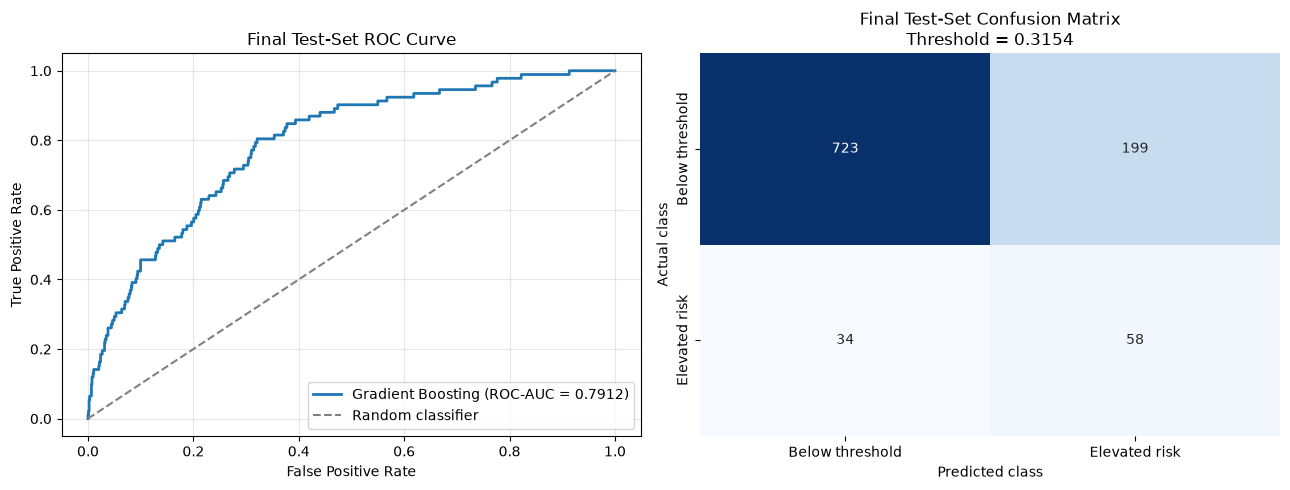

Final evaluation figure saved.
Saved location: ../reports/figures/final_gradient_boosting_evaluation.png
Model or threshold modified: False


In [109]:
# Create final test-set evaluation figures

from sklearn.metrics import roc_curve

figures_folder = Path("../reports/figures")
figures_folder.mkdir(parents=True, exist_ok=True)

final_figure_path = (
    figures_folder / "final_gradient_boosting_evaluation.png"
)

# Calculate ROC curve coordinates
false_positive_rate, true_positive_rate, _ = roc_curve(
    y_test,
    test_probabilities
)

# Create confusion matrix
final_confusion_matrix = confusion_matrix(
    y_test,
    test_predictions
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

# ROC curve
axes[0].plot(
    false_positive_rate,
    true_positive_rate,
    linewidth=2,
    label="Gradient Boosting (ROC-AUC = 0.7912)"
)

axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

axes[0].set_title("Final Test-Set ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# Confusion matrix
sns.heatmap(
    final_confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Below threshold", "Elevated risk"],
    yticklabels=["Below threshold", "Elevated risk"],
    ax=axes[1]
)

axes[1].set_title(
    "Final Test-Set Confusion Matrix\nThreshold = 0.3154"
)

axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("Actual class")

plt.tight_layout()

plt.savefig(
    final_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final evaluation figure saved.")
print(f"Saved location: {final_figure_path}")
print("Model or threshold modified: False")

## Conclusion

This project developed a machine-learning screening model using data from the National Health and Nutrition Examination Survey (NHANES). The dataset contained 5,068 participants, 29 predictors, and an elevated-risk prevalence of approximately 9.06%.

Ten classification models were developed, fine-tuned, evaluated with stratified cross-validation, checked for overfitting, and compared using consistent validation procedures. Numerical and categorical predictors were processed within model pipelines, and categorical variables were converted into dummy variables through one-hot encoding. The independent test set remained untouched until model selection was complete.

Gradient Boosting was selected as the final model because it achieved the highest validation ROC-AUC and F2 score among the finalists while maintaining reasonable generalization stability. Its classification threshold of 0.3154 was selected using out-of-fold training predictions and was not changed after test evaluation.

On the independent test set, the model achieved a ROC-AUC of 0.7912 and identified 58 of 92 elevated-risk participants. The model demonstrated moderate screening performance, but it should not be interpreted as a clinical diagnostic system.

### Limitations

- The target class was imbalanced, with only approximately 9.06% elevated-risk cases.
- The analysis used cross-sectional survey data and cannot establish causal relationships.
- Some predictors were based on self-reported responses and may contain reporting error.
- The model missed 34 of the 92 elevated-risk participants in the test set.
- The model has not been externally validated on another population or NHANES cycle.
- Predictions should support screening and follow-up decisions, not replace evaluation by a qualified healthcare professional.

### Final Outcome

The final deployment pipeline was refitted using all 5,068 participants and saved with the fixed threshold and all 29 predictors. The saved pipeline includes preprocessing and prediction logic required for integration into the Streamlit application.